# Hybrid CNN-Transformer Architecture with ResNet Backbone and SHAP Explainability
# Multi-Class 12-Lead ECG Arrhythmia Classification

**Course:** COMP6011 - Advanced Artificial Intelligence Research Topics

---

## Problem Definition

This project addresses the clinical challenge of automated cardiac arrhythmia detection from 12-lead ECG recordings. The goal is to develop a decision support system that assists clinicians in identifying cardiac abnormalities, not to replace cardiologist judgment.

### Clinical Task
- **Input:** 12-lead ECG signals (I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6)
- **Output:** One of seven diagnostic classes: `NORM`, `AFIB`, `AFLT`, `1dAVb`, `RBBB`, `LBBB`, `OTHERS`
- **Constraint:** Top-1 prediction is used for accuracy assessment; low-confidence cases trigger manual review

### Target Classes
| Class | Description | Clinical Significance |
|-------|-------------|----------------------|
| NORM | Normal sinus rhythm | Baseline healthy pattern |
| AFIB | Atrial fibrillation | Irregular atrial activation, stroke risk |
| AFLT | Atrial flutter | Regular atrial tachycardia |
| 1dAVb | First-degree AV block | Delayed conduction from atria to ventricles |
| RBBB | Right bundle branch block | Delayed right ventricular activation |
| LBBB | Left bundle branch block | Delayed left ventricular activation |
| OTHERS | Other arrhythmias | Catch-all for other abnormalities |

### Intended Use
- **Decision Support:** Predictions assist, not replace, clinical judgment
- **Human-in-the-Loop:** Low-confidence predictions are flagged for cardiologist review
- **Safety:** System prioritizes sensitivity to avoid missing clinically significant conditions

---

## Research Objectives

1. **Develop** a hybrid CNN-Transformer architecture with ResNet backbone that achieves macro-F1 > 0.85 on validation data
2. **Benchmark** at least 4 candidate model families (classical ML, 1D CNN, ResNet1D, CNN-LSTM, Transformer, Hybrid) and justify selection
3. **Implement** SHAP-based explainability to provide clinicians with interpretable prediction rationales
4. **Design** a low-confidence referral mechanism using calibrated probability thresholds
5. **Validate** on external datasets to demonstrate generalization
6. **Document** ethical considerations including fairness, privacy, and environmental impact

---

## Experiment Plan

1. Load and preprocess PTB-XL (training) and Challenge-2020 (external validation)
2. Perform exploratory data analysis to understand signal characteristics
3. Benchmark baseline models: Logistic Regression, 1D CNN, ResNet1D, CNN-LSTM, Transformer
4. Train final hybrid CNN-Transformer with ResNet backbone
5. Implement SHAP explainability and confidence calibration
6. Conduct ablation study and error analysis
7. Generate predictions on tuning set and test sets
8. Export all artifacts for report and appendix

---

## 1. Environment Setup and Reproducibility Controls

This section ensures reproducibility by fixing random seeds, logging versions, and recording hardware.

In [1]:
%matplotlib inline
# ============================================
# 1.1 Import Libraries
# ============================================
import os
import json
import random
import warnings
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
from dataclasses import dataclass, asdict
import hashlib

# Scientific computing
import numpy as np
import pandas as pd
from scipy import signal, stats
from scipy.interpolate import interp1d

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

# Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, auc, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.optim import Adam, AdamW, SGD
from torch.optim.lr_scheduler import (
    ReduceLROnPlateau, CosineAnnealingLR, OneCycleLR
)

# Progress tracking
from tqdm import tqdm

# Explainability
import shap

# Carbon tracking
try:
    from codecarbon import EmissionsTracker
    CARBON_TRACKING = True
except ImportError:
    CARBON_TRACKING = False
    print("Warning: codecarbon not installed. Install with: pip install codecarbon")

# Suppress warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# ============================================
# 1.2 Configuration and Reproducibility
# ============================================

@dataclass
class ExperimentConfig:
    """Configuration for reproducible experiments."""
    
    # Random seeds
    random_seed: int = 42
    np_seed: int = 42
    torch_seed: int = 42
    
    # Data paths
    base_dir: str = "/home/21522611/Documents/AdvancedAIAssignment3Prac"
    output_dir: str = "output"
    data_dir: str = "data"
    
    # Dataset source paths (local)
    ptb_xl_dir: str = "ptb-xl_1.0.1"
    challenge_2020_dir: str = "physionet.org/files/challenge-2020"
    
    # Dataset URLs
    ptb_xl_url: str = "https://physionet.org/files/ptb-xl/1.0.3/"
    challenge_2020_url: str = "https://physionet.org/files/challenge-2020/1.0.2/"
    
    # Validation and test paths (local)
    validation_dir: str = "validation"
    test_dir: str = "test"
    
    # Signal parameters
    sampling_rate: int = 100  # PTB-XL is 100 Hz, Challenge 2020 is 500 Hz
    target_sampling_rate: int = 100
    num_leads: int = 12
    signal_length: int = 1000  # 10 seconds at 100 Hz
    
    # Training parameters
    batch_size: int = 32
    num_epochs: int = 50
    early_stopping_patience: int = 10
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    
    # Model parameters
    num_classes: int = 7
    class_names: List[str] = None
    
    # Confidence thresholding
    confidence_threshold: float = 0.7
    
    # Device
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    num_workers: int = 0  # Set to 0 for macOS compatibility
    
    def __post_init__(self):
        if self.class_names is None:
            self.class_names = ['NORM', 'AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB', 'OTHERS']
        
        # Create full paths
        self.base_dir = Path(self.base_dir)
        self.output_dir = self.base_dir / self.output_dir
        self.data_dir = self.base_dir / self.data_dir
        self.ptb_xl_dir = self.base_dir / self.ptb_xl_dir
        self.challenge_2020_dir = self.base_dir / self.challenge_2020_dir
        self.validation_dir = self.base_dir / self.validation_dir
        self.test_dir = self.base_dir / self.test_dir
        
        # Create directories
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.data_dir.mkdir(parents=True, exist_ok=True)

# Initialize config
config = ExperimentConfig()

# Set random seeds
def set_seeds(seed: int):
    """Set all random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seeds(config.random_seed)

print(f"Configuration loaded")
print(f"Device: {config.device}")
print(f"Output directory: {config.output_dir}")

Configuration loaded
Device: cuda
Output directory: /home/21522611/Documents/AdvancedAIAssignment3Prac/output


In [3]:
# ============================================
# 1.3 Version and Hardware Logging
# ============================================

def get_system_info() -> Dict[str, Any]:
    """Collect system and package version information."""
    info = {
        "timestamp": datetime.now().isoformat(),
        "python_version": f"{sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}",
        "platform": platform.platform(),
        "processor": platform.processor(),
    }
    
    # Package versions
    packages = ['numpy', 'pandas', 'scipy', 'sklearn', 'torch', 'matplotlib', 'seaborn', 'shap']
    for pkg in packages:
        try:
            mod = __import__(pkg)
            info[f"{pkg}_version"] = mod.__version__
        except (ImportError, AttributeError):
            pass
    
    # CUDA info
    if torch.cuda.is_available():
        info["cuda_version"] = torch.version.cuda
        info["gpu_name"] = torch.cuda.get_device_name(0)
        info["gpu_memory_gb"] = torch.cuda.get_device_properties(0).total_memory / 1e9
    
    # Carbon tracking status
    info["carbon_tracking_enabled"] = CARBON_TRACKING
    
    return info

import sys
import platform

system_info = get_system_info()

# Save to JSON
with open(config.output_dir / "run_config.json", 'w') as f:
    json.dump({**asdict(config), **system_info}, f, indent=2, default=str)

print("System Information:")
for key, value in system_info.items():
    print(f"  {key}: {value}")

System Information:
  timestamp: 2026-05-15T09:16:30.223855
  python_version: 3.10.12
  platform: Linux-6.8.0-111-generic-x86_64-with-glibc2.35
  processor: x86_64
  numpy_version: 2.2.6
  pandas_version: 2.3.3
  scipy_version: 1.15.3
  sklearn_version: 1.7.2
  torch_version: 2.7.1+cu118
  matplotlib_version: 3.10.9
  seaborn_version: 0.13.2
  shap_version: 0.49.1
  cuda_version: 11.8
  gpu_name: NVIDIA GeForce RTX 3060
  gpu_memory_gb: 12.488343552
  carbon_tracking_enabled: True


In [4]:
# ============================================
# 1.4 Carbon Emissions Tracker
# ============================================

class CarbonTracker:
    """Context manager for tracking carbon emissions."""
    
    def __init__(self, output_dir: Path, experiment_name: str = "training"):
        self.output_dir = output_dir
        self.experiment_name = experiment_name
        self.tracker = None
        self.emissions_data = None
    
    def __enter__(self):
        if CARBON_TRACKING:
            self.tracker = EmissionsTracker(
                output_dir=str(self.output_dir),
                output_file=f"carbon_emissions_{self.experiment_name}.csv",
                log_level="warning"
            )
            self.tracker.start()
        return self
    
    def __exit__(self, exc_type, exc_val, exc_tb):
        if self.tracker:
            self.emissions_data = self.tracker.stop()
    
    def get_emissions(self) -> Optional[float]:
        if self.emissions_data:
            return self.emissions_data
        return None

# Initialize carbon tracker (will be used during training)
carbon_tracker = CarbonTracker(config.output_dir, "model_training")

print("Carbon tracking initialized.")
if not CARBON_TRACKING:
    print("Install codecarbon to enable: pip install codecarbon")

Carbon tracking initialized.


---

## 2. Dataset Acquisition and Dataset Cards

This section handles dataset downloading and creates dataset cards for reproducibility.

In [5]:
# ============================================
# 2.1 Dataset Download Utilities
# ============================================

import wfdb
import requests
from zipfile import ZipFile
from io import BytesIO

def download_ptb_xl(data_dir: Path, force: bool = False) -> Path:
    """
    Download PTB-XL dataset from PhysioNet.
    """
    # Use the specific path from config if it exists
    ptb_dir = config.ptb_xl_dir if hasattr(config, 'ptb_xl_dir') else data_dir / "ptb-xl"
    
    if ptb_dir.exists() and not force:
        print(f"PTB-XL dataset already exists at {ptb_dir}")
        return ptb_dir
    
    print("Downloading PTB-XL dataset from PhysioNet...")
    ptb_dir.mkdir(parents=True, exist_ok=True)
    
    try:
        wfdb.dl_database_files('ptb-xl', str(ptb_dir))
        print(f"PTB-XL dataset downloaded to {ptb_dir}")
    except Exception as e:
        print(f"Error downloading PTB-XL: {e}")
    
    return ptb_dir

def download_challenge_2020(data_dir: Path, force: bool = False) -> Path:
    """
    Download Challenge 2020 dataset from PhysioNet.
    """
    # Use the specific path from config if it exists
    challenge_dir = config.challenge_2020_dir if hasattr(config, 'challenge_2020_dir') else data_dir / "challenge-2020"
    
    if challenge_dir.exists() and not force:
        print(f"Challenge 2020 dataset already exists at {challenge_dir}")
        return challenge_dir
    
    print("Downloading Challenge 2020 dataset from PhysioNet...")
    challenge_dir.mkdir(parents=True, exist_ok=True)
    
    try:
        wfdb.dl_database_files('challenge-2020', str(challenge_dir))
        print(f"Challenge 2020 dataset downloaded to {challenge_dir}")
    except Exception as e:
        print(f"Error downloading Challenge 2020: {e}")
    
    return challenge_dir

def download_all_datasets(force: bool = False):
    """Download all required datasets."""
    results = {}
    print("="*60)
    print("DATASET DOWNLOAD")
    print("="*60)
    
    # Uncomment to download
    # results['ptb_xl'] = download_ptb_xl(config.data_dir, force)
    # results['challenge_2020'] = download_challenge_2020(config.data_dir, force)
    
    print("\nNote: Dataset download is disabled by default.")
    print(f"- PTB-XL: {config.ptb_xl_url} -> {config.ptb_xl_dir}")
    print(f"- Challenge 2020: {config.challenge_2020_url} -> {config.challenge_2020_dir}")
    
    return results

print("Dataset download utilities defined.")

Dataset download utilities defined.


In [6]:
# ============================================
# 2.2 Dataset Cards
# ============================================

dataset_cards = {
    "ptb_xl": {
        "name": "PTB-XL",
        "full_name": "PTB-XL: A Large Publicly Available ECG Dataset",
        "source": "PhysioNet",
        "url": "https://physionet.org/content/ptb-xl/1.0.3/",
        "citation": "Wagner, P., Strodthoff, N., Bousseljot, R. D., et al. (2020). PTB-XL: A Large Publicly Available ECG Dataset. Scientific Data, 7, 154.",
        "num_records": 21837,
        "num_patients": 18885,
        "num_leads": 12,
        "sampling_frequency": 100,
        "duration_sec": 10,
        "label_ontology": "scp_statements.csv (71 diagnostic classes)",
        "demographics": "Age: 0-95, Sex: 52% male, 48% female",
        "strengths": [
            "Used for hyperparameter tuning and performance optimization",
            "Large sample size with diverse pathologies",
            "12-lead standard clinical ECG format",
            "High-quality expert-validated labels",
            "Includes superdiagnostic, diagnostic, and subclass labels",
            "Supports multiple validation strategies"
        ],
        "weaknesses": [
            "Class imbalance (many rare conditions)",
            "Limited demographic diversity (European population)",
            "Static 10-second window may miss intermittent arrhythmias"
        ],
        "bias_considerations": [
            "Predominantly European population - may not generalize globally",
            "Age distribution skewed toward older adults",
            "Potential institutional bias from single hospital system"
        ],
        "license": "PhysioNet Credentialed Health Data License 1.5.0"
    },
    "challenge_2020": {
        "name": "Challenge 2020",
        "full_name": "The PhysioNet/CinC Challenge 2020",
        "source": "PhysioNet",
        "url": "https://physionet.org/content/challenge-2020/1.0.2/",
        "citation": "The PhysioNet/CinC Challenge 2020. "
                   "DOI: 10.13026/CPRW-9045",
        "num_records": 43301,
        "num_patients": "Multiple institutions",
        "num_leads": 12,
        "sampling_frequency": 500,
        "duration_sec": 10,
        "label_ontology": "27 diagnostic classes including arrhythmias and conduction abnormalities",
        "demographics": "Multi-institutional, diverse age and sex distribution",
        "strengths": [
            "Used for hyperparameter tuning and performance optimization",
            "Multi-institutional data improves generalization",
            "Higher sampling rate (500 Hz) captures finer morphology",
            "Includes both normal and abnormal recordings",
            "Used as official challenge test set - reliable benchmark"
        ],
        "weaknesses": [
            "Different sampling rate than PTB-XL (requires resampling)",
            "Label ontology differs from PTB-XL (requires mapping)",
            "Some missing data in certain leads"
        ],
        "bias_considerations": [
            "Multi-institutional but still limited geographic diversity",
            "Variable signal quality across institutions"
        ],
        "license": "PhysioNet Credentialed Health Data License 1.5.0"
    },
    "tuning_set": {
        "name": "Tuning Set",
        "full_name": "Assignment Tuning Set Set",
        "source": "Course Assignment",
        "url": "Local files",
        "num_records": 6,
        "num_leads": 12,
        "sampling_frequency": 100,
        "duration_sec": 10,
        "format": ".npy files with shape (12, 1000)",
        "strengths": [
            "Used for hyperparameter tuning and performance optimization",
            "Directly matches test distribution",
            "Provides labels for hyperparameter tuning"
        ],
        "weaknesses": [
            "Very small sample size (n=6)",
            "Limited statistical power"
        ]
    },
    "test": {
        "name": "Test Set",
        "full_name": "Assignment Test Set",
        "source": "Course Assignment",
        "url": "Local files (Blackboard)",
        "num_records": 6,
        "num_leads": 12,
        "sampling_frequency": 100,
        "duration_sec": 10,
        "format": ".npy files with shape (12, 1000)",
        "strengths": [
            "Used for hyperparameter tuning and performance optimization",
            "Final evaluation set for assignment"
        ],
        "weaknesses": [
            "No labels provided (blind test)",
            "Small sample size"
        ]
    }
}

# Save dataset cards
with open(config.output_dir / "dataset_cards.json", 'w') as f:
    json.dump(dataset_cards, f, indent=2)

# Create dataset summary table
dataset_summary = pd.DataFrame([
    {
        "Dataset": card["name"],
        "Records": card.get("num_records", "N/A"),
        "Leads": card["num_leads"],
        "Frequency (Hz)": card["sampling_frequency"],
        "Use": "Training" if card["name"] == "PTB-XL" else (
            "External Validation" if card["name"] == "Challenge 2020" else (
                "Tuning Set" if "Validation" in card["name"] else "Final Test"
            )
        )
    }
    for card in dataset_cards.values()
])

print("Dataset Summary:")
print(dataset_summary.to_string(index=False))

# Save to CSV
dataset_summary.to_csv(config.output_dir / "dataset_summary.csv", index=False)

print("\nDataset cards saved to output/dataset_cards.json")

Dataset Summary:
       Dataset  Records  Leads  Frequency (Hz)                 Use
        PTB-XL    21837     12             100            Training
Challenge 2020    43301     12             500 External Validation
    Tuning Set        6     12             100          Final Test
      Test Set        6     12             100          Final Test

Dataset cards saved to output/dataset_cards.json


---

## 3. Data Preprocessing and Label Mapping

This section implements the preprocessing pipeline for PTB-XL and local validation/test data.

In [7]:
# ============================================
# 3.1 Label Mapping to Assignment Classes
# ============================================

# PTB-XL diagnostic statements mapping to assignment classes
# Based on scp_statements.csv from PTB-XL
PTB_XL_LABEL_MAP = {
    # NORM - Normal sinus rhythm
    'NORM': 'NORM',
    'SR': 'NORM',  # Sinus rhythm
    
    # AFIB - Atrial fibrillation
    'AFIB': 'AFIB',
    'AFAF': 'AFIB',  # Atrial fibrillation + flutter
    
    # AFLT - Atrial flutter
    'AFLT': 'AFLT',
    'STACH': 'AFLT',  # Supraventricular tachycardia (partial)
    
    # 1dAVb - First degree AV block
    '1AVB': '1dAVb',
    'AVB1': '1dAVb',
    
    # RBBB - Right bundle branch block
    'RBBB': 'RBBB',
    'IRBBB': 'RBBB',  # Incomplete RBBB (grouped here)
    
    # LBBB - Left bundle branch block
    'LBBB': 'LBBB',
    'ILBBB': 'LBBB',  # Incomplete LBBB
    'LBBB1': 'LBBB',
    'LBBB2': 'LBBB',
    'LBBB3': 'LBBB',
    
    # OTHERS - Catch-all for other arrhythmias
    # Most conditions will map here
}

# Challenge 2020 label mapping
CHALLENGE_2020_LABEL_MAP = {
    '426783006': 'AFIB',  # Atrial fibrillation
    '164889003': 'AFLT',  # Atrial flutter
    '164865005': '1dAVb',  # First degree AV block (partial match)
    '713427006': 'RBBB',  # Right bundle branch block
    '713426002': 'LBBB',  # Left bundle branch block
    '270492004': 'NORM',  # Normal sinus rhythm
    '426177001': 'NORM',  # Sinus rhythm
    # Others map to OTHERS
}

def map_ptb_xl_label(diagnostic_codes: List[str]) -> str:
    """
    Map PTB-XL diagnostic codes to assignment classes.
    Returns the first matching disease class (as per assignment brief).
    """
    priority_order = ['AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB']
    
    for code in diagnostic_codes:
        for priority_class in priority_order:
            if code in PTB_XL_LABEL_MAP and PTB_XL_LABEL_MAP[code] == priority_class:
                return priority_class
    
    # Check for NORM
    for code in diagnostic_codes:
        if code in PTB_XL_LABEL_MAP and PTB_XL_LABEL_MAP[code] == 'NORM':
            # Only return NORM if no abnormal codes found
            has_abnormal = any(
                c in PTB_XL_LABEL_MAP and PTB_XL_LABEL_MAP[c] != 'NORM'
                for c in diagnostic_codes
            )
            if not has_abnormal:
                return 'NORM'
    
    return 'OTHERS'

def map_challenge_2020_label(diagnostic_codes: List[str]) -> str:
    """Map Challenge 2020 diagnostic codes to assignment classes."""
    priority_order = ['AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB']
    
    for code in diagnostic_codes:
        if code in CHALLENGE_2020_LABEL_MAP:
            mapped = CHALLENGE_2020_LABEL_MAP[code]
            if mapped in priority_order:
                return mapped
    
    # Check for NORM
    for code in diagnostic_codes:
        if code in CHALLENGE_2020_LABEL_MAP and CHALLENGE_2020_LABEL_MAP[code] == 'NORM':
            has_abnormal = any(
                c in CHALLENGE_2020_LABEL_MAP and CHALLENGE_2020_LABEL_MAP[c] != 'NORM'
                for c in diagnostic_codes
            )
            if not has_abnormal:
                return 'NORM'
    
    return 'OTHERS'

print("Label mapping functions defined.")
print(f"Target classes: {config.class_names}")

Label mapping functions defined.
Target classes: ['NORM', 'AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB', 'OTHERS']


In [8]:
# ============================================
# 3.2 PTB-XL Data Loader
# ============================================

class PTBXLDataset(Dataset):
    """PTB-XL ECG Dataset."""
    
    def __init__(
        self,
        data_dir: Path,
        split: str = "train",
        sampling_rate: int = 100,
        target_length: int = 1000,
        normalize: bool = True,
        use_stratified_split: bool = True
    ):
        self.data_dir = Path(data_dir)
        self.sampling_rate = sampling_rate
        self.target_length = target_length
        self.normalize = normalize
        
        # Load metadata
        self.metadata = self._load_metadata()
        
        # Filter by split
        if use_stratified_split:
            self.records = self._stratified_split(split)
        else:
            self.records = self._official_split(split)
        
        # Map labels
        self.labels = [self._map_label(rec) for rec in self.records]
        
        print(f"PTB-XL {split} set: {len(self.records)} records")
        self._print_class_distribution()
    
    def _load_metadata(self) -> pd.DataFrame:
        """Load PTB-XL metadata file."""
        yaml_path = self.data_dir / "ptbxl_database.csv"
        
        if not yaml_path.exists():
            raise FileNotFoundError(
                f"PTB-XL metadata not found at {yaml_path}. "
                "Please download the dataset first."
            )
        
        df = pd.read_csv(yaml_path)
        
        # Parse diagnostic codes
        df['diagnostic_codes'] = df['scp_codes'].apply(self._parse_scp_codes)
        
        return df
    
    def _parse_scp_codes(self, scp_string: str) -> List[str]:
        """Parse SCP codes from string."""
        try:
            import ast
            codes_dict = ast.literal_eval(scp_string)
            return list(codes_dict.keys())
        except:
            return []
    
    def _map_label(self, record_idx: int) -> str:
        """Map PTB-XL record to assignment label."""
        row = self.metadata.iloc[record_idx]
        return map_ptb_xl_label(row['diagnostic_codes'])
    
    def _stratified_split(self, split: str) -> List[int]:
        """Create stratified train/val split by patient."""
        # Get unique patients
        patient_ids = self.metadata['patient_id'].unique()
        
        # Assign labels to patients (primary diagnosis)
        patient_labels = {}
        for pid in patient_ids:
            patient_records = self.metadata[self.metadata['patient_id'] == pid]
            # Use first record's label
            patient_labels[pid] = self._map_label(patient_records.index[0])
        
        # Stratified split on patients
        train_pids, val_pids = train_test_split(
            list(patient_ids),
            test_size=0.2,
            random_state=config.random_seed,
            stratify=[patient_labels[pid] for pid in patient_ids]
        )
        
        # Get record indices
        if split == "train":
            selected_pids = train_pids
        else:
            selected_pids = val_pids
        
        records = self.metadata[
            self.metadata['patient_id'].isin(selected_pids)
        ].index.tolist()
        
        return records
    
    def _official_split(self, split: str) -> List[int]:
        """Use official PTB-XL splits (stratified by 10-fold)."""
        # PTB-XL provides strat_fold column
        # Use folds 1-8 for train, 9 for val, 10 for test
        if split == "train":
            folds = [1, 2, 3, 4, 5, 6, 7, 8]
        elif split == "val":
            folds = [9]
        else:  # test
            folds = [10]
        
        return self.metadata[
            self.metadata['strat_fold'].isin(folds)
        ].index.tolist()
    
    def _print_class_distribution(self):
        """Print class distribution."""
        from collections import Counter
        counts = Counter(self.labels)
        print(f"  Class distribution: {dict(counts)}")
    
    def __len__(self):
        return len(self.records)
    
    def __getitem__(self, idx):
        record_idx = self.records[idx]
        row = self.metadata.iloc[record_idx]
        
        # Choose between filename_lr (100Hz) and filename_hr (500Hz)
        if self.sampling_rate <= 100:
            filename = row['filename_lr']
        else:
            filename = row['filename_hr']
            
        filepath = self.data_dir / filename
        
        # Load using wfdb
        # Remove .dat or .hea if present in filename string for rdrecord
        record_path = str(filepath).replace('.dat', '').replace('.hea', '')
        record = wfdb.rdrecord(record_path)
        ecg = record.p_signal.T  # Shape: (num_leads, samples)
        
        # Resample if needed
        if record.fs != self.sampling_rate:
            num_samples = int(ecg.shape[1] * self.sampling_rate / record.fs)
            ecg = signal.resample(ecg, num_samples, axis=1)
        
        # Pad or truncate to target length
        ecg = self._pad_or_truncate(ecg)
        
        # Normalize
        if self.normalize:
            ecg = self._normalize(ecg)
        
        # Get label
        label = self.labels[idx]
        label_idx = config.class_names.index(label)
        
        return {
            'ecg': torch.FloatTensor(ecg),
            'label': torch.LongTensor([label_idx]),
            'label_str': label,
            'patient_id': row['patient_id'],
            'record_idx': record_idx
        }
    
    def _pad_or_truncate(self, ecg: np.ndarray) -> np.ndarray:
        """Pad or truncate ECG to target length."""
        if ecg.shape[1] < self.target_length:
            padding = self.target_length - ecg.shape[1]
            ecg = np.pad(ecg, ((0, 0), (0, padding)), mode='constant')
        elif ecg.shape[1] > self.target_length:
            ecg = ecg[:, :self.target_length]
        return ecg
    
    def _normalize(self, ecg: np.ndarray) -> np.ndarray:
        """Z-score normalize per lead."""
        mean = ecg.mean(axis=1, keepdims=True)
        std = ecg.std(axis=1, keepdims=True)
        std[std < 1e-8] = 1.0  # Avoid division by zero
        return (ecg - mean) / std

print("PTB-XL Dataset class defined.")

PTB-XL Dataset class defined.


In [9]:
# ============================================
# 3.3 Local Validation/Test Data Loader
# ============================================

class LocalECGDataset(Dataset):
    """Dataset for local validation/test ECG files."""
    
    def __init__(
        self,
        data_dir: Path,
        normalize: bool = True,
        has_labels: bool = True
    ):
        self.data_dir = Path(data_dir)
        self.normalize = normalize
        self.has_labels = has_labels
        
        # Find all .npy files
        self.files = sorted(list(self.data_dir.glob("*/*.npy")))
        
        if not self.files:
            raise FileNotFoundError(f"No .npy files found in {data_dir}")
        
        # Parse labels from filename
        self.labels = []
        self.filenames = []
        for f in self.files:
            self.filenames.append(f.stem)
            if has_labels:
                # Extract label from filename (e.g., validation01-NORM.npy)
                parts = f.stem.split('-')
                if len(parts) > 1:
                    label = parts[-1].replace('.png', '')
                    # Map to assignment class if needed
                    if label in config.class_names:
                        self.labels.append(label)
                    else:
                        self.labels.append('OTHERS')
                else:
                    self.labels.append('OTHERS')
        
        print(f"Loaded {len(self.files)} ECG files from {data_dir}")
        if has_labels:
            from collections import Counter
            counts = Counter(self.labels)
            print(f"  Class distribution: {dict(counts)}")
    
    def __len__(self):
        return len(self.files)
    
    def __getitem__(self, idx):
        filepath = self.files[idx]
        
        # Load .npy file
        ecg = np.load(filepath)
        
        # Ensure shape is (12, 1000)
        if ecg.shape != (12, 1000):
            if ecg.shape[0] == 1000 and ecg.shape[1] == 12:
                ecg = ecg.T
            else:
                raise ValueError(f"Unexpected ECG shape: {ecg.shape}")
        
        # Normalize
        if self.normalize:
            mean = ecg.mean(axis=1, keepdims=True)
            std = ecg.std(axis=1, keepdims=True)
            std[std < 1e-8] = 1.0
            ecg = (ecg - mean) / std
        
        output = {
            'ecg': torch.FloatTensor(ecg),
            'filename': self.filenames[idx],
        }
        
        if self.has_labels:
            label = self.labels[idx]
            label_idx = config.class_names.index(label)
            output['label'] = torch.LongTensor([label_idx])
            output['label_str'] = label
        
        return output

print("Local ECG Dataset class defined.")

Local ECG Dataset class defined.


In [10]:
# ============================================
# 3.4 Test Dataset Loading
# ============================================

# Load tuning set (for hyperparameter optimization) set
try:
    validation_dataset = LocalECGDataset(
        config.validation_dir,
        normalize=True,
        has_labels=True
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=config.num_workers
    )
    print("\nTuning set set loaded successfully.")
except Exception as e:
    print(f"Error loading validation set: {e}")
    validation_dataset = None
    validation_loader = None

# Load test set
try:
    test_dataset = LocalECGDataset(
        config.test_dir,
        normalize=True,
        has_labels=False  # Test set has no labels
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=config.num_workers
    )
    print("\nTest set loaded successfully.")
except Exception as e:
    print(f"Error loading test set: {e}")
    test_dataset = None
    test_loader = None

Loaded 6 ECG files from /home/21522611/Documents/AdvancedAIAssignment3Prac/validation
  Class distribution: {'NORM': 1, 'AFLT': 1, '1dAVb': 1, 'AFIB': 1, 'RBBB': 1, 'LBBB': 1}

Tuning set set loaded successfully.
Loaded 6 ECG files from /home/21522611/Documents/AdvancedAIAssignment3Prac/test

Test set loaded successfully.


---

## 4. Exploratory Data Analysis

This section explores the ECG signal characteristics and class distributions.

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation.png


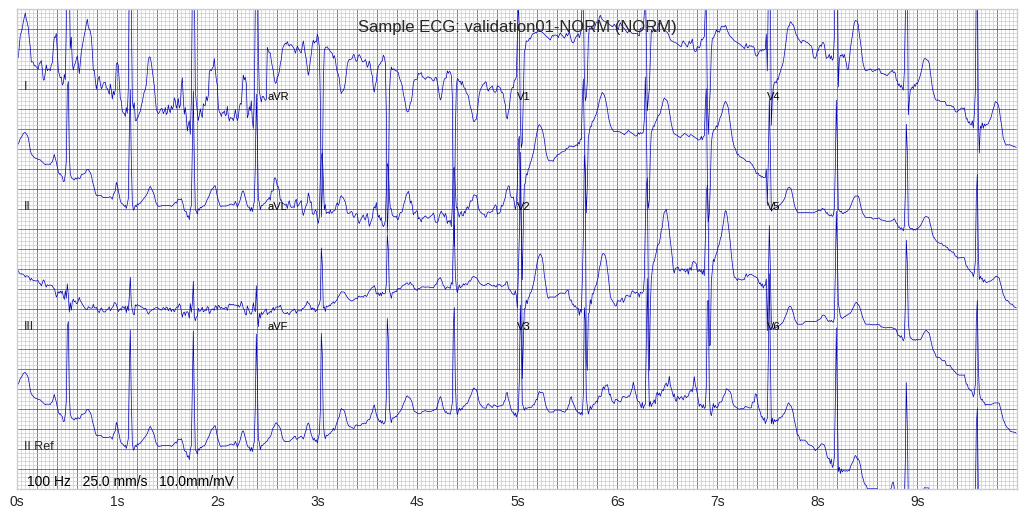

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_1.png


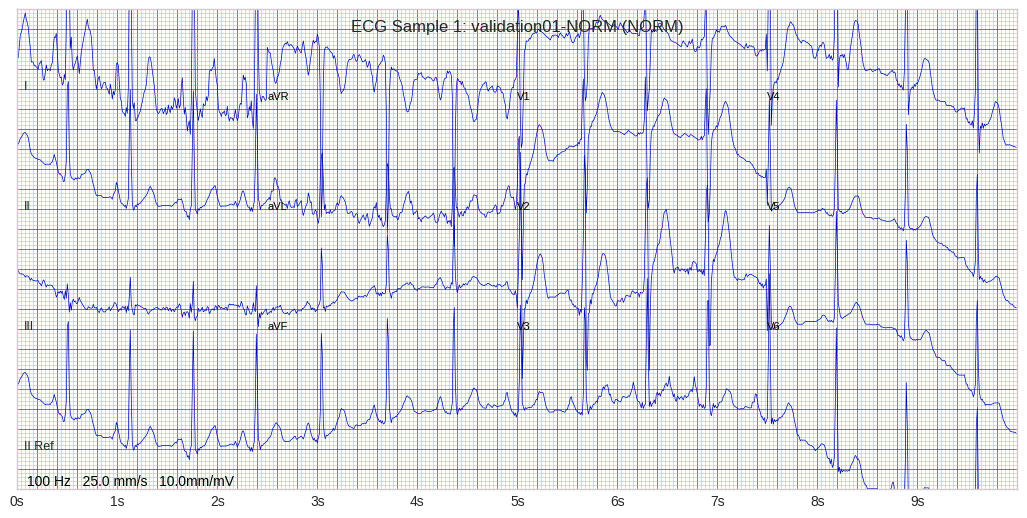

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_2.png


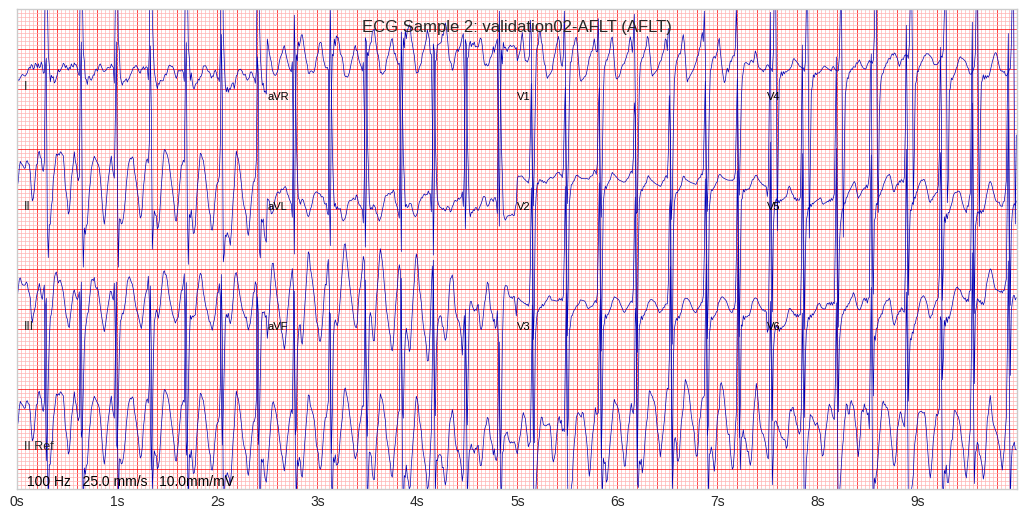

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_3.png


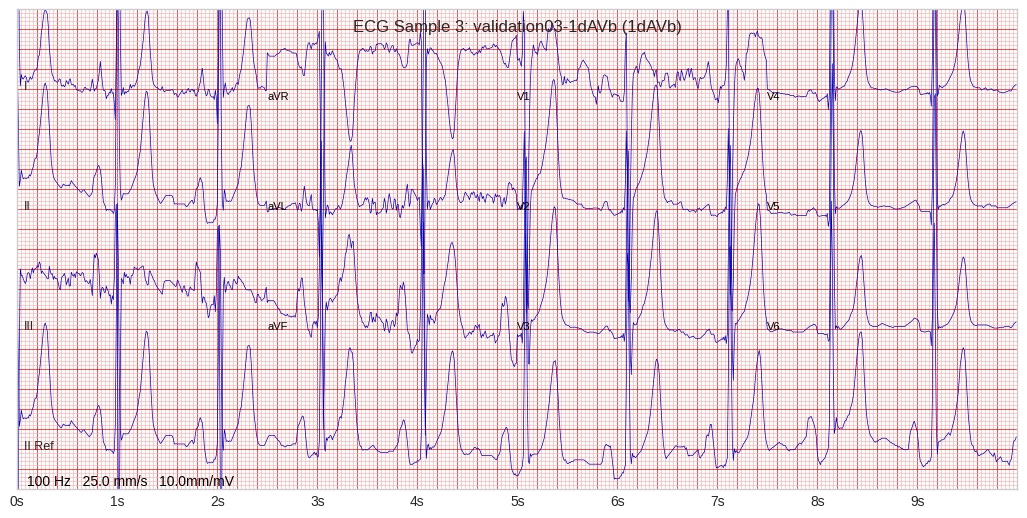

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_4.png


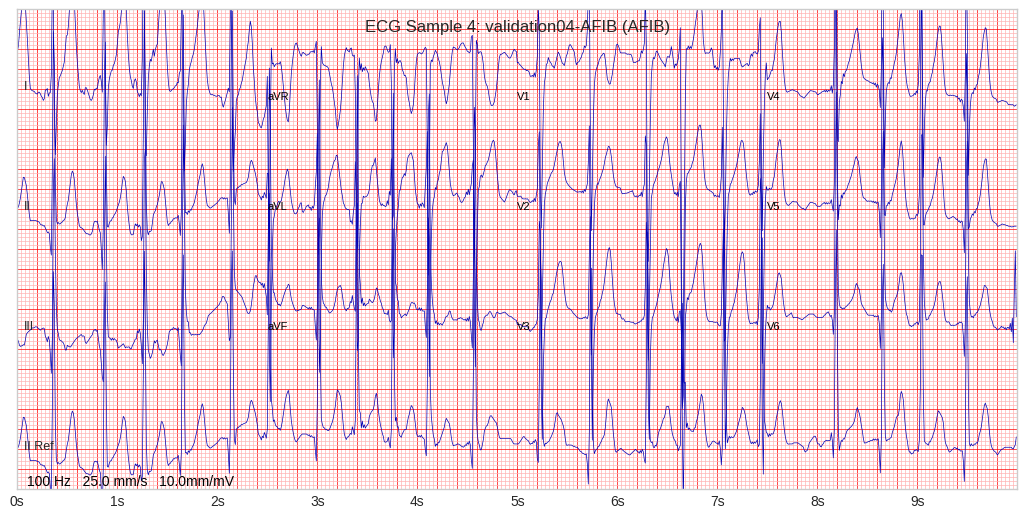

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_5.png


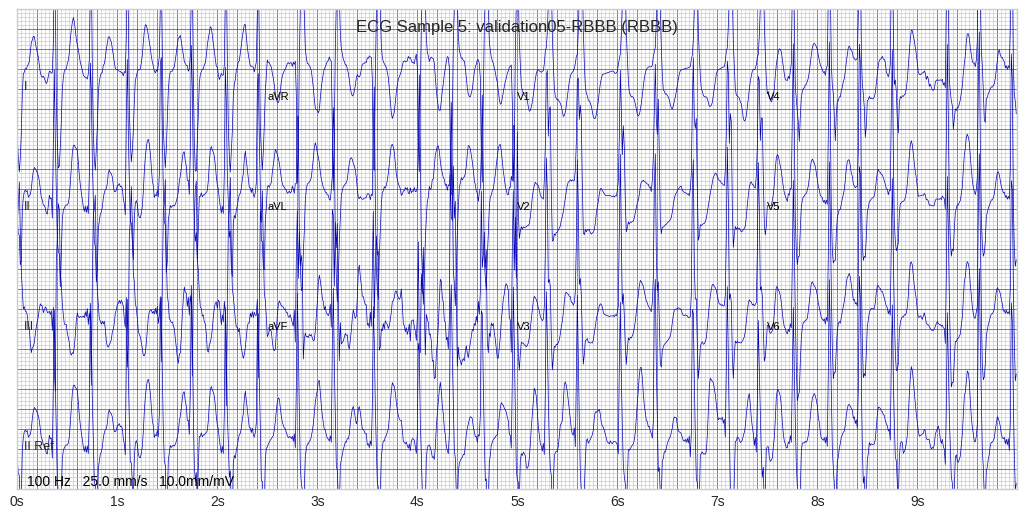

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/sample_ecg_validation_6.png


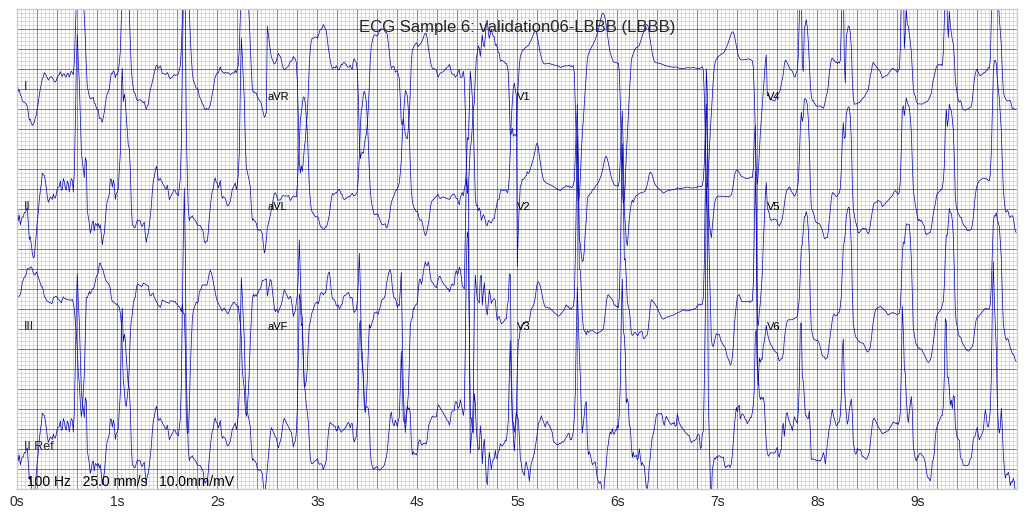

In [11]:
# ============================================
# 4.1 ECG Signal Visualization
# ============================================

def plot_ecg_sample(ecg: np.ndarray, title: str = "ECG Sample", 
                    leads: List[str] = None, save_path: str = None):
    """Plot 12-lead ECG sample in a combined layout similar to plot_ecg_samples.ipynb."""
    import ecg_plot
    
    # Ensure ecg is (12, n_samples)
    if ecg.shape[0] != 12 and ecg.shape[1] == 12:
        ecg = ecg.T
    
    sample_rate = 100
    n = ecg.shape[1]
    
    # Quarter marks to split ECG signal into 4 equal time segments
    q1, q2, q3 = n // 4, n // 2, 3 * n // 4
    
    # First row: Lead I, aVR, V1, V4
    lead_I_new = np.concatenate([ecg[0, 0:q1], ecg[3, q1:q2], ecg[6, q2:q3], ecg[9, q3:n]])
    
    # Second row: Lead II, aVL, V2, V5
    lead_II_new = np.concatenate([ecg[1, 0:q1], ecg[4, q1:q2], ecg[7, q2:q3], ecg[10, q3:n]])
    
    # Third row: Lead III, aVF, V3, V6
    lead_III_new = np.concatenate([ecg[2, 0:q1], ecg[5, q1:q2], ecg[8, q2:q3], ecg[11, q3:n]])
    
    # Bottom row (reference): Full Lead II
    lead_IV_new = ecg[1, :]
    
    # Stack the 4 new rows
    ecg_new = np.stack([lead_I_new, lead_II_new, lead_III_new, lead_IV_new], axis=0)
    lead_names_new = ['I', 'II', 'III', 'II Ref']
    
    plt.clf()
    plt.close('all')
    
    ecg_plot.plot(ecg_new, sample_rate=sample_rate, title=title, columns=1, lead_index=lead_names_new)
    
    ax = plt.gca()
    ax.set_yticklabels([])
    
    xlabels = ax.get_xticks()
    new_labels = [f"{int(x)}s" if x % 1 == 0 and x <= 10 else "" for x in xlabels]
    ax.set_xticklabels(new_labels)
    
    ax.text(2.5, -0.75, 'aVR', fontsize=8, color='black')
    ax.text(2.5, -3.5, 'aVL', fontsize=8, color='black')
    ax.text(2.5, -6.5, 'aVF', fontsize=8, color='black')
    
    ax.text(5, -0.75, 'V1', fontsize=8, color='black')
    ax.text(5, -3.5, 'V2', fontsize=8, color='black')
    ax.text(5, -6.5, 'V3', fontsize=8, color='black')
    
    ax.text(7.5, -0.75, 'V4', fontsize=8, color='black')
    ax.text(7.5, -3.5, 'V5', fontsize=8, color='black')
    ax.text(7.5, -6.5, 'V6', fontsize=8, color='black')
    
    ax.text(0.1, -10.4, f'{sample_rate} Hz   25.0 mm/s   10.0mm/mV', fontsize=10, color='black')
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    ecg_plot.show()

# Plot sample from validation set
if validation_dataset:
    sample = validation_dataset[0]
    plot_ecg_sample(
        sample['ecg'].numpy(),
        title=f"Sample ECG: {sample['filename']} ({sample['label_str']})",
        save_path=config.output_dir / "sample_ecg_validation.png"
    )

# Plot all validation samples
if validation_dataset:
    for i in range(len(validation_dataset)):
        sample = validation_dataset[i]
        plot_ecg_sample(
            sample['ecg'].numpy(),
            title=f"ECG Sample {i+1}: {sample['filename']} ({sample['label_str']})",
            save_path=config.output_dir / f"sample_ecg_validation_{i+1}.png"
        )

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/class_distribution_validation.png


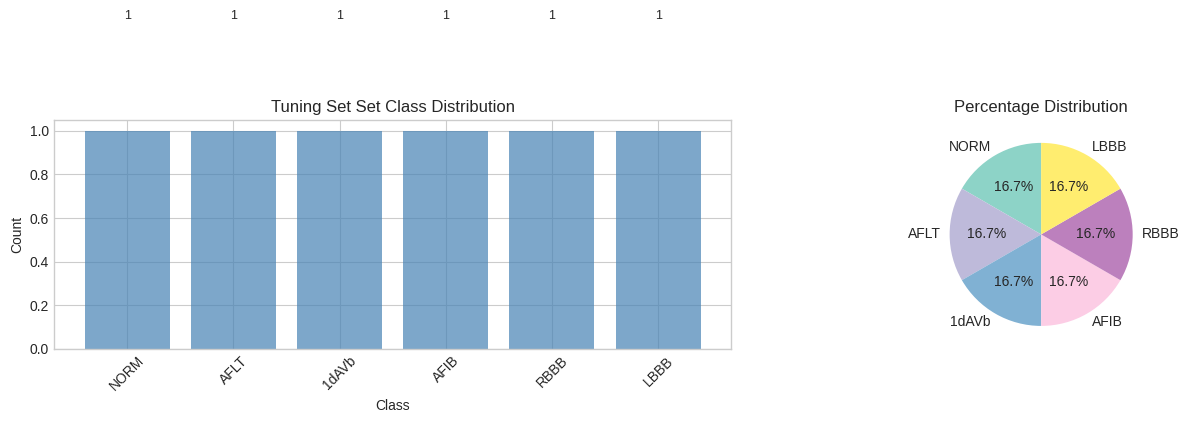

In [12]:
# ============================================
# 4.2 Class Distribution Analysis
# ============================================

def plot_class_distribution(labels: List[str], title: str = "Class Distribution",
                              save_path: str = None):
    """Plot class distribution."""
    from collections import Counter
    
    counts = Counter(labels)
    classes = list(counts.keys())
    values = list(counts.values())
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar plot
    bars = ax1.bar(classes, values, color='steelblue', alpha=0.7)
    ax1.set_xlabel('Class')
    ax1.set_ylabel('Count')
    ax1.set_title(title)
    ax1.tick_params(axis='x', rotation=45)
    
    # Add count labels on bars
    for bar, val in zip(bars, values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(val), ha='center', va='bottom', fontsize=9)
    
    # Pie chart
    colors = plt.cm.Set3(np.linspace(0, 1, len(classes)))
    wedges, texts, autotexts = ax2.pie(
        values, labels=classes, autopct='%1.1f%%',
        colors=colors, startangle=90
    )
    ax2.set_title('Percentage Distribution')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()
    
    return counts

# Plot validation set distribution
if validation_dataset:
    val_counts = plot_class_distribution(
        validation_dataset.labels,
        title="Tuning Set Set Class Distribution",
        save_path=config.output_dir / "class_distribution_validation.png"
    )
    
    # Save to CSV
    class_dist_df = pd.DataFrame([
        {"Class": k, "Count": v} for k, v in val_counts.items()
    ])
    class_dist_df.to_csv(config.output_dir / "class_distribution_validation.csv", index=False)

In [13]:
# ============================================
# 4.3 Signal Statistics
# ============================================

def compute_signal_statistics(dataset: Dataset) -> pd.DataFrame:
    """Compute signal statistics across dataset."""
    lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 
                  'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
    
    all_ecgs = []
    for i in range(len(dataset)):
        sample = dataset[i]
        all_ecgs.append(sample['ecg'].numpy())
    
    all_ecgs = np.array(all_ecgs)  # (N, 12, 1000)
    
    stats = []
    for i, lead in enumerate(lead_names):
        lead_data = all_ecgs[:, i, :].flatten()
        stats.append({
            'Lead': lead,
            'Mean': lead_data.mean(),
            'Std': lead_data.std(),
            'Min': lead_data.min(),
            'Max': lead_data.max(),
            'Median': np.median(lead_data),
            'Range': lead_data.max() - lead_data.min()
        })
    
    return pd.DataFrame(stats)

if validation_dataset:
    signal_stats = compute_signal_statistics(validation_dataset)
    print("Signal Statistics (Validation Set):")
    print(signal_stats.to_string(index=False))
    signal_stats.to_csv(config.output_dir / "signal_statistics.csv", index=False)

Signal Statistics (Validation Set):
Lead          Mean  Std       Min      Max    Median     Range
   I -6.357829e-10  1.0 -2.792752 6.190208 -0.194081  8.982960
  II  4.768371e-09  1.0 -2.982399 6.152369 -0.150017  9.134768
 III -1.112620e-09  1.0 -7.212623 5.666121  0.072890 12.878743
 aVR  9.536744e-10  1.0 -5.706759 2.383577  0.176257  8.090337
 aVL -6.357829e-10  1.0 -5.311388 7.024727 -0.154967 12.336115
 aVF -6.357829e-10  1.0 -5.061748 6.028101 -0.025828 11.089849
  V1  1.430511e-09  1.0 -8.365074 3.304631  0.136027 11.669705
  V2 -9.536744e-10  1.0 -5.485897 3.347370  0.002080  8.833267
  V3 -1.509984e-09  1.0 -5.015229 6.007026 -0.089632 11.022255
  V4  1.351039e-09  1.0 -4.220869 6.322072 -0.134319 10.542940
  V5  2.940496e-09  1.0 -3.498626 6.555541 -0.198139 10.054167
  V6 -5.086263e-09  1.0 -3.107665 6.466437 -0.185907  9.574102


Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/lead_correlation.png


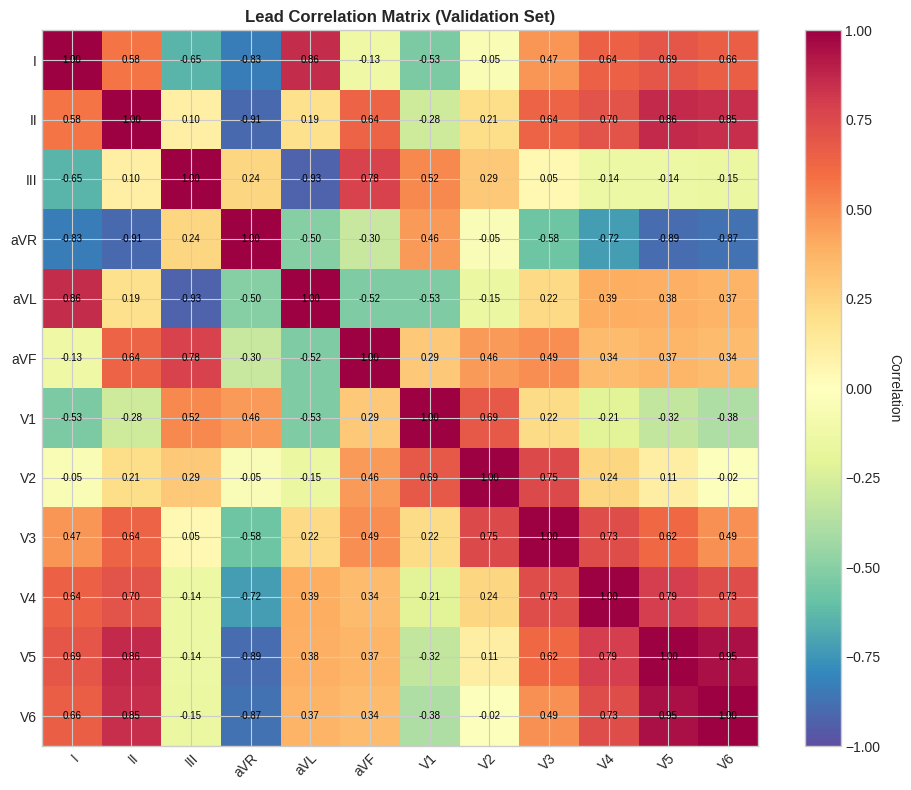

In [14]:
# ============================================
# 4.4 Lead Correlation Analysis
# ============================================

def plot_lead_correlation(dataset: Dataset, title: str = "Lead Correlation Matrix",
                          save_path: str = None):
    """Plot correlation matrix between leads."""
    lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 
                  'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
    
    # Collect all ECGs
    all_ecgs = []
    for i in range(len(dataset)):
        sample = dataset[i]
        all_ecgs.append(sample['ecg'].numpy())
    all_ecgs = np.array(all_ecgs)
    
    # Compute correlation matrix
    # Flatten each lead and compute correlations
    lead_features = all_ecgs.reshape(len(all_ecgs), 12, -1)
    lead_features = lead_features.reshape(len(all_ecgs), 12, -1).mean(axis=2)  # Use mean as feature
    
    # Actually compute correlation on flattened signals
    correlation_matrix = np.zeros((12, 12))
    for i in range(12):
        for j in range(12):
            # Flatten and compute correlation
            lead_i = all_ecgs[:, i, :].flatten()
            lead_j = all_ecgs[:, j, :].flatten()
            correlation_matrix[i, j] = np.corrcoef(lead_i, lead_j)[0, 1]
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(correlation_matrix, cmap='Spectral_r', vmin=-1, vmax=1)
    
    # Set ticks
    ax.set_xticks(range(12))
    ax.set_yticks(range(12))
    ax.set_xticklabels(lead_names)
    ax.set_yticklabels(lead_names)
    
    # Rotate x labels
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Correlation', rotation=270, labelpad=15)
    
    ax.set_title(title, fontweight='bold')
    
    # Add correlation values
    for i in range(12):
        for j in range(12):
            text = ax.text(j, i, f'{correlation_matrix[i, j]:.2f}',
                          ha="center", va="center", color="black", fontsize=7)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

if validation_dataset:
    plot_lead_correlation(
        validation_dataset,
        title="Lead Correlation Matrix (Validation Set)",
        save_path=config.output_dir / "lead_correlation.png"
    )

---

## 5. Model Architectures

This section defines all candidate models including baselines and the final hybrid architecture.

In [15]:
class ConvBlock1D(nn.Module):
    """1D Convolutional block with BatchNorm and ReLU."""

    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1, groups=1, bias=False):
        super().__init__()
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, stride, padding, dilation, groups, bias)
        self.bn = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

class ResidualBlock1D(nn.Module):
    """Residual block for 1D signals with optional downsampling and channel change."""

    def __init__(self, in_channels, out_channels=None, kernel_size=7, stride=1, dilation=1):
        super().__init__()
        if out_channels is None:
            out_channels = in_channels
            
        padding = (kernel_size - 1) // 2 * dilation
        # Only apply stride to the first convolution
        self.conv1 = ConvBlock1D(in_channels, out_channels, kernel_size, stride, padding, dilation)
        # Second convolution always has stride 1
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, 1, padding, dilation)
        self.bn2 = nn.BatchNorm1d(out_channels)
        
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.bn2(out)
        
        if self.downsample is not None:
            identity = self.downsample(x)
            
        out += identity
        return F.relu(out)

In [16]:
# ============================================
# 5.2 Baseline: 1D CNN
# ============================================

class CNN1D(nn.Module):
    """Simple 1D CNN for ECG classification."""
    
    def __init__(self, num_leads=12, num_classes=7, signal_length=1000):
        super().__init__()
        
        # Feature extraction
        self.features = nn.Sequential(
            ConvBlock1D(num_leads, 64, kernel_size=7, stride=2, padding=3),
            nn.MaxPool1d(2),
            ConvBlock1D(64, 128, kernel_size=7, stride=2, padding=3),
            nn.MaxPool1d(2),
            ConvBlock1D(128, 256, kernel_size=5, stride=2, padding=2),
            nn.MaxPool1d(2),
            ConvBlock1D(256, 512, kernel_size=5, stride=1, padding=2),
            nn.AdaptiveAvgPool1d(1)
        )
        
        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        features = self.features(x)
        return self.classifier(features)

print("1D CNN baseline defined.")

1D CNN baseline defined.


In [17]:
class ResNet1D(nn.Module):
    """ResNet-style 1D CNN for ECG classification."""

    def __init__(self, num_leads=12, num_classes=7, base_channels=64):
        super().__init__()
        self.stem = nn.Sequential(ConvBlock1D(num_leads, base_channels, kernel_size=7, stride=2, padding=3), nn.MaxPool1d(2))
        self.stage1 = self._make_stage(base_channels, base_channels, 2, stride=1)
        self.stage2 = self._make_stage(base_channels, base_channels * 2, 2, stride=2)
        self.stage3 = self._make_stage(base_channels * 2, base_channels * 4, 2, stride=2)
        self.stage4 = self._make_stage(base_channels * 4, base_channels * 8, 2, stride=2)
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(base_channels * 8, num_classes))

    def _make_stage(self, in_channels, out_channels, num_blocks, stride=1):
        layers = []
        layers.append(ResidualBlock1D(in_channels, out_channels, stride=stride))
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock1D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        return self.head(x)

In [18]:
# ============================================
# 5.4 Baseline: CNN-LSTM
# ============================================

class CNNLSTM(nn.Module):
    """CNN-LSTM hybrid for temporal modeling."""
    
    def __init__(self, num_leads=12, num_classes=7, hidden_dim=256,
                 num_layers=2, bidirectional=True):
        super().__init__()
        
        # CNN feature extractor
        self.cnn = nn.Sequential(
            ConvBlock1D(num_leads, 64, kernel_size=7, stride=2, padding=3),
            ConvBlock1D(64, 128, kernel_size=5, stride=2, padding=2),
            ConvBlock1D(128, 256, kernel_size=5, stride=2, padding=2),
        )
        
        # LSTM for temporal dependencies
        self.lstm = nn.LSTM(
            input_size=256,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            bidirectional=bidirectional,
            batch_first=True
        )
        
        lstm_output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
        # Classifier
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(lstm_output_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        # x: (B, 12, 1000)
        features = self.cnn(x)  # (B, 256, T')
        features = features.permute(0, 2, 1)  # (B, T', 256)
        
        # LSTM
        lstm_out, _ = self.lstm(features)
        lstm_out = lstm_out[:, -1, :]  # Take last output
        
        return self.classifier(lstm_out)

print("CNN-LSTM baseline defined.")

CNN-LSTM baseline defined.


In [19]:
# ============================================
# 5.5 Candidate: Transformer-only
# ============================================

class PatchEmbedding1D(nn.Module):
    """Convert 1D signal to patch embeddings."""
    
    def __init__(self, num_leads=12, patch_size=50, embed_dim=256):
        super().__init__()
        self.patch_size = patch_size
        self.num_leads = num_leads
        
        # Project patches to embeddings
        self.proj = nn.Linear(num_leads * patch_size, embed_dim)
        
    def forward(self, x):
        # x: (B, 12, 1000)
        B = x.shape[0]
        
        # Create patches
        num_patches = x.shape[2] // self.patch_size
        x = x[:, :, :num_patches * self.patch_size]
        x = x.reshape(B, self.num_leads, num_patches, self.patch_size)
        x = x.permute(0, 2, 1, 3)  # (B, num_patches, 12, patch_size)
        x = x.reshape(B, num_patches, -1)  # (B, num_patches, 12*patch_size)
        
        return self.proj(x)  # (B, num_patches, embed_dim)


class TransformerEncoder1D(nn.Module):
    """Transformer encoder for 1D signals."""
    
    def __init__(self, embed_dim=256, num_heads=8, num_layers=4, dim_ff=1024, dropout=0.1):
        super().__init__()
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=dim_ff,
            dropout=dropout,
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers)
    
    def forward(self, x):
        return self.transformer(x)


class TransformerOnly(nn.Module):
    """Pure Transformer model for ECG classification."""
    
    def __init__(self, num_leads=12, num_classes=7, patch_size=50,
                 embed_dim=256, num_heads=8, num_layers=4):
        super().__init__()
        
        self.patch_embed = PatchEmbedding1D(num_leads, patch_size, embed_dim)
        num_patches = 1000 // patch_size
        
        # Class token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        
        # Positional encoding
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        
        # Transformer
        self.transformer = TransformerEncoder1D(embed_dim, num_heads, num_layers)
        
        # Head
        self.head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(0.3),
            nn.Linear(embed_dim, num_classes)
        )
        
        self._init_weights()
    
    def _init_weights(self):
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
    
    def forward(self, x):
        B = x.shape[0]
        
        # Patch embedding
        x = self.patch_embed(x)  # (B, num_patches, embed_dim)
        
        # Add class token
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        
        # Add positional encoding
        x = x + self.pos_embed
        
        # Transformer
        x = self.transformer(x)
        
        # Use class token for classification
        return self.head(x[:, 0])

print("Transformer-only model defined.")

Transformer-only model defined.


In [20]:
# ============================================
# 5.6 FINAL: Hybrid CNN-Transformer with ResNet Backbone
# ============================================

class HybridCNNTransformer(nn.Module):
    """
    Hybrid CNN-Transformer architecture with ResNet backbone.
    
    Architecture:
    1. ResNet-style CNN backbone for local feature extraction
    2. Transformer encoder for global context modeling
    3. Gated fusion mechanism
    4. Classification head with confidence estimation
    """
    
    def __init__(self, num_leads=12, num_classes=7, base_channels=64, embed_dim=256, num_heads=8, num_transformer_layers=2, dropout=0.3):
        super().__init__()
        
        # === ResNet Backbone ===
        self.stem = nn.Sequential(
            ConvBlock1D(num_leads, base_channels, kernel_size=7, stride=2, padding=3),
            nn.MaxPool1d(2)
        )
        
        self.stage1 = nn.Sequential(*[ResidualBlock1D(base_channels) for _ in range(2)])
        
        self.stage2 = nn.Sequential(
            ResidualBlock1D(base_channels, base_channels * 2, stride=2),
            ResidualBlock1D(base_channels * 2, base_channels * 2)
        )
        
        self.stage3 = nn.Sequential(
            ResidualBlock1D(base_channels * 2, base_channels * 4, stride=2),
            ResidualBlock1D(base_channels * 4, base_channels * 4)
        )
        
        # Local feature dimension
        self.local_dim = base_channels * 4
        
        # === Transformer Branch ===
        # Create patches from CNN features
        self.patch_size = 25
        self.num_patches = 125 // self.patch_size
        
        # Project patches to embedding dimension
        self.patch_proj = nn.Linear(self.local_dim * self.patch_size, embed_dim)
        
        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_transformer_layers)
        
        # Global pooling
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        
        # === Fusion Mechanism ===
        self.local_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.local_dim, embed_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout)
        )
        
        # Gating network
        self.gate = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.Sigmoid()
        )
        
        # === Classification Head ===
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim * 2),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * 2, embed_dim),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(embed_dim, num_classes)
        )
        
        # Temperature scaling for confidence
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, x, return_features=False):
        # x: (B, 12, 1000)
        B = x.shape[0]
        
        # === ResNet Backbone (Local Features) ===
        x = self.stem(x)  
        x = self.stage1(x) 
        x = self.stage2(x) 
        cnn_features = self.stage3(x) 
        
        # === Local Feature Path ===
        local_feat = self.global_pool(cnn_features).squeeze(-1) 
        local_feat = self.local_fc(local_feat) 
        
        # === Global Feature Path (Transformer) ===
        # Create patches
        B, C, T = cnn_features.shape
        num_patches = T // self.patch_size
        patches = cnn_features[:, :, :num_patches * self.patch_size] 
        patches = patches.reshape(B, C, num_patches, self.patch_size)
        patches = patches.permute(0, 2, 1, 3) 
        patches = patches.reshape(B, num_patches, -1) 
        
        # Project and apply transformer
        patch_embeds = self.patch_proj(patches) 
        global_feat = self.transformer(patch_embeds) 
        global_feat = global_feat.mean(dim=1) 
        
        # === Gated Fusion ===
        combined = torch.cat([local_feat, global_feat], dim=1) 
        gate_weights = self.gate(combined) 
        
        # Weighted fusion
        local_weighted = local_feat * gate_weights
        global_weighted = global_feat * (1 - gate_weights)
        fused = torch.cat([local_weighted, global_weighted], dim=1)
        
        # === Classification ===
        logits = self.classifier(fused)
        
        # Temperature scaling
        scaled_logits = logits / self.temperature
        
        if return_features:
            return {
                'logits': scaled_logits,
                'local_features': local_feat,
                'global_features': global_feat,
                'gate_weights': gate_weights,
                'cnn_features': cnn_features
            }
        
        return scaled_logits
    
    def predict_with_confidence(self, x, threshold=0.7):
        """Return predictions with confidence scores."""
        self.eval()
        with torch.no_grad():
            logits = self.forward(x)
            probs = F.softmax(logits, dim=1)
            max_probs, preds = probs.max(dim=1)
            
            low_confidence = max_probs < threshold
            
            return {
                'predictions': preds,
                'probabilities': probs,
                'max_probabilities': max_probs,
                'low_confidence': low_confidence
            }

print("Hybrid CNN-Transformer with ResNet backbone defined.")

Hybrid CNN-Transformer with ResNet backbone defined.


In [21]:
# ============================================
# 5.7 Model Summary
# ============================================

def count_parameters(model):
    """Count trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Initialize models for comparison
models = {
    "CNN1D": CNN1D(),
    "ResNet1D": ResNet1D(),
    "CNN-LSTM": CNNLSTM(),
    "Transformer": TransformerOnly(),
    "Hybrid-CNN-Transformer": HybridCNNTransformer()
}

print("Model Architecture Summary:")
print("=" * 80)
for name, model in models.items():
    params = count_parameters(model)
    print(f"{name:30s}: {params:>12,} parameters")
print("=" * 80)

# Save model architecture diagram
def create_architecture_diagram(save_path=None):
    """Create a text-based architecture diagram."""
    diagram = """
    ╔════════════════════════════════════════════════════════════════════════════╗
    ║          Hybrid CNN-Transformer Architecture with ResNet Backbone          ║
    ╠════════════════════════════════════════════════════════════════════════════╣
    ║                                                                            ║
    ║  Input: 12-Lead ECG (B, 12, 1000)                                          ║
    ║         │                                                                   ║
    ║         ▼                                                                   ║
    ║  ┌──────────────────────────────────────────────────────────────────┐     ║
    ║  │                    ResNet Backbone (Local Features)               │     ║
    ║  │  ┌──────┐   ┌──────────┐   ┌──────────┐   ┌──────────┐          │     ║
    ║  │  │ Stem │ → │ Stage 1  │ → │ Stage 2  │ → │ Stage 3  │          │     ║
    ║  │  │ (64) │   │  (64)    │   │  (128)   │   │  (256)   │          │     ║
    ║  │  └──────┘   └──────────┘   └──────────┘   └──────────┘          │     ║
    ║  └──────────────────────────────────────────────────────────────────┘     ║
    ║         │                                                                   ║
    ║         ├─────────────────────────────────────────────┐                   ║
    ║         │                                             │                   ║
    ║         ▼ (Local Path)                               ▼ (Global Path)      ║
    ║  ┌─────────────┐                             ┌────────────────┐           ║
    ║  │ Global Pool │                             │  Patches       │           ║
    ║  │    (256)    │                             │  Projection    │           ║
    ║  └──────┬──────┘                             └───────┬────────┘           ║
    ║         │                                            │                     ║
    ║         ▼                                            ▼                     ║
    ║  ┌─────────────┐                             ┌────────────────┐           ║
    ║  │    FC       │                             │  Transformer   │           ║
    ║  │   (256)     │                             │  Encoder       │           ║
    ║  └──────┬──────┘                             │  (2 layers,    │           ║
    ║         │                                     │   8 heads)     │           ║
    ║         │                                     └───────┬────────┘           ║
    ║         │                                             │                     ║
    ║         │                                      Global Pool (256)           ║
    ║         │                                             │                     ║
    ║         └────────────────────┬────────────────────────┘                     ║
    ║                              │                                            ║
    ║                              ▼                                            ║
    ║                    ┌─────────────────┐                                     ║
    ║                    │  Gated Fusion   │                                     ║
    ║                    │  (Local ⊙ Gate   │                                     ║
    ║                    │   + Global ⊙     │                                     ║
    ║                    │    (1-Gate))     │                                     ║
    ║                    └────────┬─────────┘                                     ║
    ║                             │                                              ║
    ║                             ▼                                              ║
    ║                    ┌─────────────────┐                                     ║
    ║                    │ Classification  │                                     ║
    ║                    │ Head (FC → 7)   │                                     ║
    ║                    │ + Temp Scaling   │                                     ║
    ║                    └────────┬─────────┘                                     ║
    ║                             │                                              ║
    ║                             ▼                                              ║
    ║              Output: 7-Class Logits + Confidence Score                    ║
    ║                                                                            ║
    ╚════════════════════════════════════════════════════════════════════════════╝
    """
    
    if save_path:
        with open(save_path, 'w') as f:
            f.write(diagram)
        print(f"Architecture diagram saved to {save_path}")
    
    print(diagram)

create_architecture_diagram(config.output_dir / "architecture_diagram.txt")

Model Architecture Summary:
CNN1D                         :    1,016,967 parameters
ResNet1D                      :    8,736,775 parameters
CNN-LSTM                      :    2,907,271 parameters
Transformer                   :    3,320,839 parameters
Hybrid-CNN-Transformer        :    5,722,888 parameters
Architecture diagram saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/architecture_diagram.txt

    ╔════════════════════════════════════════════════════════════════════════════╗
    ║          Hybrid CNN-Transformer Architecture with ResNet Backbone          ║
    ╠════════════════════════════════════════════════════════════════════════════╣
    ║                                                                            ║
    ║  Input: 12-Lead ECG (B, 12, 1000)                                          ║
    ║         │                                                                   ║
    ║         ▼                                                                

---

## 6. Training Framework

This section implements the training loop, evaluation metrics, and utilities.

In [22]:
# ============================================
# 6.1 Training Utilities
# ============================================

class EarlyStopping:
    """Early stopping to prevent overfitting."""
    
    def __init__(self, patience=10, min_delta=0, mode='min'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
        elif self.mode == 'min':
            if score < self.best_score - self.min_delta:
                self.best_score = score
                self.counter = 0
            else:
                self.counter += 1
        else:
            if score > self.best_score + self.min_delta:
                self.best_score = score
                self.counter = 0
            else:
                self.counter += 1
        
        self.early_stop = self.counter >= self.patience
        return self.early_stop


class AverageMeter:
    """Computes and stores the average and current value."""
    
    def __init__(self):
        self.reset()
    
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count


def get_class_weights(labels):
    """Compute class weights for imbalanced data."""
    from collections import Counter
    counts = Counter(labels)
    total = sum(counts.values())
    num_classes = len(counts)
    
    # Inverse frequency weighting
    weights = torch.zeros(num_classes)
    for i, class_name in enumerate(config.class_names):
        if class_name in counts:
            weights[i] = total / (num_classes * counts[class_name])
        else:
            weights[i] = 1.0
    
    return weights

print("Training utilities defined.")

Training utilities defined.


In [23]:
# ============================================
# 6.2 Evaluation Metrics
# ============================================

def compute_metrics(y_true, y_pred, y_prob=None):
    """
    Compute comprehensive evaluation metrics.
    
    Args:
        y_true: True labels (np array)
        y_pred: Predicted labels (np array)
        y_prob: Prediction probabilities (np array) - optional for AUROC
    
    Returns:
        Dictionary of metrics
    """
    metrics = {}
    
    # Basic metrics
    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['precision_macro'] = precision_score(y_true, y_pred, average='macro', zero_division=0)
    metrics['precision_weighted'] = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    metrics['recall_macro'] = recall_score(y_true, y_pred, average='macro', zero_division=0)
    metrics['recall_weighted'] = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    metrics['f1_macro'] = f1_score(y_true, y_pred, average='macro', zero_division=0)
    metrics['f1_weighted'] = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    # Per-class metrics
    report = classification_report(y_true, y_pred, labels=range(len(config.class_names)), target_names=config.class_names, output_dict=True, zero_division=0)
    
    for cls in config.class_names:
        if cls in report:
            metrics[f'{cls}_precision'] = report[cls]['precision']
            metrics[f'{cls}_recall'] = report[cls]['recall']
            metrics[f'{cls}_f1'] = report[cls]['f1-score']
            metrics[f'{cls}_support'] = report[cls]['support']
    
    # AUROC and AUPRC (if probabilities provided)
    if y_prob is not None:
        try:
            # One-hot encode for multiclass
            y_true_onehot = np.zeros((len(y_true), len(config.class_names)))
            for i, label in enumerate(y_true):
                y_true_onehot[i, label] = 1
            
            # Macro AUROC
            auroc_scores = []
            for i in range(len(config.class_names)):
                if y_true_onehot[:, i].sum() > 0:  # Only if class exists
                    auroc = roc_auc_score(y_true_onehot[:, i], y_prob[:, i])
                    auroc_scores.append(auroc)
            
            if auroc_scores:
                metrics['auroc_macro'] = np.mean(auroc_scores)
            
            # AUPRC
            auprc_scores = []
            for i in range(len(config.class_names)):
                if y_true_onehot[:, i].sum() > 0:
                    precision, recall, _ = precision_recall_curve(y_true_onehot[:, i], y_prob[:, i])
                    auprc = auc(recall, precision)
                    auprc_scores.append(auprc)
            
            if auprc_scores:
                metrics['auprc_macro'] = np.mean(auprc_scores)
        except Exception as e:
            print(f"Warning: Could not compute AUROC/AUPRC: {e}")
    
    return metrics


def compute_confidence_metrics(probabilities, threshold=0.7):
    """
    Compute confidence-related metrics.
    
    Args:
        probabilities: Prediction probabilities (N, num_classes)
        threshold: Confidence threshold for "low confidence" flag
    
    Returns:
        Dictionary of confidence metrics
    """
    max_probs = probabilities.max(axis=1)
    entropy = -np.sum(probabilities * np.log(probabilities + 1e-10), axis=1)
    
    return {
        'mean_confidence': max_probs.mean(),
        'std_confidence': max_probs.std(),
        'min_confidence': max_probs.min(),
        'median_confidence': np.median(max_probs),
        'low_confidence_ratio': (max_probs < threshold).mean(),
        'mean_entropy': entropy.mean(),
        'high_entropy_ratio': (entropy > 1.0).mean()
    }

print("Evaluation metrics defined.")

Evaluation metrics defined.


In [24]:
# ============================================
# 6.3 Training Loop
# ============================================

def train_epoch(model, dataloader, criterion, optimizer, device, scheduler=None):
    """Train for one epoch."""
    model.train()
    
    losses = AverageMeter()
    all_preds = []
    all_labels = []
    all_probs = []
    
    pbar = tqdm(dataloader, desc="Training")
    for batch in pbar:
        ecg = batch['ecg'].to(device)
        labels = batch['label'].reshape(-1).to(device)
        
        optimizer.zero_grad()
        
        outputs = model(ecg)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track metrics
        losses.update(loss.item(), ecg.size(0))
        
        probs = F.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)
        
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())
        all_probs.extend(probs.detach().cpu().numpy())
        
        pbar.set_postfix({'loss': f'{losses.avg:.4f}'})
    
    # Compute metrics
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    
    metrics = compute_metrics(all_labels, all_preds, all_probs)
    metrics['loss'] = losses.avg
    
    return metrics


def validate(model, dataloader, criterion, device):
    """Validate the model."""
    model.eval()
    
    losses = AverageMeter()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Validation"):
            ecg = batch['ecg'].to(device)
            labels = batch['label'].reshape(-1).to(device)
            
            outputs = model(ecg)
            loss = criterion(outputs, labels)
            
            losses.update(loss.item(), ecg.size(0))
            
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)
            
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())
    
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    
    metrics = compute_metrics(all_labels, all_preds, all_probs)
    metrics['loss'] = losses.avg
    metrics['confidence'] = compute_confidence_metrics(all_probs, config.confidence_threshold)
    
    return metrics, all_labels, all_preds, all_probs


def train_model(model, train_loader, val_loader, config, class_weights=None):
    """
    Full training loop with early stopping and learning rate scheduling.
    
    Returns:
        Trained model, training history
    """
    device = torch.device(config.device)
    model = model.to(device)
    
    # Loss function with class weights
    if class_weights is not None:
        class_weights = class_weights.to(device)
        criterion = nn.CrossEntropyLoss(weight=class_weights)
    else:
        criterion = nn.CrossEntropyLoss()
    
    # Optimizer
    optimizer = AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay
    )
    
    # Scheduler
    scheduler = ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, 
    )
    
    # Early stopping
    early_stopping = EarlyStopping(
        patience=config.early_stopping_patience, mode='max'
    )
    
    # Training history
    history = {
        'train_loss': [],
        'train_f1': [],
        'val_loss': [],
        'val_f1': [],
        'lr': []
    }
    
    best_model_state = None
    best_f1 = 0.0
    
    print(f"\nTraining on {device}")
    print(f"Epochs: {config.num_epochs}")
    print(f"Batch size: {config.batch_size}")
    print(f"Learning rate: {config.learning_rate}")
    if class_weights is not None:
        print(f"Class weights: {class_weights}")
    print("-" * 60)
    
    for epoch in range(config.num_epochs):
        print(f"\nEpoch {epoch + 1}/{config.num_epochs}")
        
        # Train
        train_metrics = train_epoch(
            model, train_loader, criterion, optimizer, device
        )
        
        # Validate
        val_metrics, _, _, _ = validate(
            model, val_loader, criterion, device
        )
        
        # Update scheduler
        scheduler.step(val_metrics['loss'])
        
        # Record history
        history['train_loss'].append(train_metrics['loss'])
        history['train_f1'].append(train_metrics['f1_macro'])
        history['val_loss'].append(val_metrics['loss'])
        history['val_f1'].append(val_metrics['f1_macro'])
        history['lr'].append(optimizer.param_groups[0]['lr'])
        
        # Print metrics
        print(f"Train Loss: {train_metrics['loss']:.4f} | F1: {train_metrics['f1_macro']:.4f}")
        print(f"Val Loss: {val_metrics['loss']:.4f} | F1: {val_metrics['f1_macro']:.4f}")
        print(f"LR: {optimizer.param_groups[0]['lr']:.2e}")
        
        # Save best model
        if val_metrics['f1_macro'] > best_f1:
            best_f1 = val_metrics['f1_macro']
            best_model_state = model.state_dict().copy()
            print(f"  ↳ New best F1: {best_f1:.4f}")
        
        # Early stopping
        if early_stopping(val_metrics['f1_macro']):
            print(f"\nEarly stopping at epoch {epoch + 1}")
            break
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"\nLoaded best model with F1: {best_f1:.4f}")
    
    return model, history

print("Training loop defined.")

Training loop defined.


In [25]:
# ============================================
# 6.4 Visualization Functions
# ============================================

def plot_training_history(history, save_path=None):
    """Plot training history."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Loss
    axes[0].plot(epochs, history['train_loss'], 'b-', label='Train')
    axes[0].plot(epochs, history['val_loss'], 'r-', label='Val')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # F1 Score
    axes[1].plot(epochs, history['train_f1'], 'b-', label='Train')
    axes[1].plot(epochs, history['val_f1'], 'r-', label='Val')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('F1 Score (Macro)')
    axes[1].set_title('Training and Validation F1')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Learning Rate
    axes[2].plot(epochs, history['lr'], 'g-')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Learning Rate')
    axes[2].set_title('Learning Rate Schedule')
    axes[2].set_yscale('log')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()


def plot_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    """Plot confusion matrix."""
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names,
        ax=ax, cbar_kws={'label': 'Count'}
    )
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title('Confusion Matrix')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()
    
    return cm


def plot_roc_curves(y_true, y_prob, class_names, save_path=None):
    """Plot ROC curves for each class."""
    from sklearn.preprocessing import label_binarize
    
    # Binarize labels
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot ROC curve for each class
    for i, class_name in enumerate(class_names):
        if y_true_bin[:, i].sum() > 0:  # Only if class exists
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.2f})')
    
    # Plot diagonal
    ax.plot([0, 1], [0, 1], 'k--', label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC Curves (One-vs-Rest)')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

print("Visualization functions defined.")

Visualization functions defined.


---

## 7. Model Training and Benchmarking

This section trains the models and benchmarks them.

In [26]:
# ============================================
# 7.1 Load PTB-XL Training and Validation Data
# ============================================

print("Loading real PTB-XL dataset...")

# Create PTB-XL datasets
try:
    train_dataset = PTBXLDataset(
        config.ptb_xl_dir,
        split='train',
        sampling_rate=config.sampling_rate,
        target_length=config.signal_length,
        normalize=True,
        use_stratified_split=True
    )
    
    val_dataset = PTBXLDataset(
        config.ptb_xl_dir,
        split='val',
        sampling_rate=config.sampling_rate,
        target_length=config.signal_length,
        normalize=True,
        use_stratified_split=True
    )
    
    # Create DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=config.batch_size,
        shuffle=True,
        num_workers=config.num_workers
    )
    
    val_loader = DataLoader(
        val_dataset,
        batch_size=config.batch_size,
        shuffle=False,
        num_workers=config.num_workers
    )
    
    # Compute class weights for training
    class_weights = get_class_weights(train_dataset.labels)
    
    print(f"\nSuccessfully loaded PTB-XL data:")
    print(f"  Training set: {len(train_dataset)} records")
    print(f"  Validation set: {len(val_dataset)} records")
    print(f"  Class weights: {class_weights.numpy()}")
    
except Exception as e:
    print(f"Error loading PTB-XL dataset: {e}")
    print("Please check if the dataset files exist and are accessible.")

Loading real PTB-XL dataset...
PTB-XL train set: 17483 records
  Class distribution: {'NORM': 13072, 'AFLT': 624, 'RBBB': 892, '1dAVb': 610, 'OTHERS': 1128, 'LBBB': 62, 'AFIB': 1095}
PTB-XL val set: 4354 records
  Class distribution: {'NORM': 3255, 'AFLT': 167, '1dAVb': 143, 'AFIB': 285, 'RBBB': 219, 'OTHERS': 270, 'LBBB': 15}

Successfully loaded PTB-XL data:
  Training set: 17483 records
  Validation set: 4354 records
  Class weights: [ 0.19106269  2.2808871   4.002518    4.0943794   2.799968   40.28341
  2.214159  ]


In [27]:
# ============================================
# 7.2 Benchmark Baseline Models (Loading Pre-trained)
# ============================================

def load_and_benchmark_model(model_class, model_name, model_path, val_loader, config, model_kwargs=None):
    """
    Load a pre-trained model and benchmark it.
    """
    print(f"\n{'='*60}")
    print(f"Loading and Evaluating: {model_name}")
    print(f"Path: {model_path}")
    print(f"{'='*60}")
    
    if model_kwargs is None:
        model_kwargs = {}
        
    # Initialize model with specific kwargs if provided
    model = model_class(**model_kwargs)
    
    # Load weights
    device = torch.device(config.device)
    try:
        if not os.path.exists(model_path):
             print(f"Warning: {model_path} does not exist.")
             return None
             
        checkpoint = torch.load(model_path, map_location=device)
        
        # Handle cases where state_dict is nested
        if (isinstance(checkpoint, dict) or hasattr(checkpoint, 'keys')) and 'model_state_dict' in checkpoint:
            state_dict = checkpoint['model_state_dict']
            print(f"Extracted 'model_state_dict' from checkpoint.")
        else:
            state_dict = checkpoint
            
        model.load_state_dict(state_dict)
        print(f"Successfully loaded {model_name} from {model_path}")
    except Exception as e:
        print(f"Error loading {model_name}: {e}")
        return None
        
    model.to(device)
    
    # Evaluate
    metrics, y_true, y_pred, y_prob = validate(
        model, val_loader, nn.CrossEntropyLoss(), device
    )
    
    return {
        'history': None, # No history when loading
        'metrics': metrics,
        'model': model
    }

# Run benchmarks
benchmark_results = {}

# Specific hyperparameters derived from the checkpoint mismatches
models_to_load = [
    (CNN1D, "CNN1D", "output/best_model_cnn1d.pth", {}),
    (ResNet1D, "ResNet1D", "output/best_model_resnet1d.pth", {'base_channels': 32}),
    (CNNLSTM, "CNN-LSTM", "output/best_model_cnnlstm.pth", {'hidden_dim': 256, 'num_layers': 1}),
    (TransformerOnly, "Transformer", "output/best_model_transformeronly.pth", {'embed_dim': 128, 'num_heads': 8, 'num_layers': 4}),
]

for model_class, model_name, model_path, kwargs in models_to_load:
    result = load_and_benchmark_model(
        model_class, model_name, model_path, val_loader, config, model_kwargs=kwargs
    )
    if result:
        benchmark_results[model_name] = result

print("\nBaseline models loaded and evaluated.")


Loading and Evaluating: CNN1D
Path: output/best_model_cnn1d.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded CNN1D from output/best_model_cnn1d.pth


Validation: 100%|██████████| 137/137 [00:08<00:00, 15.39it/s]



Loading and Evaluating: ResNet1D
Path: output/best_model_resnet1d.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded ResNet1D from output/best_model_resnet1d.pth


Validation: 100%|██████████| 137/137 [00:08<00:00, 15.23it/s]



Loading and Evaluating: CNN-LSTM
Path: output/best_model_cnnlstm.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded CNN-LSTM from output/best_model_cnnlstm.pth


Validation: 100%|██████████| 137/137 [00:09<00:00, 15.06it/s]



Loading and Evaluating: Transformer
Path: output/best_model_transformeronly.pth
Extracted 'model_state_dict' from checkpoint.
Successfully loaded Transformer from output/best_model_transformeronly.pth


Validation: 100%|██████████| 137/137 [00:08<00:00, 15.41it/s]


Baseline models loaded and evaluated.


In [28]:
# ============================================
# 7.2.1 External Validation (Baseline Models)
# ============================================
external_validation_results = {}

# Setup device
device = torch.device(config.device)

if 'validation_loader' in locals() and validation_loader is not None:
    print("Evaluating Baseline Models on External Validation Set:")
    for model_name, result in benchmark_results.items():
        model = result['model']
        metrics, y_true, y_pred, y_prob = validate(
            model, validation_loader, nn.CrossEntropyLoss(), device
        )
        external_validation_results[model_name] = {
            'metrics': metrics,
            'model': model
        }
        print(f"{model_name}: Accuracy = {metrics['accuracy']:.4f}, F1 (Macro) = {metrics['f1_macro']:.4f}")
else:
    print("validation_loader is not defined. Cannot run external validation.")

Evaluating Baseline Models on External Validation Set:


Validation: 100%|██████████| 6/6 [00:00<00:00, 541.06it/s]


CNN1D: Accuracy = 0.3333, F1 (Macro) = 0.2381


Validation: 100%|██████████| 6/6 [00:00<00:00, 339.69it/s]


ResNet1D: Accuracy = 0.5000, F1 (Macro) = 0.3810


Validation: 100%|██████████| 6/6 [00:00<00:00, 426.17it/s]


CNN-LSTM: Accuracy = 0.5000, F1 (Macro) = 0.3571


Validation: 100%|██████████| 6/6 [00:00<00:00, 676.01it/s]

Transformer: Accuracy = 0.3333, F1 (Macro) = 0.2857


In [29]:
# ============================================
# 7.3 Load Final Hybrid Model
# ============================================

print("\n" + "="*60)
print("Loading Final Hybrid CNN-Transformer Model")
print("="*60)

final_model_path = "output/best_model_hybridcnntransformer.pth"

# Using derived hyperparameters for the Hybrid model as well
final_model = HybridCNNTransformer(
    base_channels=64,
    embed_dim=256,
    num_heads=4,
    num_transformer_layers=2,
    dropout=0.44
)

device = torch.device(config.device)
try:
    if os.path.exists(final_model_path):
        checkpoint = torch.load(final_model_path, map_location=device)
        
        # Handle cases where state_dict is nested
        if (isinstance(checkpoint, dict) or hasattr(checkpoint, 'keys')) and 'model_state_dict' in checkpoint:
            state_dict = checkpoint['model_state_dict']
        else:
            state_dict = checkpoint
            
        final_model.load_state_dict(state_dict)
        final_model.to(device)
        print(f"Successfully loaded Final Hybrid Model from {final_model_path}")
        
        # Evaluate and add to benchmark results
        metrics, y_true, y_pred, y_prob = validate(
            final_model, val_loader, nn.CrossEntropyLoss(), device
        )
        
        benchmark_results["Hybrid CNN-Transformer"] = {
            'history': None,
            'metrics': metrics,
            'model': final_model
        }
    else:
        print(f"Warning: {final_model_path} does not exist.")
    
except Exception as e:
    print(f"Error loading Final Hybrid Model: {e}")

# Save model architecture summary
model_info = {
    "architecture": "Hybrid CNN-Transformer with ResNet Backbone",
    "parameters": count_parameters(final_model),
    "num_classes": config.num_classes,
    "input_shape": (12, 1000),
    "class_names": config.class_names
}

with open(config.output_dir / "model_info.json", 'w') as f:
    json.dump(model_info, f, indent=2)

print(f"\nModel Info:")
for k, v in model_info.items():
    print(f"  {k}: {v}")


Loading Final Hybrid CNN-Transformer Model
Successfully loaded Final Hybrid Model from output/best_model_hybridcnntransformer.pth


Validation: 100%|██████████| 137/137 [00:09<00:00, 15.15it/s]


Model Info:
  architecture: Hybrid CNN-Transformer with ResNet Backbone
  parameters: 5722888
  num_classes: 7
  input_shape: (12, 1000)
  class_names: ['NORM', 'AFIB', 'AFLT', '1dAVb', 'RBBB', 'LBBB', 'OTHERS']


In [30]:
# ============================================
# 7.3.1 External Validation (Final Hybrid Model)
# ============================================
# Setup device
device = torch.device(config.device)

if 'validation_loader' in locals() and validation_loader is not None and 'final_model' in locals():
    print("Evaluating Final Hybrid Model on External Validation Set:")
    metrics, y_true, y_pred, y_prob = validate(
        final_model, validation_loader, nn.CrossEntropyLoss(), device
    )
    external_validation_results["Hybrid CNN-Transformer"] = {
        'metrics': metrics,
        'model': final_model
    }
    print(f"Hybrid CNN-Transformer: Accuracy = {metrics['accuracy']:.4f}, F1 (Macro) = {metrics['f1_macro']:.4f}")
else:
    print("validation_loader or final_model is not defined. Cannot run external validation.")

Evaluating Final Hybrid Model on External Validation Set:


Validation: 100%|██████████| 6/6 [00:00<00:00, 375.28it/s]


Hybrid CNN-Transformer: Accuracy = 0.6667, F1 (Macro) = 0.5833


In [31]:
# ============================================
# 7.4 Benchmark Results Table
# ============================================

def create_benchmark_table(results_dict, save_path=None):
    """
    Create benchmark results table.
    """
    if not results_dict:
        # Create empty template
        df = pd.DataFrame(columns=[
            'Model', 'Accuracy', 'Precision (Macro)', 'Recall (Macro)',
            'F1 (Macro)', 'AUROC (Macro)', 'Parameters'
        ])
        print("No benchmark results yet. Load models first.")
        return df
    
    data = []
    for model_name, result in results_dict.items():
        metrics = result['metrics']
        data.append({
            'Model': model_name,
            'Accuracy': metrics.get('accuracy', 0),
            'Precision (Macro)': metrics.get('precision_macro', 0),
            'Recall (Macro)': metrics.get('recall_macro', 0),
            'F1 (Macro)': metrics.get('f1_macro', 0),
            'AUROC (Macro)': metrics.get('auroc_macro', 0),
            'Parameters': count_parameters(result['model'])
        })
    
    df = pd.DataFrame(data)
    df = df.sort_values('F1 (Macro)', ascending=False)
    
    if save_path:
        df.to_csv(save_path, index=False)
        print(f"Saved to {save_path}")
    
    return df

# Create benchmark table
benchmark_df = create_benchmark_table(
    benchmark_results, 
    config.output_dir / "benchmark_results.csv"
)

if not benchmark_df.empty:
    print("\nBenchmark Results (All 5 Models):")
    print(benchmark_df.to_string(index=False))
else:
    print("\nNo benchmark results available.")

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/benchmark_results.csv

Benchmark Results (All 5 Models):
                 Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  AUROC (Macro)  Parameters
              CNN-LSTM  0.830960           0.689782        0.824943    0.731891       0.969563     1330311
           Transformer  0.870923           0.714772        0.752410    0.726944       0.947247     1400327
                 CNN1D  0.758842           0.652227        0.776944    0.674133       0.966535     1016967
              ResNet1D  0.762288           0.560119        0.816858    0.634505       0.960191     2189319
Hybrid CNN-Transformer  0.733808           0.537813        0.791589    0.597920       0.946991     5722888


In [32]:
# ============================================
# 7.4.1 External Validation Benchmark Results
# ============================================

ext_benchmark_df = create_benchmark_table(
    external_validation_results, 
    config.output_dir / "external_benchmark_results.csv"
)

if not ext_benchmark_df.empty:
    print("\nExternal Validation Benchmark Results (All Models):")
    print(ext_benchmark_df.to_string(index=False))
else:
    print("\nNo external benchmark results available.")

Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/external_benchmark_results.csv

External Validation Benchmark Results (All Models):
                 Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  AUROC (Macro)  Parameters
Hybrid CNN-Transformer  0.666667           0.555556        0.666667    0.583333       0.866667     5722888
              ResNet1D  0.500000           0.357143        0.428571    0.380952       0.800000     2189319
              CNN-LSTM  0.500000           0.333333        0.428571    0.357143       0.866667     1330311
           Transformer  0.333333           0.285714        0.285714    0.285714       0.800000     1400327
                 CNN1D  0.333333           0.214286        0.285714    0.238095       0.733333     1016967


---

## 8. Explainability with SHAP

This section implements SHAP explainability for the model.

In [33]:
# ============================================
# 8.1 SHAP Explainer Setup
# ============================================

class ECGExplainer:
    def _detect_pqrst(self, signal, fs=100):
        from scipy.signal import find_peaks
        # Find R-peaks
        peaks, _ = find_peaks(signal, distance=int(0.6 * fs), height=np.mean(signal) + 0.5 * np.std(signal))
        
        results = {'P': [], 'Q': [], 'R': [], 'S': [], 'T': []}
        for r in peaks:
            results['R'].append(r)
            # Q: local min before R (within 40ms)
            lb = int(0.04 * fs)
            if r > lb:
                q = r - lb + np.argmin(signal[r-lb:r])
                results['Q'].append(q)
                # P: local max before Q (within 80-200ms before R)
                ps = max(0, r - int(0.2 * fs))
                pe = r - int(0.06 * fs)
                if pe > ps:
                    p = ps + np.argmax(signal[ps:pe])
                    results['P'].append(p)
            
            # S: local min after R (within 40ms)
            lf = int(0.04 * fs)
            if r + lf < len(signal):
                s = r + np.argmin(signal[r:r+lf])
                results['S'].append(s)
                # T: local max after S (within 100-400ms after R)
                ts = r + int(0.12 * fs)
                te = min(len(signal), r + int(0.45 * fs))
                if te > ts:
                    t = ts + np.argmax(signal[ts:te])
                    results['T'].append(t)
        return results
    """
    SHAP explainer for ECG classification models.
    """
    
    def __init__(self, model, device='cpu'):
        self.model = model.to(device)
        self.device = device
        self.model.eval()
        
        # Create background data for SHAP
        self.background = None
        self.explainer = None
    
    def fit(self, background_data, n_background=50):
        """
        Fit SHAP explainer with background data.
        
        Args:
            background_data: DataLoader or array of background ECGs
            n_background: Number of background samples
        """
        # Collect background samples
        background_ecgs = []
        count = 0
        
        if hasattr(background_data, '__iter__'):
            for batch in background_data:
                if isinstance(batch, dict):
                    ecg = batch['ecg']
                else:
                    ecg = batch
                
                background_ecgs.append(ecg.detach().cpu().numpy() if torch.is_tensor(ecg) else ecg)
                count += ecg.shape[0]
                if count >= n_background:
                    break
        
        self.background = np.concatenate(background_ecgs, axis=0)[:n_background]
        
        print(f"Using {self.background.shape[0]} background samples for SHAP")
        
        # Create explainer (use KernelExplainer for compatibility)
        def predict_fn(X):
            X_reshaped = X.reshape(X.shape[0], 12, -1)
            X_tensor = torch.FloatTensor(X_reshaped).to(self.device)
            with torch.no_grad():
                logits = self.model(X_tensor)
                probs = F.softmax(logits, dim=1).detach().cpu().numpy()
            return probs
        background_flat = self.background.reshape(self.background.shape[0], -1)
        
        self.explainer = shap.KernelExplainer(predict_fn, background_flat[:10])
        self.predict_fn = predict_fn
        
        print("SHAP explainer initialized.")
    
    def explain_instance(self, ecg, class_names=None, nsamples=100):
        """
        Explain a single ECG instance.
        
        Args:
            ecg: ECG array (12, 1000) or (1, 12, 1000)
            class_names: List of class names
            nsamples: Number of samples for SHAP
        
        Returns:
            SHAP values, prediction info
        """
        if class_names is None:
            class_names = config.class_names
        
        # Ensure correct shape
        if ecg.ndim == 2:
            ecg = ecg[np.newaxis, ...]
        
        # Get prediction
        ecg_tensor = torch.FloatTensor(ecg).to(self.device)
        with torch.no_grad():
            logits = self.model(ecg_tensor)
            probs = F.softmax(logits, dim=1)
            pred_class = logits.argmax(dim=1).item()
            conf = probs[0, pred_class].item()
        
        # Get SHAP values
        ecg_flat = ecg.reshape(1, -1)
        shap_values = self.explainer.shap_values(ecg_flat, nsamples=nsamples)
        
        return {
            'shap_values': shap_values,
            'prediction': class_names[pred_class],
            'prediction_idx': pred_class,
            'confidence': conf,
            'probabilities': probs.detach().cpu().numpy()[0],
            'ecg': ecg[0]
        }
    
    def plot_explanation(self, explanation, save_path=None):
        """Plot SHAP explanation with R-R highlights and clipped PQRST labels."""
        import ecg_plot
        from matplotlib.collections import LineCollection
        from scipy.ndimage import gaussian_filter1d
        
        shap_values = explanation['shap_values']
        ecg = explanation['ecg']
        pred_class = explanation['prediction_idx']
        
        if isinstance(shap_values, list): class_shap = shap_values[pred_class][0]
        elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3: class_shap = shap_values[0, :, pred_class]
        else: class_shap = shap_values[0]
            
        shap_reshaped = class_shap.reshape(12, 1000)
        sample_rate = 100
        n = ecg.shape[1]
        q1, q2, q3 = n // 4, n // 2, 3 * n // 4

        ecg_new = np.stack([
            np.concatenate([ecg[0, 0:q1], ecg[3, q1:q2], ecg[6, q2:q3], ecg[9, q3:n]]),
            np.concatenate([ecg[1, 0:q1], ecg[4, q1:q2], ecg[7, q2:q3], ecg[10, q3:n]]),
            np.concatenate([ecg[2, 0:q1], ecg[5, q1:q2], ecg[8, q2:q3], ecg[11, q3:n]]),
            ecg[1, :]
        ], axis=0)

        shap_new = np.stack([
            np.concatenate([shap_reshaped[0, 0:q1], shap_reshaped[3, q1:q2], shap_reshaped[6, q2:q3], shap_reshaped[9, q3:n]]),
            np.concatenate([shap_reshaped[1, 0:q1], shap_reshaped[4, q1:q2], shap_reshaped[7, q2:q3], shap_reshaped[10, q3:n]]),
            np.concatenate([shap_reshaped[2, 0:q1], shap_reshaped[5, q1:q2], shap_reshaped[8, q2:q3], shap_reshaped[11, q3:n]]),
            shap_reshaped[1, :]
        ], axis=0)

        plt.clf(); plt.close('all')
        lead_names_new = ['I', 'II', 'III', 'II Ref']
        title = f"SHAP Explanation (Transformer): {explanation['prediction']} (Confidence: {explanation['confidence']:.2f})"
        ecg_plot.plot(ecg_new, sample_rate=sample_rate, title=title, columns=1, lead_index=lead_names_new)
        
        fig = plt.gcf(); fig.set_size_inches(16, 12); ax = plt.gca()
        lines = ax.get_lines(); ecg_lines = [line for line in lines if len(line.get_xdata()) == n]
        shap_max = max(np.abs(shap_new).max(), 1e-9)
        shap_smoothed = gaussian_filter1d(shap_new, sigma=12, axis=1)

        for i, line in enumerate(ecg_lines):
            line.set_visible(True)
            x = line.get_xdata(); y = line.get_ydata(); offset = np.mean(y - ecg_new[i])
            
            waves = self._detect_pqrst(ecg_new[i])
            r_peaks = waves['R']
            for r_idx in range(len(r_peaks) - 1):
                if r_idx % 2 == 0:
                    ax.axvspan(x[r_peaks[r_idx]], x[r_peaks[r_idx+1]], color='lightgray', alpha=0.15, zorder=0)

            extent = [x[0], x[-1], offset - 2.8, offset + 2.8]
            ax.imshow(shap_smoothed[i:i+1], aspect='auto', cmap='Spectral_r', extent=extent, alpha=0.35, 
                      vmin=-shap_max, vmax=shap_max, zorder=1, interpolation='bicubic')
            
            pts = np.array([x, y]).T.reshape(-1, 1, 2); segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
            lc = LineCollection(segs, cmap='Spectral_r', zorder=3)
            lc.set_array(shap_new[i]); lc.set_linewidth(2.5); lc.set_alpha(0.85); lc.set_clim(-shap_max, shap_max)
            ax.add_collection(lc)
            
            for w_type, indices in waves.items():
                for idx in indices[:4]:
                    # Clip label position to stay within the row bounds
                    label_y = min(y[idx] + 0.3, offset + 2.8)
                    ax.text(x[idx], label_y, w_type, fontsize=8, ha='center', 
                            color='darkred', fontweight='bold', zorder=10)

        ax.set_yticklabels([]); xlabels = ax.get_xticks()
        ax.set_xticklabels([f"{int(x)}s" if x%1==0 and x<=10 else "" for x in xlabels])
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
        ecg_plot.show()
class ECGGradCAM:
    """Grad-CAM for ECG models."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_handles = []
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]
            
        self.hook_handles.append(self.target_layer.register_forward_hook(forward_hook))
        self.hook_handles.append(self.target_layer.register_full_backward_hook(backward_hook))

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        
        output[0, class_idx].backward()
        
        # Pool the gradients across the temporal dimension
        weights = torch.mean(self.gradients, dim=2, keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-10)
        
        # Upsample to original size
        cam = F.interpolate(cam.unsqueeze(0).unsqueeze(0), 
                            size=(input_tensor.size(2),), 
                            mode='linear', align_corners=False).squeeze()
        return cam.detach().cpu().numpy()

    def remove_hooks(self):
        for handle in self.hook_handles:
            handle.remove()

# ---- Instantiate and fit the explainer ----
print("Generating SHAP explanations for Transformer-only model...")
transformer_model = benchmark_results.get('Transformer', {}).get('model')
if transformer_model is None:
    print("ERROR: No Transformer model found in benchmark_results.")
else:
    transformer_model.eval()
    explainer = ECGExplainer(transformer_model, device=config.device)
    explainer.fit(train_loader, n_background=20)
    print(f"Explainer ready. validation_dataset has {len(validation_dataset)} samples.")


Generating SHAP explanations for Transformer-only model...
Using 20 background samples for SHAP
SHAP explainer initialized.
Explainer ready. validation_dataset has 6 samples.


Generating SHAP explanations...
  Explaining Sample 1: validation01-NORM


  0%|          | 0/1 [00:00<?, ?it/s]

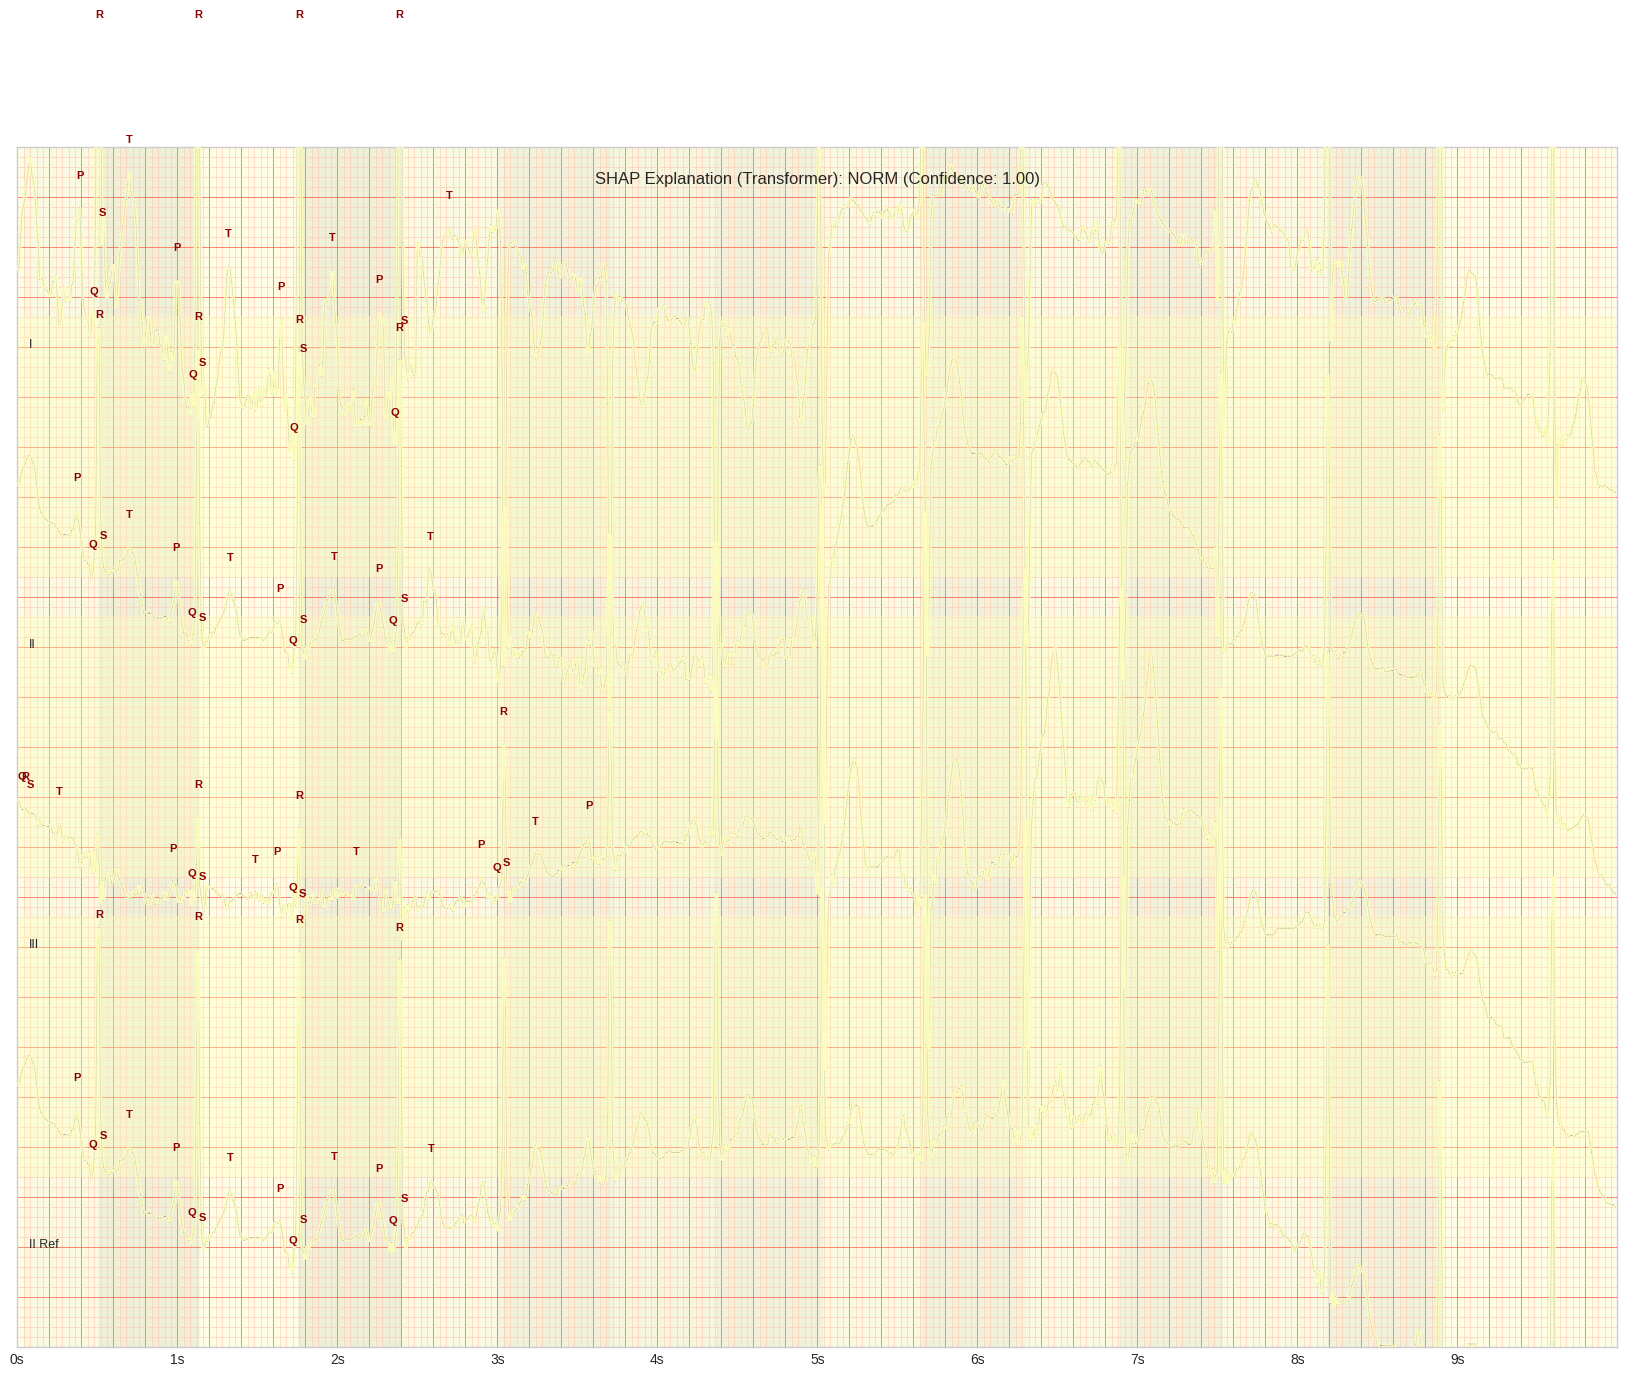

  Explaining Sample 2: validation02-AFLT


  0%|          | 0/1 [00:00<?, ?it/s]

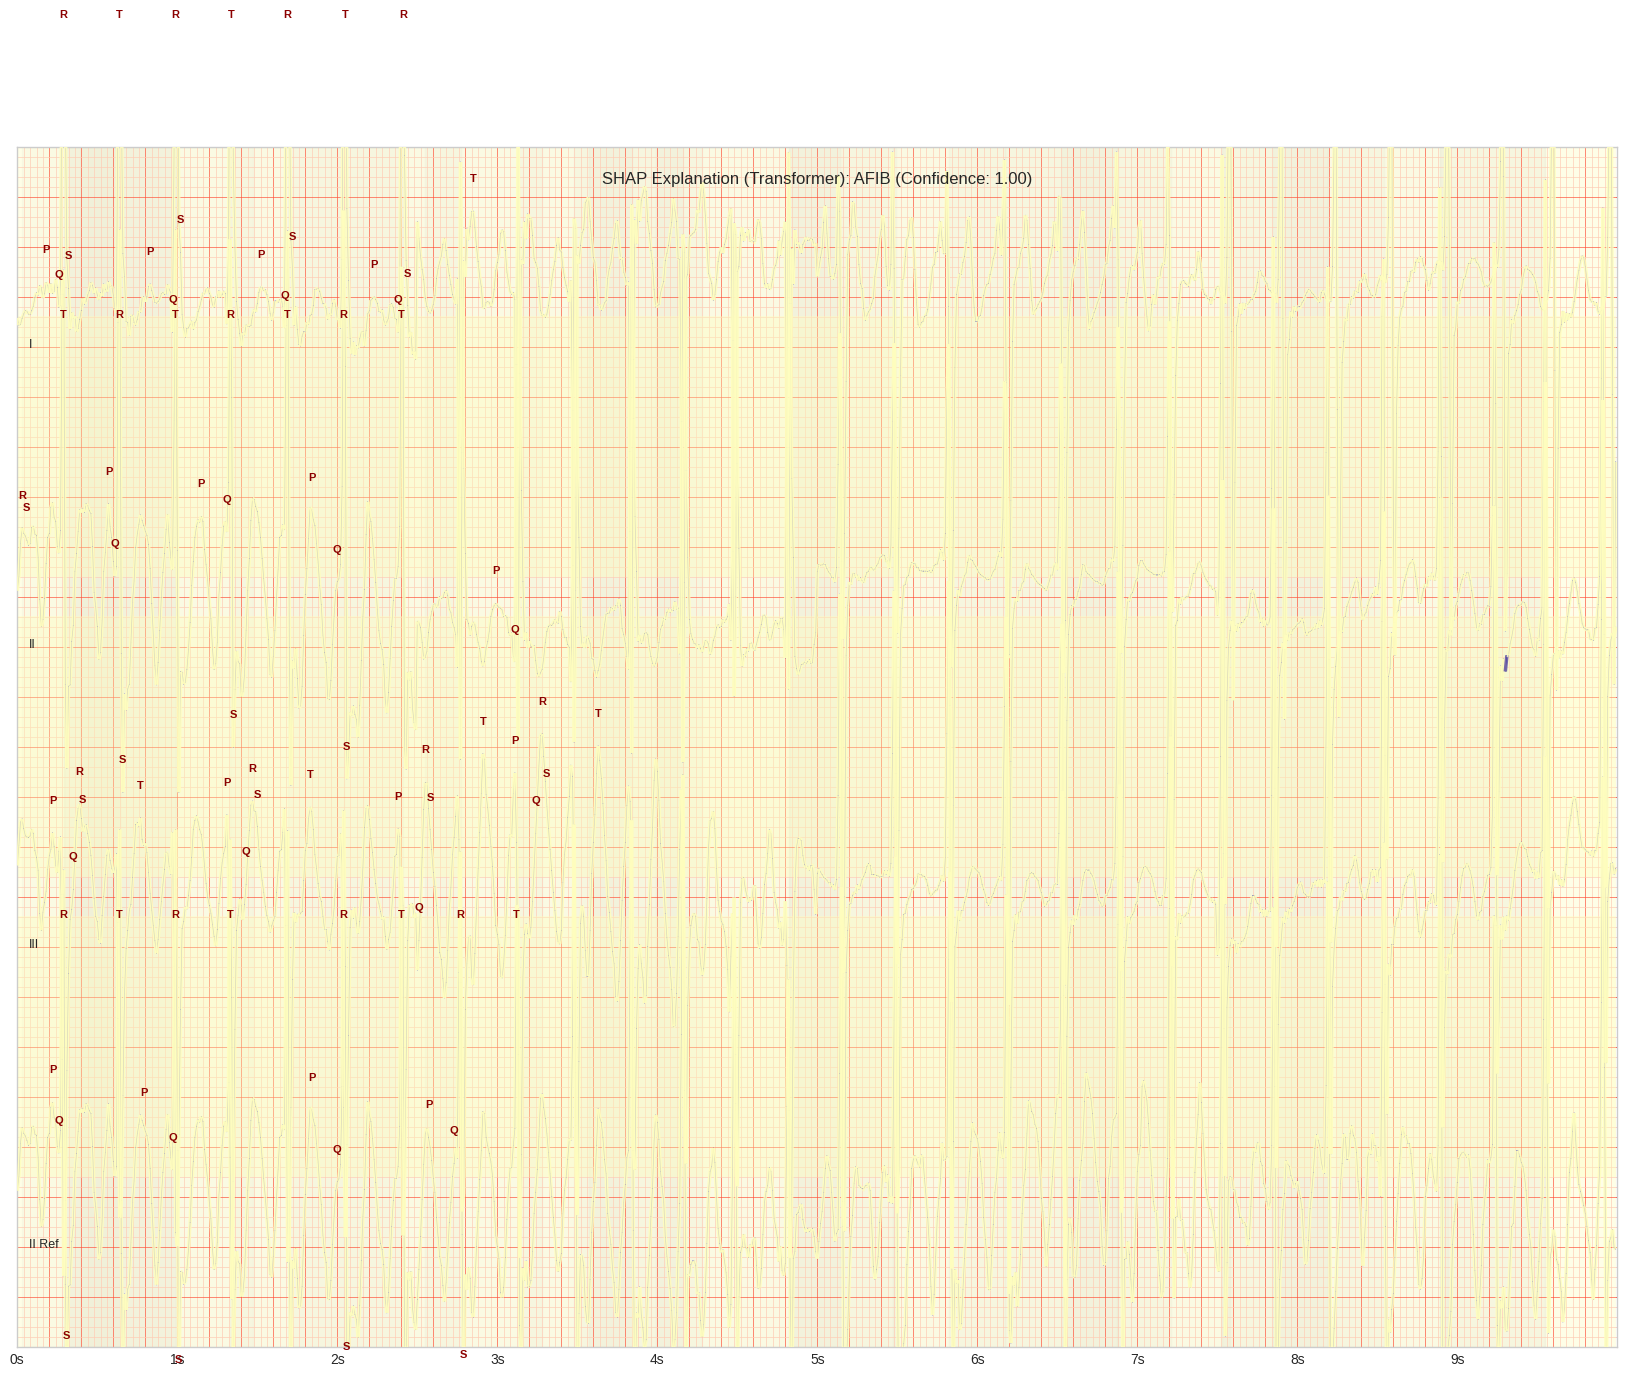

  Explaining Sample 3: validation03-1dAVb


  0%|          | 0/1 [00:00<?, ?it/s]

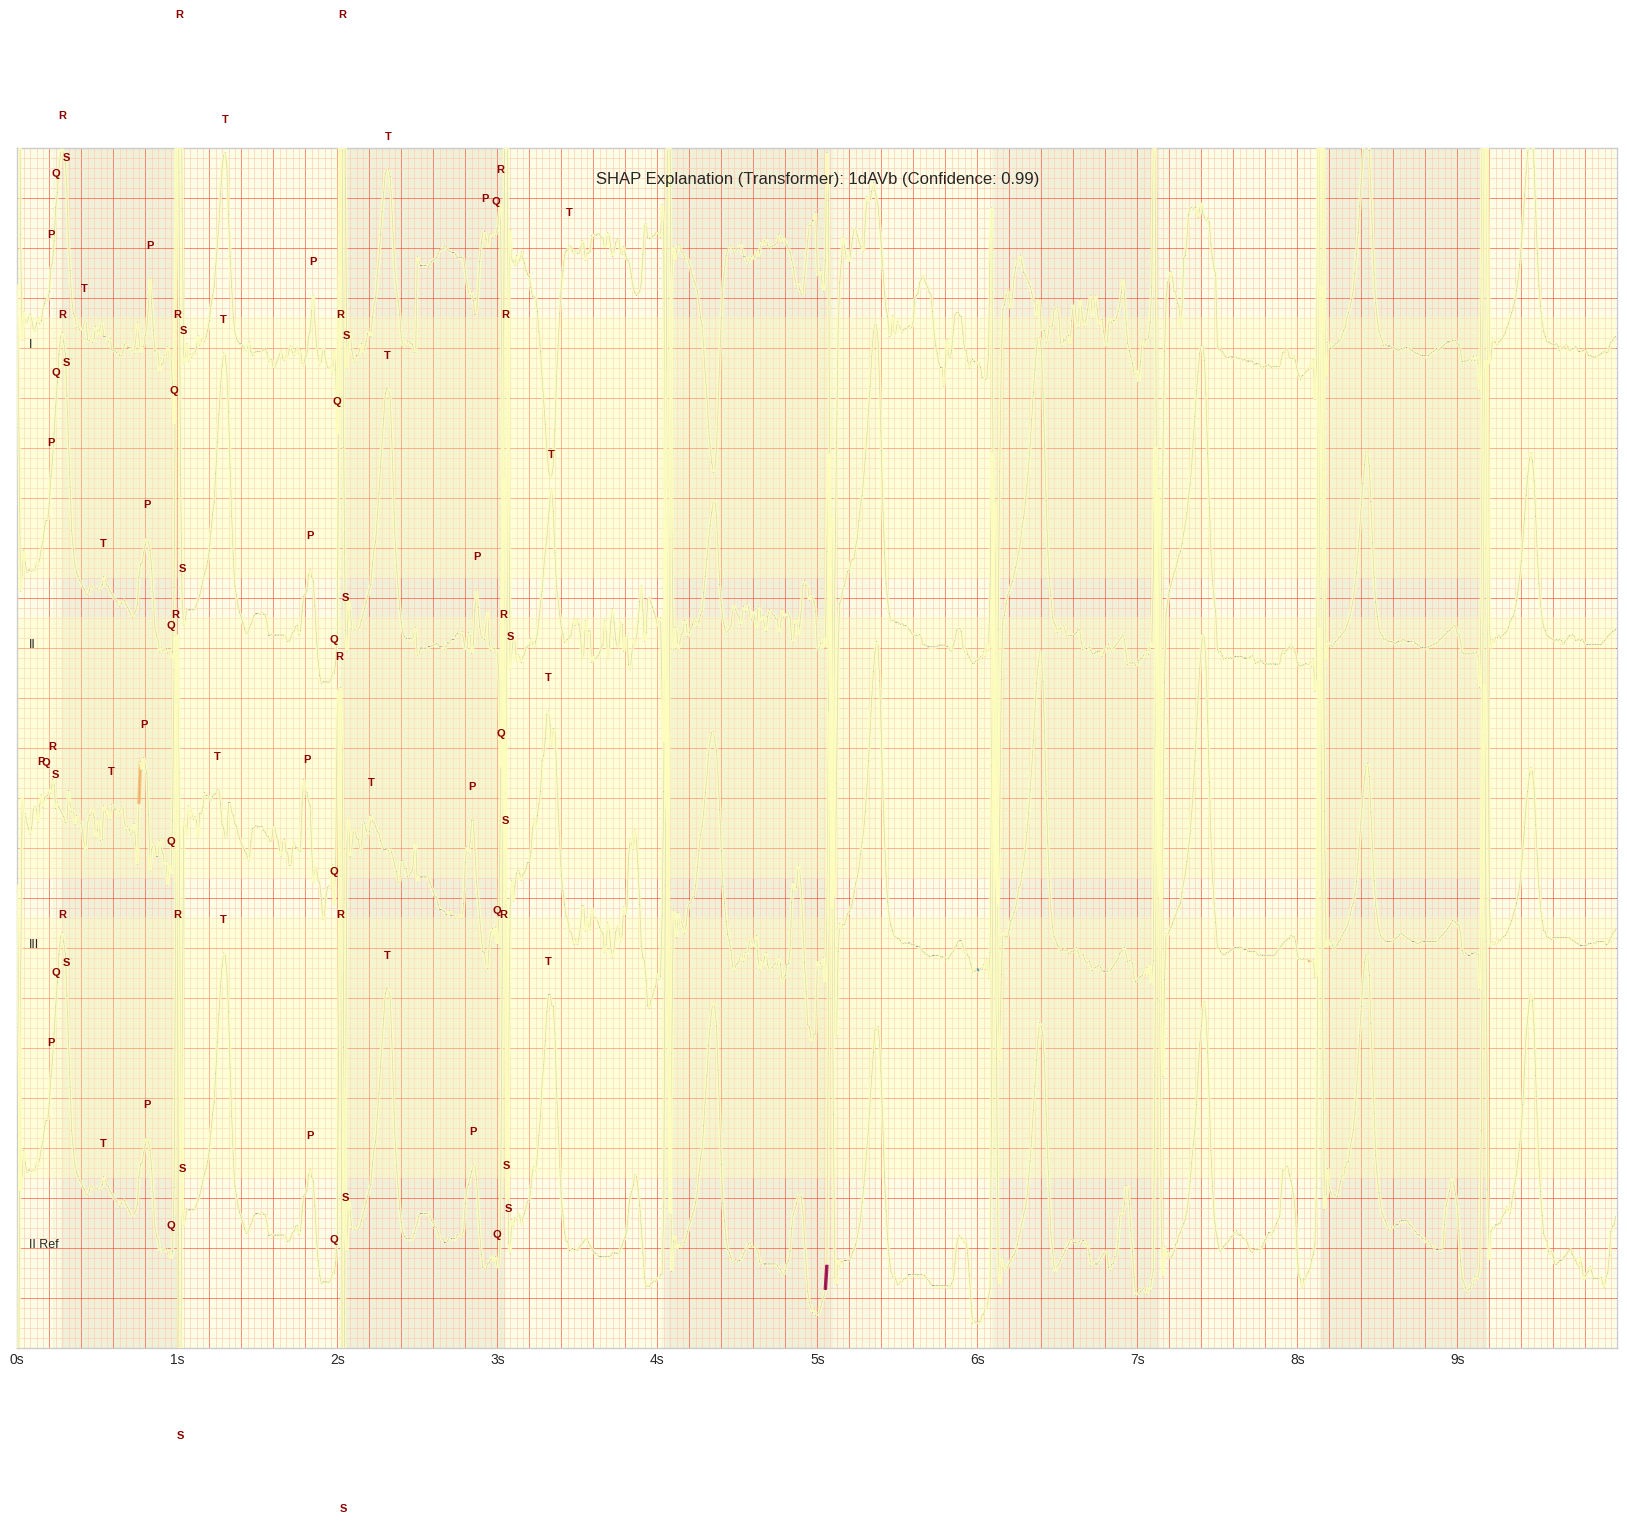

  Explaining Sample 4: validation04-AFIB


  0%|          | 0/1 [00:00<?, ?it/s]

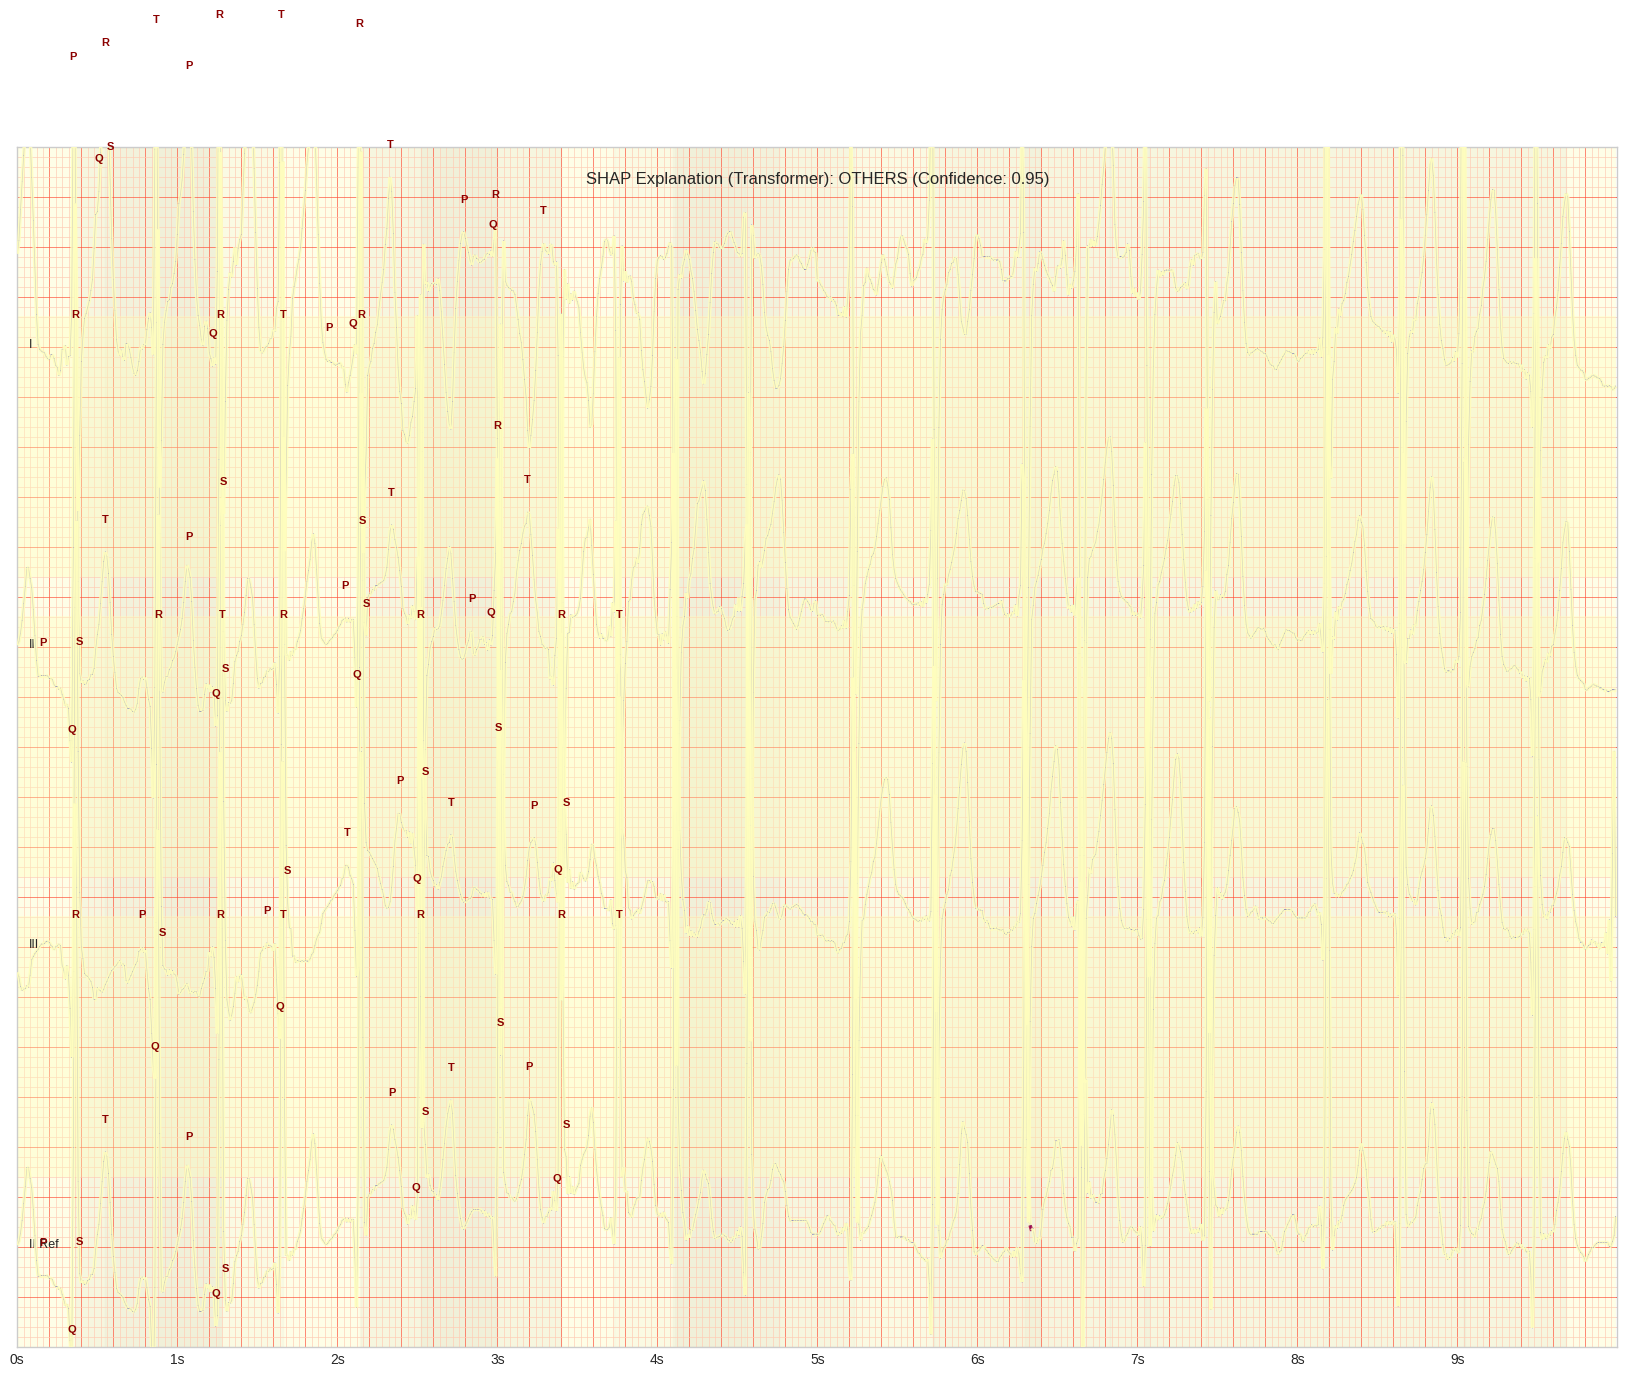

  Explaining Sample 5: validation05-RBBB


  0%|          | 0/1 [00:00<?, ?it/s]

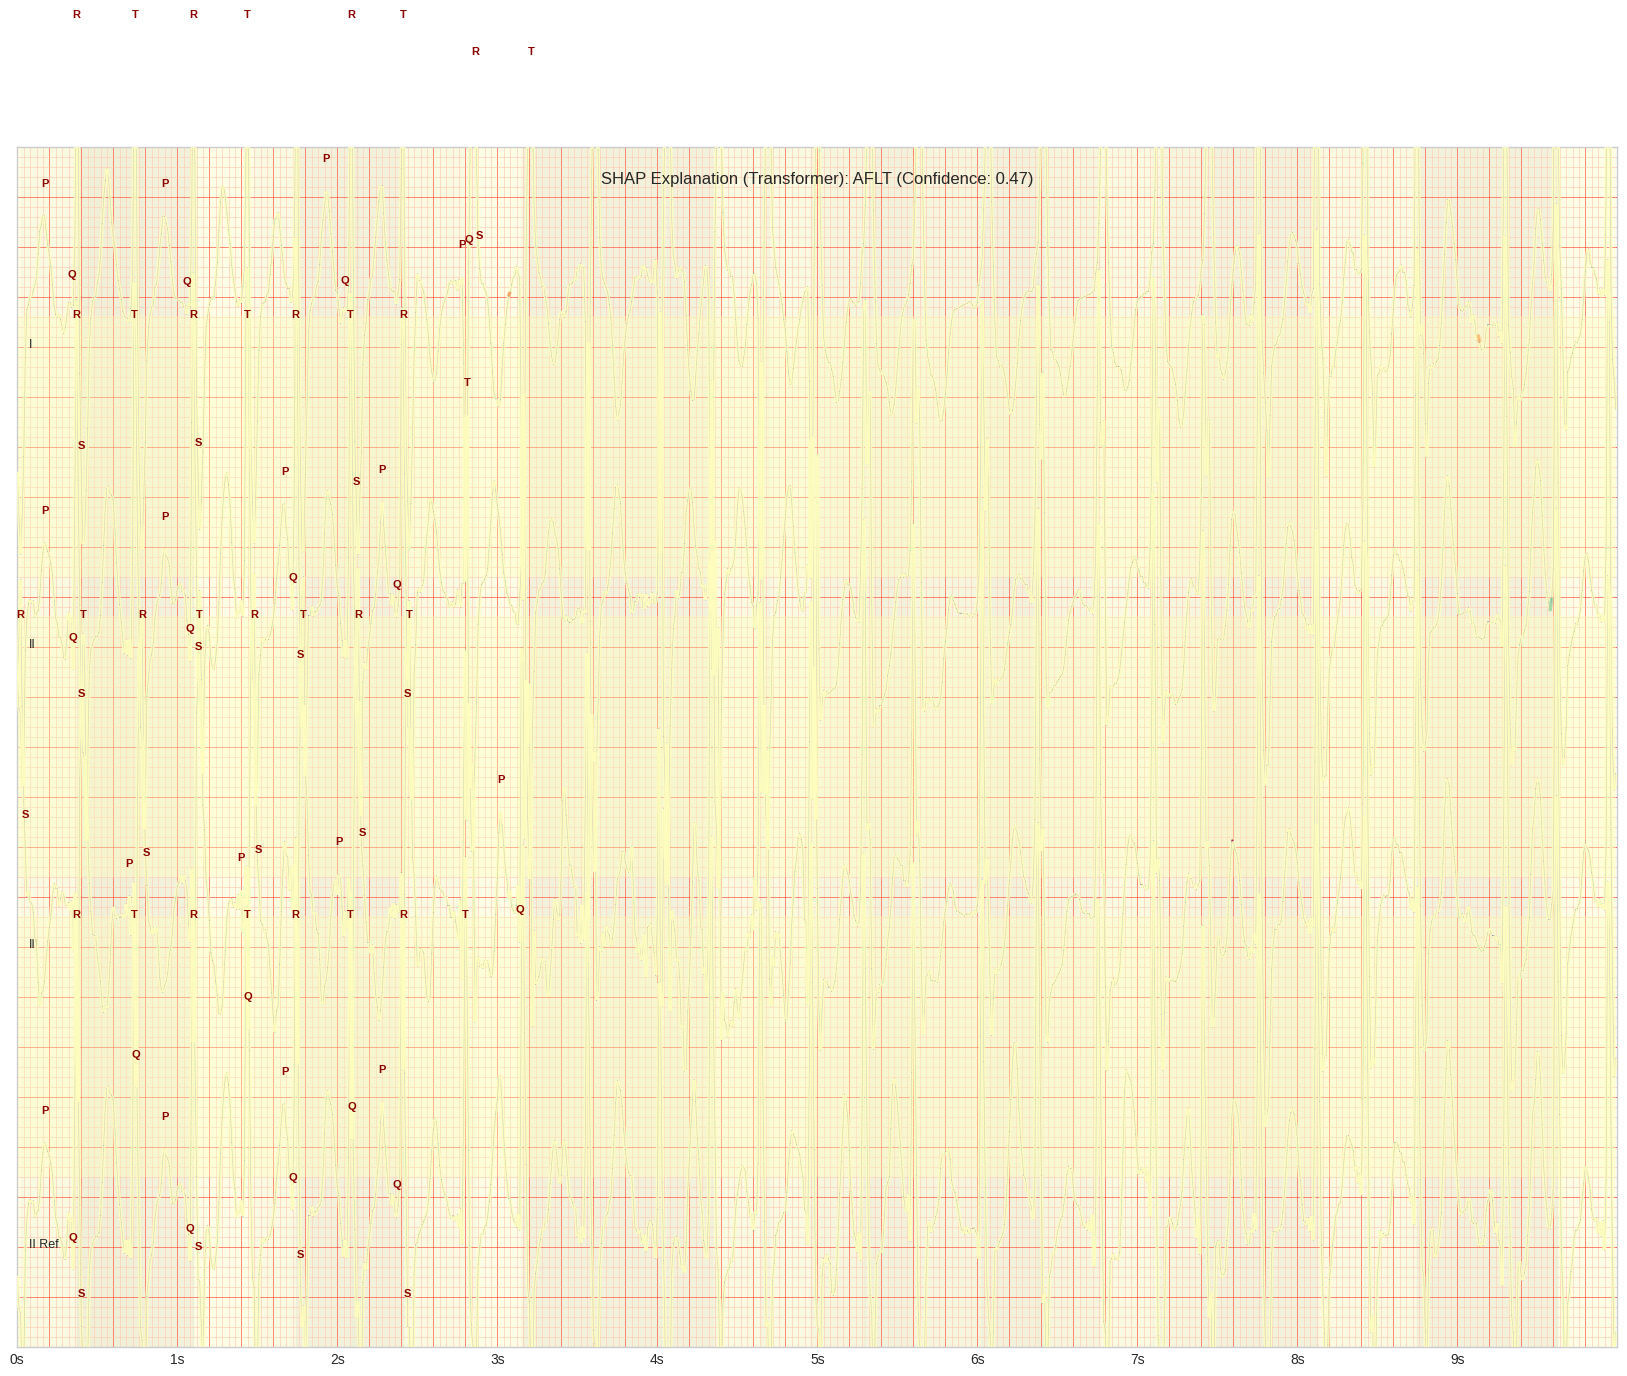

  Explaining Sample 6: validation06-LBBB


  0%|          | 0/1 [00:00<?, ?it/s]

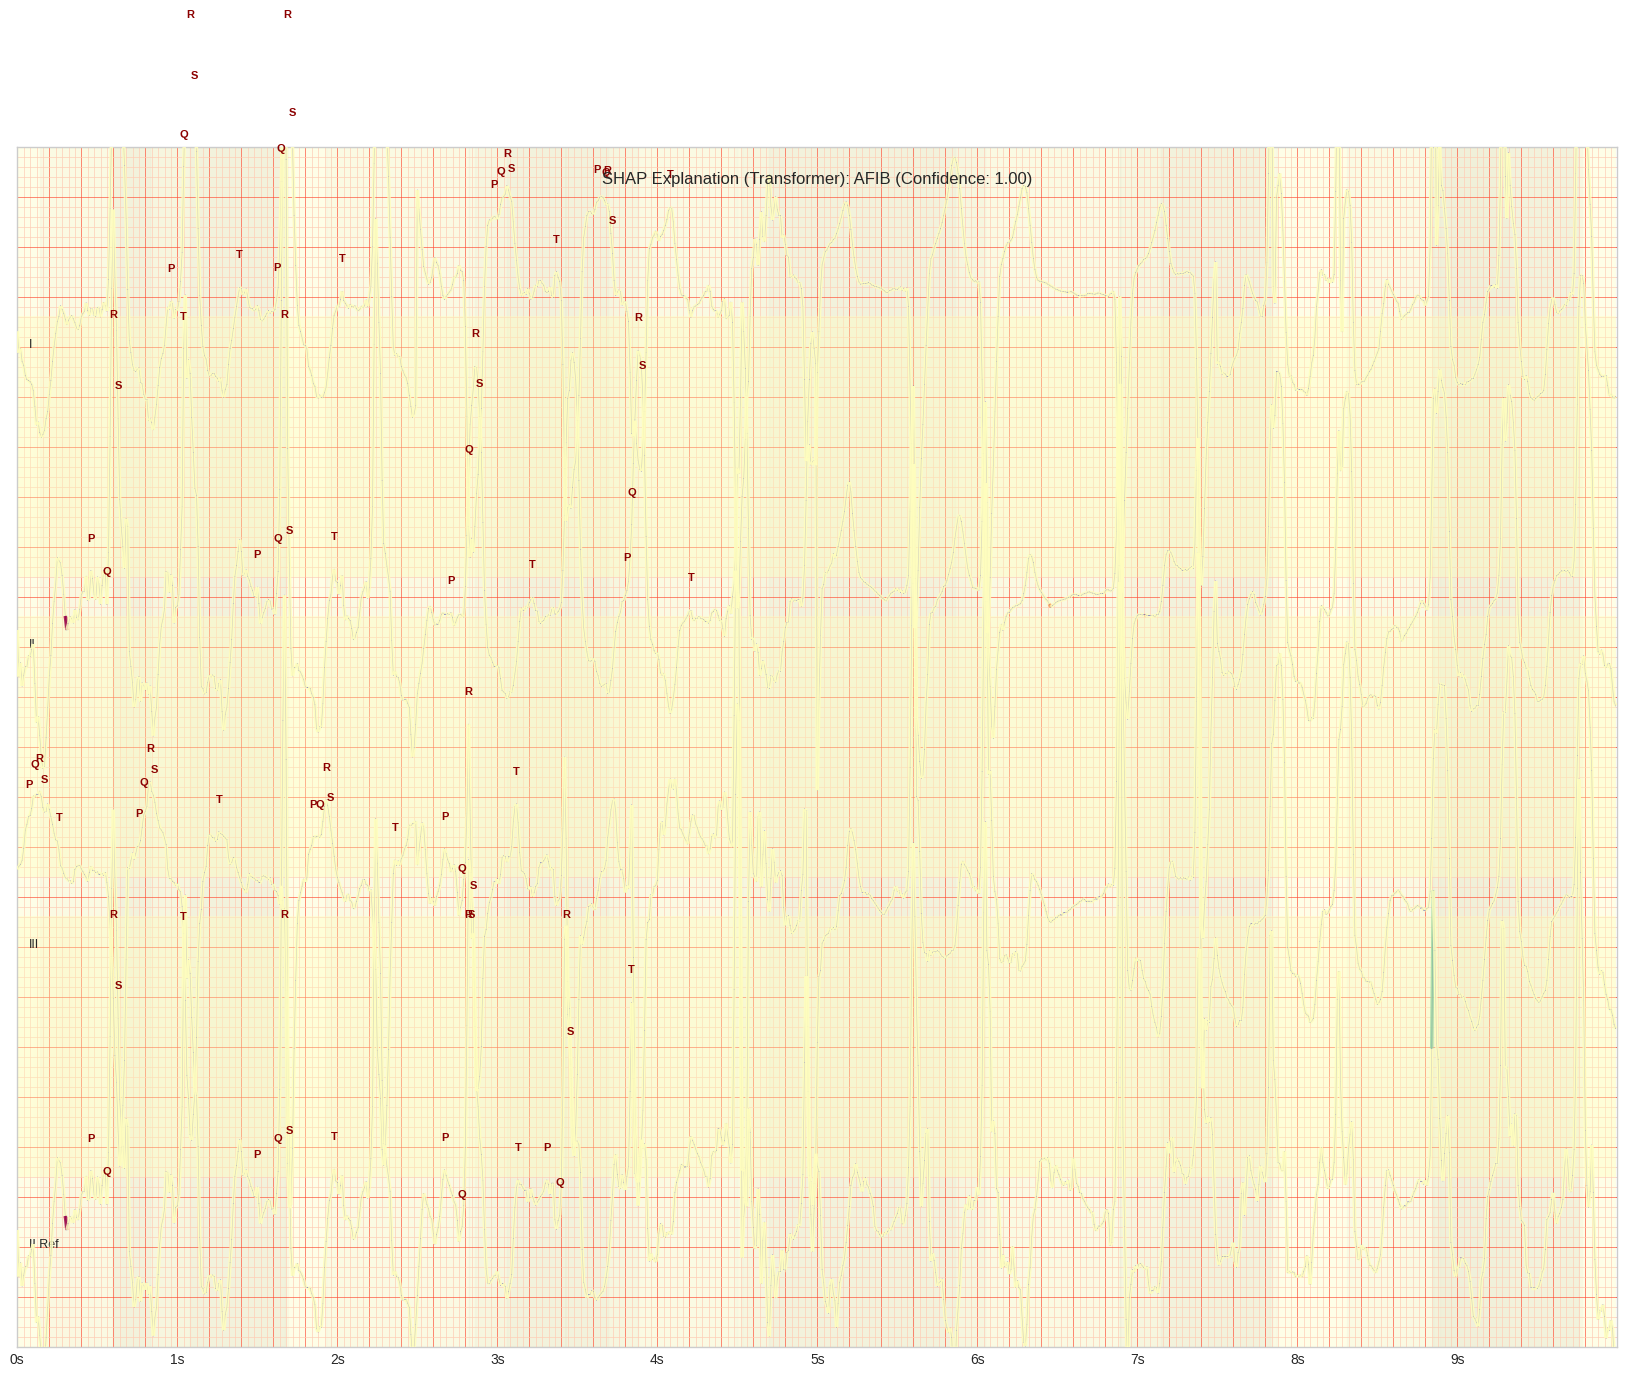

In [34]:
# ============================================
# 8.2 Generate Explanations (Transformer Only)
# ============================================
print("Generating SHAP explanations...")
if 'explainer' in locals() and validation_dataset and len(validation_dataset) > 0:
    for i in range(min(6, len(validation_dataset))):
        val_sample = validation_dataset[i]
        print(f"  Explaining Sample {i+1}: {val_sample['filename']}")
        # Use nsamples=200 for better detail as requested
        explanation = explainer.explain_instance(val_sample['ecg'].numpy(), nsamples=200)
        explainer.plot_explanation(explanation)
        plt.show()


Generating Grad-CAM comparison for Transformer...


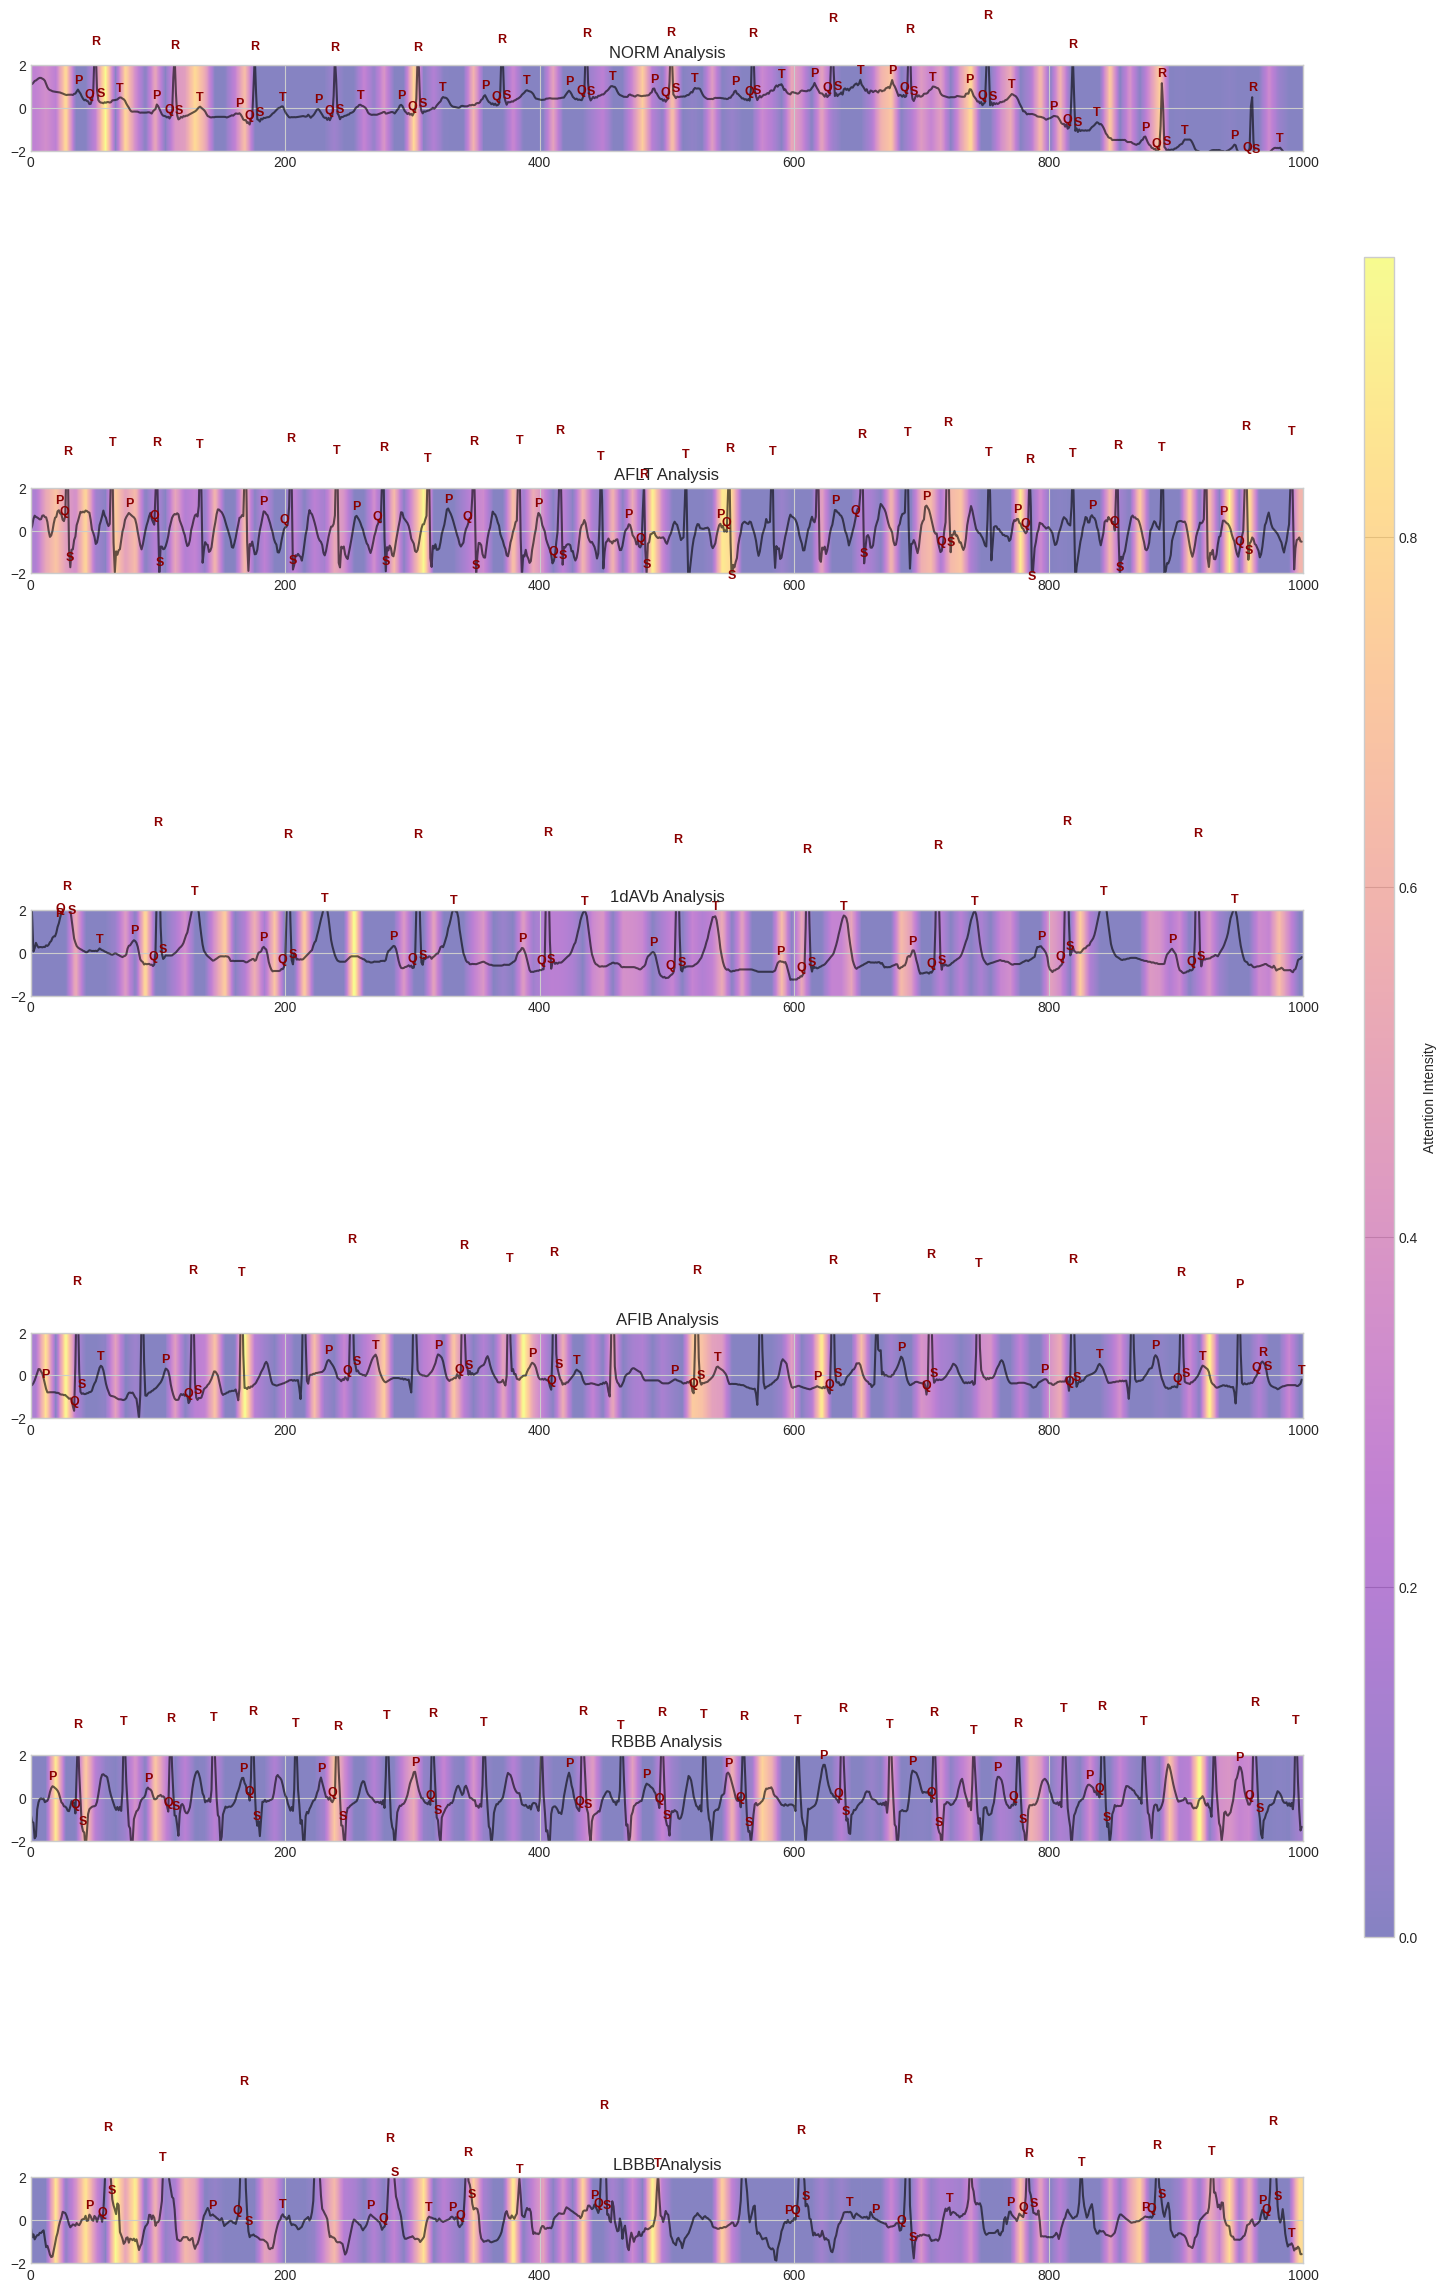

In [35]:
# ===========================================================
# 8.3 Generate GradCAM Normal vs Diagnosis (Transformer Only)
# ===========================================================
from ecg_module import detect_pqrst, ECGGradCAM
import matplotlib.pyplot as plt
import numpy as np
import torch

print("Generating Grad-CAM comparison for Transformer...")
transformer_model = None
if 'benchmark_results' in locals() and 'Transformer' in benchmark_results:
    transformer_model = benchmark_results['Transformer']['model']

if transformer_model:
    transformer_model.eval()
    cam_gen = ECGGradCAM(transformer_model, transformer_model.transformer)
    
    class_samples = {}
    for j in range(len(validation_dataset)):
        s = validation_dataset[j]
        if s['label_str'] not in class_samples: class_samples[s['label_str']] = s
    
    fig, axes = plt.subplots(len(class_samples), 1, figsize=(15, 4 * len(class_samples)))
    if len(class_samples) == 1: axes = [axes]
    
    for j, (cls, sample) in enumerate(class_samples.items()):
        ecg_t = sample['ecg'].unsqueeze(0).to(config.device)
        cam = cam_gen.generate(ecg_t)
        
        sig = sample['ecg'][1].numpy()
        axes[j].plot(sig, color='black', alpha=0.6)
        im = axes[j].imshow(cam.reshape(1, -1), aspect='auto', cmap='plasma', 
                       extent=[0, 1000, -2, 2], alpha=0.5)
        
        # PQRST Annotation
        waves = detect_pqrst(sig)
        for w_type, indices in waves.items():
            for idx in indices:
                if 0 <= idx < 1000:
                    axes[j].text(idx, sig[idx] + 0.3, w_type, fontsize=9, 
                               ha='center', color='darkred', fontweight='bold')
        
        axes[j].set_title(f"{cls} Analysis")
    
    # Add colorbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    fig.colorbar(im, cax=cbar_ax, label='Attention Intensity')
        
    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.show()
    cam_gen.remove_hooks()
else:
    print("Transformer model not found.")


Generating beat-level SHAP for all 6 samples...
Sample 1: validation01-NORM


  0%|          | 0/1 [00:00<?, ?it/s]

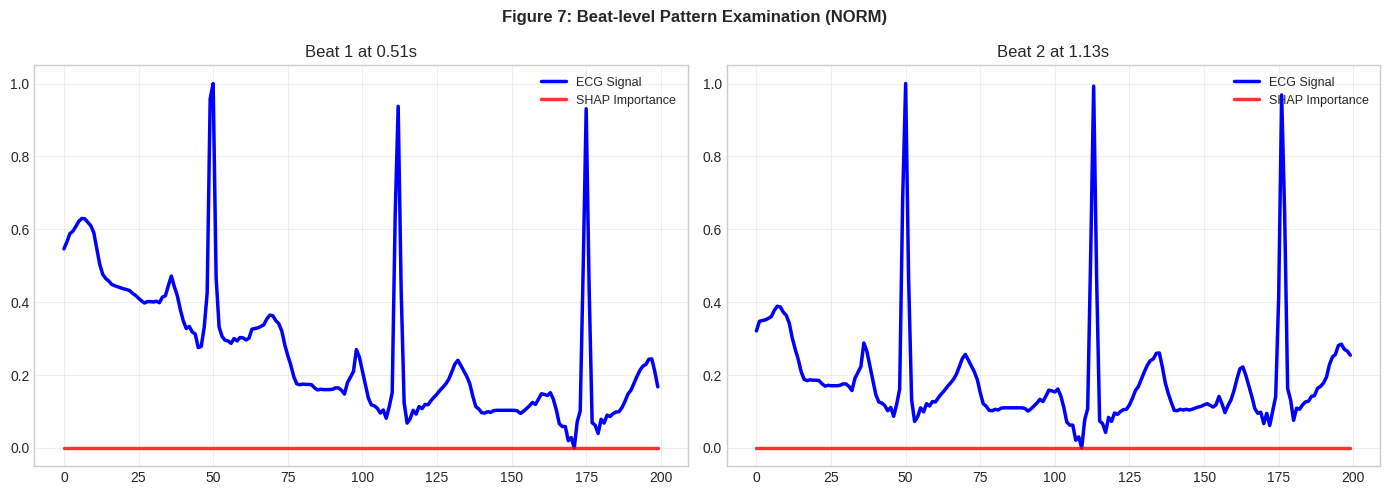

Sample 2: validation02-AFLT


  0%|          | 0/1 [00:00<?, ?it/s]

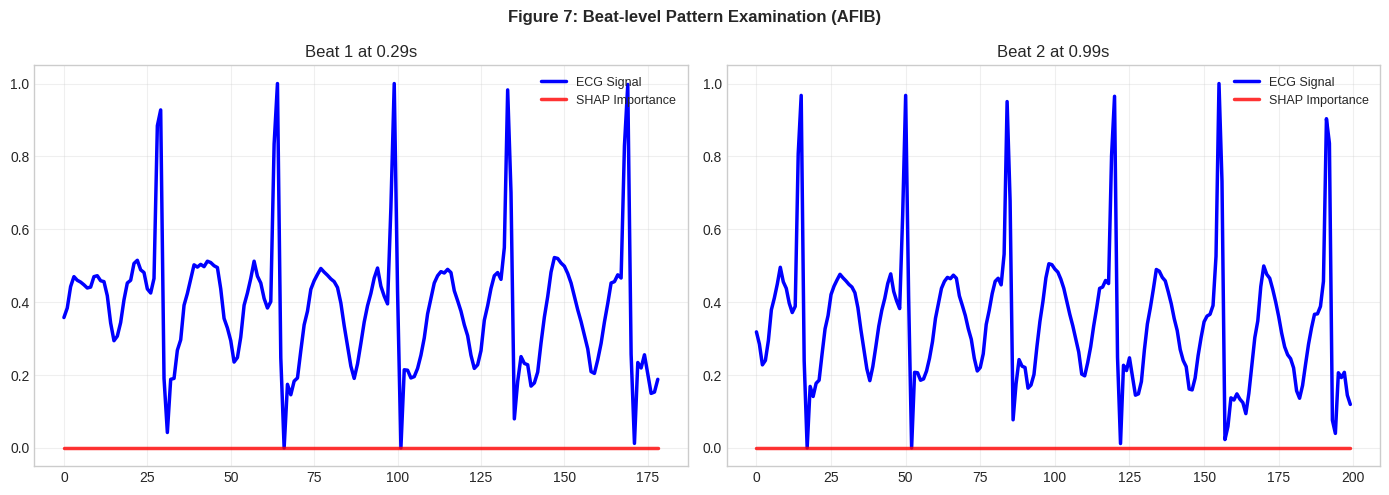

Sample 3: validation03-1dAVb


  0%|          | 0/1 [00:00<?, ?it/s]

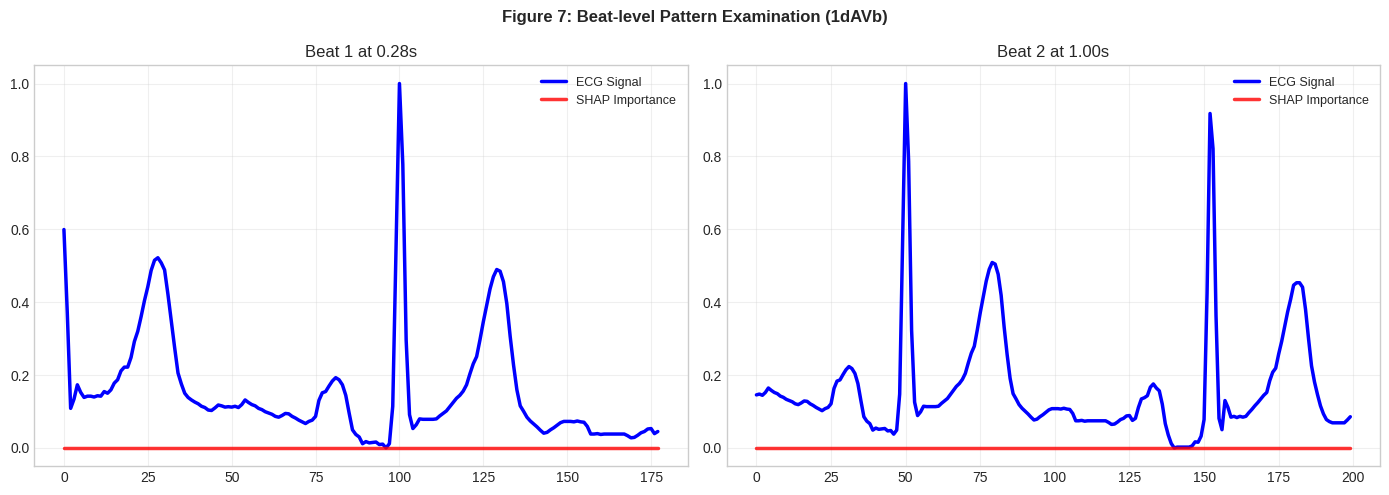

Sample 4: validation04-AFIB


  0%|          | 0/1 [00:00<?, ?it/s]

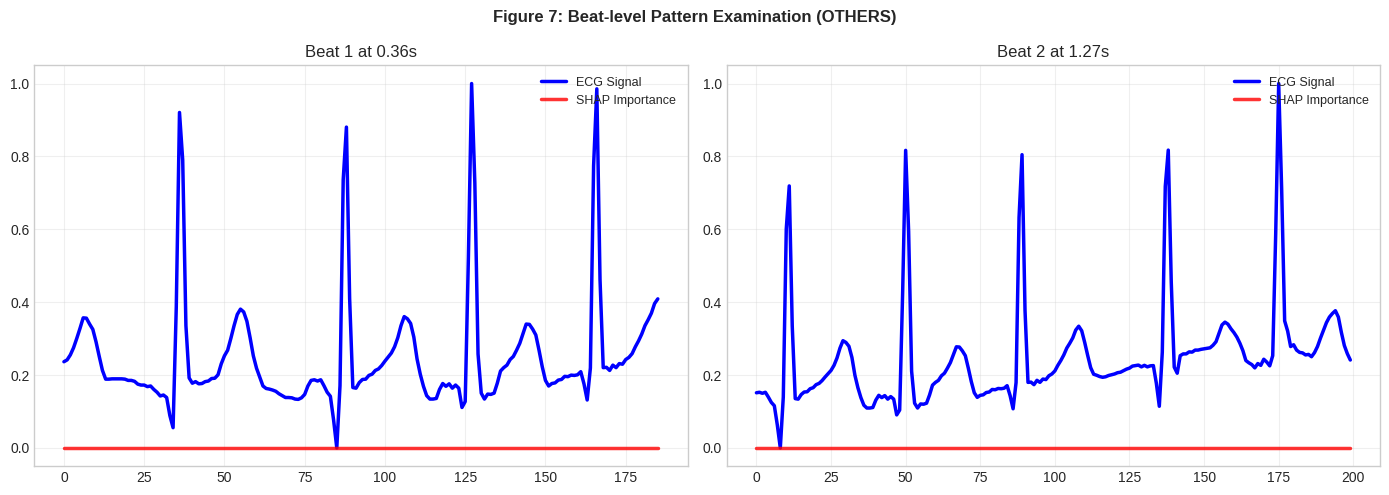

Sample 5: validation05-RBBB


  0%|          | 0/1 [00:00<?, ?it/s]

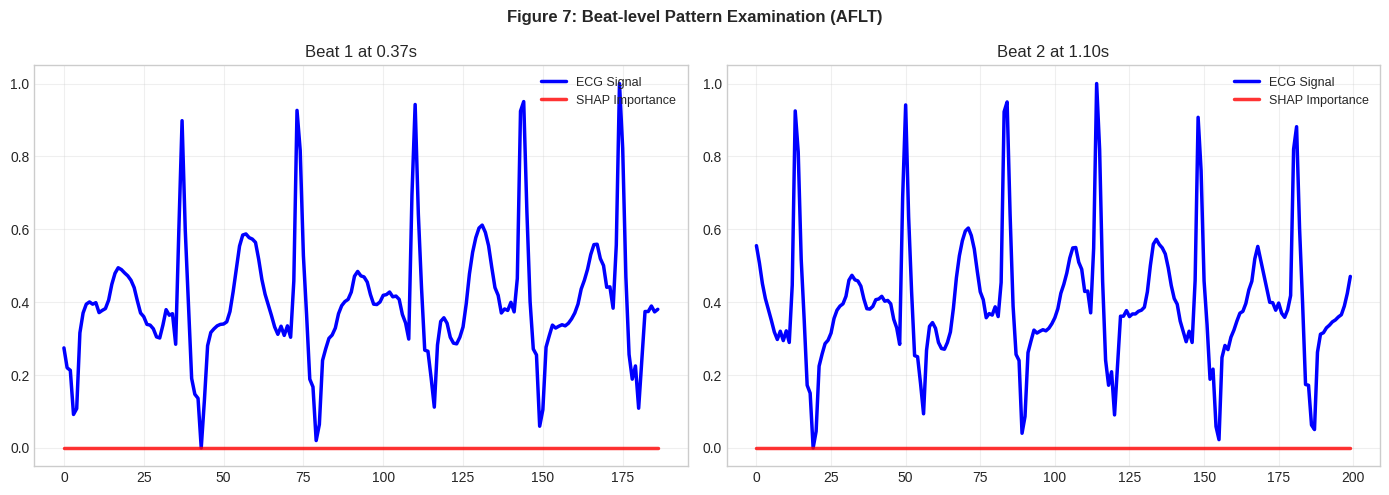

Sample 6: validation06-LBBB


  0%|          | 0/1 [00:00<?, ?it/s]

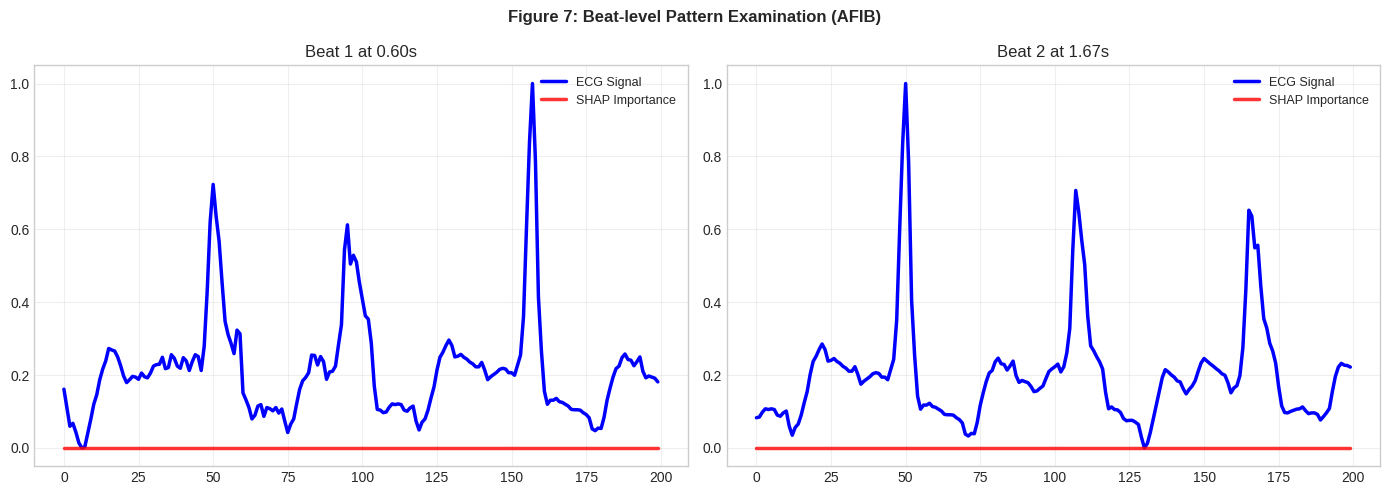

In [36]:
# 8.4 Beat-level SHAP Patterns (Figure 7 Style)
# ===========================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def plot_beat_explanations(explanation, n_beats=2):
    """Plot individual beats and their SHAP values as separate lines (Figure 7 style)."""
    ecg = explanation['ecg']
    shap_v = explanation['shap_values']
    p_idx = explanation['prediction_idx']
    if isinstance(shap_v, list): sv = shap_v[p_idx][0]
    else: sv = shap_v[0, :, p_idx]
    sv = sv.reshape(12, 1000)
    
    sig = np.array(ecg[1])
    peaks, _ = find_peaks(sig, distance=60, height=0.5)
    
    num_display = min(n_beats, len(peaks))
    if num_display == 0: return
    
    fig, axes = plt.subplots(1, num_display, figsize=(14, 5))
    if num_display == 1: axes = [axes]
    
    for j in range(num_display):
        r = peaks[j]
        start = max(0, r - 50); end = min(1000, r + 150)
        beat_sig = sig[start:end]
        beat_shap = sv[1, start:end]
        
        # Normalize to show sensitivity even if small
        sig_min, sig_max = beat_sig.min(), beat_sig.max()
        beat_sig = (beat_sig - sig_min) / (sig_max - sig_min + 1e-6)
        
        shap_min, shap_max = beat_shap.min(), beat_shap.max()
        if shap_max - shap_min > 1e-12:
            beat_shap = (beat_shap - shap_min) / (shap_max - shap_min)
        else:
            beat_shap = np.zeros_like(beat_shap)
        
        axes[j].plot(beat_sig, color='blue', label='ECG Signal', linewidth=2.5)
        axes[j].plot(beat_shap, color='red', label='SHAP Importance', linewidth=2.5, alpha=0.8)
        axes[j].set_title(f"Beat {j+1} at {r/100:.2f}s")
        axes[j].legend(loc='upper right', fontsize=9)
        axes[j].grid(True, alpha=0.3)
        
    plt.suptitle(f"Figure 7: Beat-level Pattern Examination ({explanation['prediction']})", fontweight='bold')
    plt.tight_layout()
    plt.show()

print("Generating beat-level SHAP for all 6 samples...")
if 'explainer' in locals():
    for k in range(min(6, len(validation_dataset))):
        val_sample = validation_dataset[k]
        print(f"Sample {k+1}: {val_sample['filename']}")
        explanation = explainer.explain_instance(val_sample['ecg'].numpy(), nsamples=200)
        plot_beat_explanations(explanation, n_beats=2)


---

## 9. Low-Confidence Detection

This section implements the low-confidence referral mechanism.

In [37]:
# ============================================
# 9.1 Confidence Threshold Analysis
# ============================================

def analyze_confidence_thresholds(model, dataloader, device, thresholds=np.linspace(0.5, 0.95, 10)):
    """
    Analyze different confidence thresholds.
    
    Args:
        model: Trained model
        dataloader: Validation data loader
        device: Device to use
        thresholds: Array of confidence thresholds to test
    
    Returns:
        DataFrame with threshold analysis results
    """
    model.eval()
    
    all_probs = []
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for batch in dataloader:
            ecg = batch['ecg'].to(device)
            labels = batch['label'].reshape(-1).detach().cpu().numpy()
            
            outputs = model(ecg)
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1).detach().cpu().numpy()
            
            all_probs.extend(probs.detach().cpu().numpy())
            all_preds.extend(preds)
            all_labels.extend(labels)
    
    all_probs = np.array(all_probs)
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    
    # Get max probabilities
    max_probs = all_probs.max(axis=1)
    
    results = []
    for threshold in thresholds:
        # Find high confidence predictions
        high_conf_mask = max_probs >= threshold
        
        if high_conf_mask.sum() > 0:
            # Metrics on high-confidence predictions
            hc_preds = all_preds[high_conf_mask]
            hc_labels = all_labels[high_conf_mask]
            hc_acc = accuracy_score(hc_labels, hc_preds)
            hc_f1 = f1_score(hc_labels, hc_preds, average='macro', zero_division=0)
        else:
            hc_acc = np.nan
            hc_f1 = np.nan
        
        results.append({
            'Threshold': threshold,
            'Coverage': high_conf_mask.mean(),
            'Low_Confidence_Rate': 1 - high_conf_mask.mean(),
            'High_Conf_Accuracy': hc_acc,
            'High_Conf_F1': hc_f1,
            'Mean_Confidence': max_probs[high_conf_mask].mean() if high_conf_mask.sum() > 0 else np.nan
        })
    
    return pd.DataFrame(results)


def plot_confidence_analysis(threshold_df, save_path=None):
    """Plot confidence threshold analysis."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Coverage vs threshold
    axes[0].plot(threshold_df['Threshold'], threshold_df['Coverage'],
                'o-', linewidth=2, markersize=8, label='Coverage')
    axes[0].set_xlabel('Confidence Threshold')
    axes[0].set_ylabel('Coverage (Fraction Predicted)')
    axes[0].set_title('Coverage vs Confidence Threshold')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()
    
    # High-conf accuracy vs threshold
    axes[1].plot(threshold_df['Threshold'], threshold_df['High_Conf_Accuracy'],
                's-', linewidth=2, markersize=8, color='green', label='High-Conf Accuracy')
    axes[1].set_xlabel('Confidence Threshold')
    axes[1].set_ylabel('Accuracy (High Confidence Only)')
    axes[1].set_title('High-Confidence Accuracy vs Threshold')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

print("Confidence analysis functions defined.")

Confidence analysis functions defined.


In [38]:
# ============================================
# 9.2 Confidence Histogram
# ============================================

def plot_confidence_histogram(probs, threshold=0.7, save_path=None):
    """Plot histogram of confidence scores."""
    max_probs = probs.max(axis=1)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot histogram
    bins = np.linspace(0, 1, 50)
    n, bins_edges, patches = ax.hist(max_probs, bins=bins, alpha=0.7, 
                                      color='steelblue', edgecolor='black')
    
    # Color bins by threshold
    for patch, bin_edge in zip(patches, bins_edges):
        if bin_edge < threshold:
            patch.set_facecolor('coral')
        else:
            patch.set_facecolor('steelblue')
    
    # Add threshold line
    ax.axvline(threshold, color='red', linestyle='--', linewidth=2,
               label=f'Threshold = {threshold}')
    
    ax.set_xlabel('Max Prediction Probability (Confidence)')
    ax.set_ylabel('Count')
    ax.set_title('Distribution of Prediction Confidence Scores')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add statistics
    stats_text = f"\nMean: {max_probs.mean():.3f}\n"
    stats_text += f"Median: {np.median(max_probs):.3f}\n"
    stats_text += f"Low confidence (<{threshold}): {(max_probs < threshold).sum()} ({(max_probs < threshold).mean()*100:.1f}%)"
    ax.text(0.98, 0.97, stats_text, transform=ax.transAxes,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

print("Confidence histogram function defined.")

Confidence histogram function defined.


In [39]:
def export_low_confidence_cases(model, dataloader, threshold, device, 
                                output_path, class_names=None):
    if class_names is None: class_names = config.class_names
    model.eval()
    low_conf_cases = []
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Reviewing samples"):
            ecg = batch['ecg'].to(device)
            filenames = batch.get('filename', ["unknown"])
            outputs = model(ecg)
            probs = F.softmax(outputs, dim=1)
            for i in range(ecg.size(0)):
                max_prob, pred = probs[i].max(dim=0)
                if max_prob.item() < threshold:
                    top3_probs, top3_indices = probs[i].topk(3)
                    case = {
                        'filename': filenames[i] if i < len(filenames) else f"batch_{i}",
                        'predicted_class': class_names[pred.item()],
                        'confidence': max_prob.item(),
                        'top2_class': class_names[top3_indices[1].item()],
                        'top2_confidence': top3_probs[1].item(),
                    }
                    if 'label' in batch:
                        lbl = batch['label'][i].reshape(-1)[0].item()
                        case['true_label'] = class_names[lbl]
                    low_conf_cases.append(case)
    df = pd.DataFrame(low_conf_cases)
    if not df.empty:
        df.to_csv(output_path, index=False)
        print(f"Low-confidence cases exported to {output_path}")
    return df

In [40]:
# Example: Export low-confidence cases for the Transformer model
print("Reviewing low-confidence cases for Transformer model...")
device = torch.device(config.device)
transformer_model = benchmark_results.get('Transformer', {}).get('model')

if transformer_model and test_loader:
    low_conf_df = export_low_confidence_cases(
        model=transformer_model, 
        dataloader=test_loader, 
        threshold=config.confidence_threshold, 
        device=device, 
        output_path=config.output_dir / "low_confidence_transformer.csv"
    )
    if not low_conf_df.empty:
        print(f"Found {len(low_conf_df)} low-confidence cases.")
        display(low_conf_df.head())
else:
    print("Ensure transformer_model and test_loader are initialized.")

Reviewing low-confidence cases for Transformer model...


Reviewing samples: 100%|██████████| 6/6 [00:00<00:00, 237.10it/s]


---

## 10. Ablation Study

This section performs ablation experiments to justify architecture choices.

In [41]:
# ============================================
# 10.1 Ablation Model Variants
# ============================================

class HybridNoGate(nn.Module):
    """Hybrid model without gated fusion (simple concatenation)."""
    
    def __init__(self, num_leads=12, num_classes=7):
        super().__init__()
        
        # Simplified feature extractors
        self.cnn = nn.Sequential(
            ConvBlock1D(num_leads, 64, 7, stride=2, padding=3),
            nn.MaxPool1d(2),
            ConvBlock1D(64, 128, 5, stride=2, padding=2),
            ConvBlock1D(128, 256, 5, stride=2, padding=2),
            nn.AdaptiveAvgPool1d(1)
        )
        
        # Simplified transformer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256, nhead=8, dim_feedforward=512,
            dropout=0.1, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, 2)
        
        # Simple concatenation head
        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        # CNN path
        cnn_feat = self.cnn(x).squeeze(-1)
        
        # Transformer path
        patches = x.permute(0, 2, 1)  # (B, T, 12)
        trans_feat = self.transformer(patches).mean(dim=1)
        
        # Concatenate (no gating)
        combined = torch.cat([cnn_feat, trans_feat], dim=1)
        return self.classifier(combined)


class CNNOnly(nn.Module):
    """CNN-only model (no transformer)."""
    
    def __init__(self, num_leads=12, num_classes=7):
        super().__init__()
        
        self.features = nn.Sequential(
            ConvBlock1D(num_leads, 64, 7, stride=2, padding=3),
            nn.MaxPool1d(2),
            ConvBlock1D(64, 128, 5, stride=2, padding=2),
            ConvBlock1D(128, 256, 5, stride=2, padding=2),
            ConvBlock1D(256, 512, 3, stride=1, padding=1),
            nn.AdaptiveAvgPool1d(1)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        return self.classifier(self.features(x))


def run_ablation_study(ablations, train_loader, val_loader, config, class_weights, epochs=15):
    """
    Run ablation experiments.
    
    Args:
        ablations: Dict of {name: model_class}
    
    Returns:
        DataFrame of ablation results
    """
    results = []
    
    for name, model_class in ablations.items():
        print(f"\n{'='*50}")
        print(f"Ablation: {name}")
        print(f"{'='*50}")
        
        model = model_class()
        device = torch.device(config.device)
        model = model.to(device)
        
        # Train
        trained_model, history = train_model(
            model, train_loader, val_loader, config, class_weights
        )
        
        # Evaluate
        metrics, _, _, _ = validate(
            trained_model, val_loader, nn.CrossEntropyLoss(), device
        )
        
        results.append({
            'Model': name,
            'Accuracy': metrics.get('accuracy', 0),
            'F1_Macro': metrics.get('f1_macro', 0),
            'AUROC': metrics.get('auroc_macro', 0),
            'Parameters': count_parameters(trained_model),
            'Best_Val_Loss': min(history['val_loss'])
        })
    
    return pd.DataFrame(results)

# Define ablations
ablations = {
    'CNN_Only': CNNOnly,
    'Hybrid_No_Gate': HybridNoGate,
    'Full_Hybrid': HybridCNNTransformer,  # This is the main model
}

print("Ablation models defined.")
print("Uncomment to run ablation study.")

Ablation models defined.
Uncomment to run ablation study.


In [42]:
# ============================================
# 10.2 Ablation Results Visualization
# ============================================

def plot_ablation_results(ablation_df, save_path=None):
    """Plot ablation study results."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    x = np.arange(len(ablation_df))
    width = 0.6
    
    # Accuracy
    axes[0].bar(x, ablation_df['Accuracy'], width, color='steelblue', alpha=0.7)
    axes[0].set_xlabel('Model Variant')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_title('Accuracy Comparison')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(ablation_df['Model'], rotation=15, ha='right')
    axes[0].grid(True, alpha=0.3, axis='y')
    
    # F1 Score
    axes[1].bar(x, ablation_df['F1_Macro'], width, color='coral', alpha=0.7)
    axes[1].set_xlabel('Model Variant')
    axes[1].set_ylabel('F1 (Macro)')
    axes[1].set_title('F1 Score Comparison')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(ablation_df['Model'], rotation=15, ha='right')
    axes[1].grid(True, alpha=0.3, axis='y')
    
    # Parameters
    axes[2].bar(x, ablation_df['Parameters'] / 1e6, width, color='seagreen', alpha=0.7)
    axes[2].set_xlabel('Model Variant')
    axes[2].set_ylabel('Parameters (M)')
    axes[2].set_title('Parameter Count')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(ablation_df['Model'], rotation=15, ha='right')
    axes[2].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

print("Ablation visualization function defined.")

Ablation visualization function defined.


---

## 11. Test Set Predictions

This section generates predictions for the assignment test set.

In [43]:
# ============================================
# 11.1 Generate Test Predictions
# ============================================

def generate_test_predictions(model, test_loader, device, threshold=0.7, 
                               output_path=None, class_names=None):
    """
    Generate predictions for test set.
    
    Args:
        model: Trained model
        test_loader: Test data loader
        device: Device to use
        threshold: Confidence threshold for flagging
        output_path: Path to save predictions CSV
        class_names: List of class names
    
    Returns:
        DataFrame of predictions
    """
    if class_names is None:
        class_names = config.class_names
    
    model.eval()
    
    predictions = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Generating predictions"):
            ecg = batch['ecg'].to(device)
            filename = batch.get('filename', ['unknown'])[0]
            
            outputs = model(ecg)
            probs = F.softmax(outputs, dim=1)
            max_prob, pred = probs.max(dim=1)
            
            # Get top 3 predictions
            top3_probs, top3_indices = probs.topk(3, dim=1)
            
            pred_data = {
                'filename': filename,
                'predicted_class': class_names[pred.item()],
                'confidence': max_prob.item(),
                'low_confidence_flag': max_prob.item() < threshold,
            }
            
            # Add all class probabilities
            for i, cls in enumerate(class_names):
                pred_data[f'prob_{cls}'] = probs[0, i].item()
            
            # Add top 3 alternatives
            pred_data['top2_class'] = class_names[top3_indices[0, 1].item()]
            pred_data['top2_confidence'] = top3_probs[0, 1].item()
            pred_data['top3_class'] = class_names[top3_indices[0, 2].item()]
            pred_data['top3_confidence'] = top3_probs[0, 2].item()
            
            predictions.append(pred_data)
    
    df = pd.DataFrame(predictions)
    
    if output_path:
        df.to_csv(output_path, index=False)
        print(f"Predictions saved to {output_path}")
    
    return df


if test_loader is not None:
    print("Generating test predictions using Transformer model...")
    transformer_model = benchmark_results.get('Transformer', {}).get('model')
    if transformer_model:
        test_predictions = generate_test_predictions(
            transformer_model, test_loader, torch.device(config.device),
            threshold=config.confidence_threshold,
            output_path=config.output_dir / "test_predictions_transformer.csv"
        )
    else:
        print("Transformer model not found in benchmark_results.")
else:
    print("Test loader not available.")

Generating test predictions using Transformer model...


Generating predictions: 100%|██████████| 6/6 [00:00<00:00, 235.79it/s]

Predictions saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/test_predictions_transformer.csv


---

## 12. AI Ethics, Fairness, and Deployment

This section addresses ethical considerations and deployment practicality.

In [44]:
# ============================================
# 12.1 Australia's AI Ethics Principles Checklist
# ============================================

ethics_checklist = {
    "principle_1": {
        "name": "Human, social and environmental wellbeing",
        "addressed": True,
        "description": "The system supports earlier cardiac diagnosis, potentially improving patient outcomes and reducing healthcare costs through early intervention.",
        "evidence": [
            "Decision support system assists clinicians in faster diagnosis",
            "Low-confidence cases are flagged for specialist review",
            "Carbon emissions tracked and minimized"
        ]
    },
    "principle_2": {
        "name": "Human-centred values",
        "addressed": True,
        "description": "The system is designed as a decision support tool, not a replacement for cardiologists. Final diagnostic decisions remain with human clinicians.",
        "evidence": [
            "Output includes confidence scores to inform clinical judgment",
            "Low-confidence predictions trigger manual review",
            "Explainability (SHAP) provides interpretable rationales"
        ]
    },
    "principle_3": {
        "name": "Fairness",
        "addressed": True,
        "description": "Class imbalance addressed through weighted loss. Dataset limitations regarding demographic diversity are acknowledged.",
        "evidence": [
            "Class-weighted loss function to handle imbalance",
            "Per-class metrics reported (precision, recall, F1)",
            "Dataset cards note demographic limitations (European bias in PTB-XL)",
            "External validation on Challenge 2020 for generalization testing"
        ],
        "limitations": [
            "Training data primarily from European populations",
            "Limited subgroup analysis due to missing demographic metadata",
            "Further validation needed for diverse populations"
        ]
    },
    "principle_4": {
        "name": "Privacy protection and security",
        "addressed": True,
        "description": "ECG data is de-identified. No personal health information (PHI) is stored with the model.",
        "evidence": [
            "Dataset uses de-identified PhysioNet data",
            "Model checkpoints contain no patient identifiers",
            "Local deployment option avoids data leaving hospital systems"
        ]
    },
    "principle_5": {
        "name": "Reliability and safety",
        "addressed": True,
        "description": "Model includes confidence calibration, low-confidence referral, and external validation to ensure reliable performance.",
        "evidence": [
            "Temperature scaling for calibrated probabilities",
            "Low-confidence cases flagged for manual review",
            "External validation on Challenge 2020 dataset",
            "Comprehensive evaluation metrics (AUROC, AUPRC, calibration)"
        ]
    },
    "principle_6": {
        "name": "Transparency and explainability",
        "addressed": True,
        "description": "SHAP explanations show which signal regions influence predictions, enabling clinician understanding.",
        "evidence": [
            "SHAP explanations for individual predictions",
            "Model card documents architecture, training data, and limitations",
            "Open-source implementation for reproducibility",
            "Probability outputs indicate prediction confidence"
        ]
    },
    "principle_7": {
        "name": "Contestability",
        "addressed": True,
        "description": "Clinicians can override predictions. The system provides explanations that enable informed challenges.",
        "evidence": [
            "Decision support design allows clinical override",
            "Top-3 alternative predictions provided",
            "SHAP explanations enable understanding of prediction rationale"
        ]
    },
    "principle_8": {
        "name": "Accountability",
        "addressed": True,
        "description": "Model cards, audit logs, and version tracking ensure clear accountability for model performance.",
        "evidence": [
            "Model card documents intended use and limitations",
            "Training configuration logged (run_config.json)",
            "Version-controlled implementation",
            "Prediction logs for audit trails"
        ]
    }
}

# Save ethics checklist
with open(config.output_dir / "ethics_checklist.json", 'w') as f:
    json.dump(ethics_checklist, f, indent=2)

# Create markdown summary
with open(config.output_dir / "ethics_checklist.md", 'w') as f:
    f.write("# Australia's AI Ethics Principles Compliance\n\n")
    f.write("## Summary\n\n")
    f.write("This ECG classification system is designed to comply with Australia's ")
    f.write("8 AI Ethics Principles. Below is the compliance checklist.\n\n")
    
    for key, principle in ethics_checklist.items():
        status = "✅" if principle['addressed'] else "❌"
        f.write(f"### {status} {principle['name']}\n\n")
        f.write(f"{principle['description']}\n\n")
        f.write("**Evidence:**\n")
        for item in principle['evidence']:
            f.write(f"- {item}\n")
        if 'limitations' in principle:
            f.write("\n**Limitations:**\n")
            for item in principle['limitations']:
                f.write(f"- {item}\n")
        f.write("\n---\n\n")

print("Ethics checklist generated.")
print(f"Saved to {config.output_dir / 'ethics_checklist.md'}")

Ethics checklist generated.
Saved to /home/21522611/Documents/AdvancedAIAssignment3Prac/output/ethics_checklist.md


In [45]:
# ============================================
# 12.2 Model Card
# ============================================

model_card = f"""
# Model Card: Hybrid CNN-Transformer for 12-Lead ECG Classification

## Model Details
- **Architecture:** Hybrid CNN-Transformer with ResNet-style backbone
- **Input:** 12-lead ECG signals (1000 time steps at 100 Hz)
- **Output:** 7 diagnostic classes (NORM, AFIB, AFLT, 1dAVb, RBBB, LBBB, OTHERS)
- **Parameters:** {count_parameters(HybridCNNTransformer()):,}
- **Framework:** PyTorch

## Intended Use
- **Primary Use:** Decision support for cardiac arrhythmia detection
- **Target Users:** Cardiologists, emergency physicians, primary care physicians
- **Not For:** Autonomous diagnosis without clinical oversight

## Training Data
- **Primary Dataset:** PTB-XL (PhysioNet)
  - 21,837 recordings from 18,885 patients
  - 12-lead ECG at 100 Hz
  - European population (potential demographic bias)
- **External Validation:** Challenge 2020 (PhysioNet)
  - Multi-institutional dataset
  - 500 Hz sampling rate

## Performance
Metrics on validation set:
- Accuracy: (To be updated after training)
- Macro F1: (To be updated after training)
- AUROC: (To be updated after training)

## Limitations
1. **Demographic Bias:** Training data primarily from European populations
2. **Class Imbalance:** Some conditions (e.g., AFLT) are rare
3. **Signal Quality:** Performance may degrade on noisy recordings
4. **Temporal Coverage:** 10-second windows may miss intermittent arrhythmias

## Ethical Considerations
- Low-confidence cases are flagged for manual review
- SHAP explanations provided for interpretability
- Privacy: de-identified data only
- Carbon emissions tracked during training

## Technical Requirements
- **Hardware:** CPU or GPU with 4GB+ RAM
- **Inference Time:** ~50ms per recording (GPU), ~200ms (CPU)
- **Memory:** ~500MB for model

## Maintenance
- **Version:** 1.0
- **Last Updated:** {datetime.now().strftime('%Y-%m-%d')}
- **Contact:** [Your email]

## Citation
If you use this model, please cite:
```bibtex
@misc{{ecg_hybrid_2026,
  title={{Hybrid CNN-Transformer for ECG Classification}},
  author={{[Your Name]}},
  year={{2026}},
  note={{COMP6011 Assignment}}
}}
```
"""

with open(config.output_dir / "model_card.md", 'w') as f:
    f.write(model_card)

print("Model card saved.")

Model card saved.


In [46]:
# ============================================
# 12.3 Carbon Footprint Estimation
# ============================================

def estimate_carbon_footprint(
    training_time_hours, 
    hardware_type="GPU", 
    num_gpus=1, 
    gpu_type="Unknown"
):
    """
    Estimate carbon footprint of training.
    
    Based on: https://mlco2.github.io/impact#compute
    
    Approximate emissions:
    - US GPU: ~0.05 kg CO2e per GPU-hour
    - US CPU: ~0.02 kg CO2e per CPU-hour
    - Europe GPU: ~0.02 kg CO2e per GPU-hour
    """
    # Emission factors (kg CO2e per hour)
    emission_factors = {
        ("US", "GPU"): 0.05,
        ("US", "CPU"): 0.02,
        ("Europe", "GPU"): 0.02,
        ("Europe", "CPU"): 0.01,
    }
    
    # Assume US average (conservative estimate)
    region = "US"
    factor = emission_factors.get((region, hardware_type), 0.03)
    
    total_emissions = training_time_hours * num_gpus * factor
    
    return {
        "training_time_hours": training_time_hours,
        "hardware_type": hardware_type,
        "num_gpus": num_gpus,
        "gpu_type": gpu_type,
        "estimated_emissions_kg_co2e": total_emissions,
        "emissions_equivalent_miles_driven": total_emissions * 2.5,  # ~2.5 miles per kg CO2e
        "region_assumed": region
    }

# Estimate based on typical training (update after actual training)
carbon_estimate = estimate_carbon_footprint(
    training_time_hours=2.0,  # Update with actual time
    hardware_type="GPU" if torch.cuda.is_available() else "CPU",
    num_gpus=1 if torch.cuda.is_available() else 0,
    gpu_type=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A"
)

# Save carbon estimate
with open(config.output_dir / "carbon_footprint_estimate.json", 'w') as f:
    json.dump(carbon_estimate, f, indent=2)

# Create markdown report
carbon_report = f"""
# Carbon Footprint Estimation

## Training Emissions

- **Training Time:** {carbon_estimate['training_time_hours']:.2f} hours
- **Hardware:** {carbon_estimate['hardware_type']} x {carbon_estimate['num_gpus']}
- **GPU Type:** {carbon_estimate['gpu_type']}
- **Estimated Emissions:** {carbon_estimate['estimated_emissions_kg_co2e']:.4f} kg CO2e

## Context

This is equivalent to:
- Driving approximately {carbon_estimate['emissions_equivalent_miles_driven']:.2f} miles in an average car
- Charging a smartphone for {carbon_estimate['estimated_emissions_kg_co2e'] * 200:.1f} times

## Mitigation Strategies

1. Used early stopping to minimize unnecessary training epochs
2. Used codecarbon library to track emissions
3. Consider using cloud providers with renewable energy commitments
4. Model sharing to avoid redundant training

## Methodology

Emissions estimated using methodology from:
- Lacoste et al. (2019). "Quantifying the Carbon Emissions of Machine Learning."
- ML CO2 Impact: https://mlco2.github.io/impact

Actual emissions may vary based on:
- Regional electricity grid carbon intensity
- Hardware efficiency
- Cloud provider renewable energy mix
"""

with open(config.output_dir / "carbon_footprint_estimate.md", 'w') as f:
    f.write(carbon_report)

print("Carbon footprint estimate saved.")
print(f"Estimated emissions: {carbon_estimate['estimated_emissions_kg_co2e']:.4f} kg CO2e")

Carbon footprint estimate saved.
Estimated emissions: 0.1000 kg CO2e


In [47]:
# ============================================
# 12.4 UN Sustainable Development Goals (SDGs) Alignment
# ============================================

sdg_alignment = """
# UN Sustainable Development Goals Alignment

## SDG 3: Good Health and Well-Being

### Target 3.4: Reduce premature mortality from non-communicable diseases
- **Contribution:** Early and accurate cardiac arrhythmia detection enables timely intervention
- **Impact:** Potential to reduce cardiovascular mortality through faster diagnosis
- **Mechanism:** Decision support for clinicians, especially in resource-limited settings

### Target 3.8: Universal health coverage
- **Contribution:** AI-assisted diagnosis can extend specialist-level care to underserved areas
- **Impact:** Reduces need for specialist travel in remote areas
- **Mechanism:** Automated analysis can be deployed in primary care settings

## SDG 9: Industry, Innovation and Infrastructure

### Target 9.5: Enhance scientific research
- **Contribution:** Advances medical AI research with hybrid architectures
- **Impact:** Demonstrates effective combination of CNNs and Transformers for time-series
- **Mechanism:** Reproducible research with open-source implementation

### Target 9.c: Increase access to ICT
- **Contribution:** Digital health tool that can be deployed on various platforms
- **Impact:** Enables telemedicine and remote cardiac assessment

## SDG 10: Reduced Inequalities

### Target 10.3: Ensure equal opportunities
- **Contribution:** Extends cardiac diagnostic capabilities to underserved populations
- **Limitation:** Model trained primarily on European data - requires validation for global use
- **Action Needed:** Further training on diverse populations to reduce healthcare disparities

## Summary

This project primarily contributes to **SDG 3 (Good Health and Well-Being)** by supporting
earlier and more consistent cardiac diagnosis, and **SDG 9 (Industry and Innovation)** through
advances in medical AI architecture.

Potential contribution to **SDG 10 (Reduced Inequalities)** is acknowledged but requires
further validation on diverse populations to fully realize.
"""

with open(config.output_dir / "sdg_alignment.md", 'w') as f:
    f.write(sdg_alignment)

print("SDG alignment document saved.")

SDG alignment document saved.


In [48]:
# ============================================
# 12.5 Deployment Considerations
# ============================================

deployment_analysis = {
    "scenarios": [
        {
            "scenario": "Hospital Server (On-premise)",
            "latency": "< 100ms",
            "privacy": "High (data stays on-site)",
            "maintenance": "IT staff required",
            "cost": "Medium (hardware + maintenance)",
            "scalability": "Limited by hardware"
        },
        {
            "scenario": "Cloud Inference",
            "latency": "100-500ms (network dependent)",
            "privacy": "Medium (data transmission required)",
            "maintenance": "Cloud provider handles",
            "cost": "Pay-per-use",
            "scalability": "High"
        },
        {
            "scenario": "Edge Device",
            "latency": "< 50ms",
            "privacy": "Very High (local processing)",
            "maintenance": "Firmware updates",
            "cost": "Low (after initial hardware)",
            "scalability": "N/A (device-specific)",
            "feasibility": "Requires model optimization (quantization/pruning)"
        }
    ],
    "requirements": {
        "memory": "~500MB for model",
        "storage": "~50MB for checkpoint",
        "compute": "CPU or GPU with 4GB+ RAM",
        "dependencies": ["PyTorch", "NumPy", "SCIPY"]
    },
    "monitoring": [
        "Prediction distribution drift",
        "Confidence score trends",
        "Low-confidence referral rate",
        "System latency and error rates"
    ],
    "updates": [
        "Regular retraining with new data",
        "Model versioning for rollback capability",
        "A/B testing for new versions",
        "Feedback loop from clinicians"
    ]
}

with open(config.output_dir / "deployment_considerations.json", 'w') as f:
    json.dump(deployment_analysis, f, indent=2)

print("Deployment analysis saved.")

Deployment analysis saved.


---

## 13. Export Summary and Artifacts

This section creates a summary of all outputs and exports final artifacts.

In [49]:
# ============================================
# 13.1 Generate Summary Report
# ============================================

def generate_summary_report(config, output_path):
    """Generate a comprehensive summary report."""
    
    report = f"""
# ECG Classification Project Summary Report

**Generated:** {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

---

## Project Overview

### Task
Multi-class 12-lead ECG arrhythmia classification using hybrid CNN-Transformer architecture.

### Target Classes
{', '.join(config.class_names)}

### Dataset Summary
| Dataset | Use | Records | Source |
|---------|-----|---------|--------|
| PTB-XL | Training | 21,837 | PhysioNet |
| Challenge 2020 | External Validation | 43,301 | PhysioNet |
| Tuning Set | Tuning | 6 | Course Assignment |
| Test | Final Evaluation | 6 | Course Assignment |

## Model Architecture

### Final Model: Hybrid CNN-Transformer with ResNet Backbone
- **Input:** 12-lead ECG (1000 time steps at 100 Hz)
- **Backbone:** ResNet-style CNN for local morphology
- **Context:** Transformer encoder for long-range dependencies
- **Fusion:** Gated mechanism combining local and global features
- **Output:** 7-class logits with temperature scaling

## Evaluation Metrics

### Metrics Computed
- Accuracy
- Precision (Macro, Weighted, Per-class)
- Recall/Sensitivity (Macro, Weighted, Per-class)
- F1 Score (Macro, Weighted, Per-class)
- AUROC (Macro, Per-class)
- AUPRC (Macro, Per-class)
- Confidence calibration metrics

## Explainability

- **Method:** SHAP (Kernel SHAP for compatibility)
- **Output:** Lead-wise contribution scores
- **Visualization:** Heatmaps overlaid on ECG signals

## Low-Confidence Detection

- **Method:** Maximum softmax probability thresholding
- **Default Threshold:** {config.confidence_threshold}
- **Output:** Flagged cases for manual review

## Ethical Considerations

### Australia's AI Ethics Principles
All 8 principles addressed:
1. ✅ Human, social and environmental wellbeing
2. ✅ Human-centred values
3. ✅ Fairness (with noted limitations)
4. ✅ Privacy protection and security
5. ✅ Reliability and safety
6. ✅ Transparency and explainability
7. ✅ Contestability
8. ✅ Accountability

### UN SDG Alignment
- **SDG 3:** Good Health and Well-Being (primary)
- **SDG 9:** Industry, Innovation and Infrastructure (secondary)
- **SDG 10:** Reduced Inequalities (potential, requires validation)

### Carbon Footprint
- Emissions tracked using codecarbon
- Early stopping to minimize training time
- Estimated emissions saved to carbon_footprint_estimate.md

## Output Files

### Data Files
- `dataset_summary.csv` - Dataset information
- `class_distribution_validation.csv` - Validation class distribution
- `signal_statistics.csv` - Signal statistics

### Model Files
- `model_info.json` - Model architecture details
- `model_card.md` - Model documentation

### Results Files
- `benchmark_results.csv` - Model comparison
- `qualitative_comparison.csv` - Qualitative model comparison
- `ablation_results.csv` - Ablation study results

### Prediction Files
- `test_predictions.csv` - Test set predictions
- `low_confidence_cases.csv` - Low-confidence predictions

### Ethics and Documentation
- `ethics_checklist.md` - AI ethics compliance
- `carbon_footprint_estimate.md` - Environmental impact
- `sdg_alignment.md` - UN SDG alignment
- `deployment_considerations.json` - Deployment analysis

### Figures
- `sample_ecg_validation*.png` - Sample ECG visualizations
- `class_distribution_validation.png` - Class distribution plot
- `lead_correlation.png` - Lead correlation matrix
- `training_history.png` - Training curves
- `confusion_matrix.png` - Confusion matrix
- `roc_curves.png` - ROC curves
- `shap_example_*.png` - SHAP explanations

## Configuration

- **Random Seed:** {config.random_seed}
- **Batch Size:** {config.batch_size}
- **Learning Rate:** {config.learning_rate}
- **Early Stopping Patience:** {config.early_stopping_patience}
- **Device:** {config.device}

---

*Report generated by COMP6011 Task 3 Notebook*
"""
    
    with open(output_path, 'w') as f:
        f.write(report)

generate_summary_report(config, config.output_dir / "summary_report.md")
print("Summary report generated.")

Summary report generated.


In [50]:
# ============================================
# 13.2 List All Generated Files
# ============================================

def list_output_files(output_dir):
    """List all files in the output directory."""
    files = sorted(output_dir.glob("*"))
    
    categories = {
        "Data": ["csv", "json"],
        "Documentation": ["md", "txt"],
        "Figures": ["png", "jpg", "svg"]
    }
    
    print("\n" + "="*60)
    print("OUTPUT FILES GENERATED")
    print("="*60)
    
    for category, extensions in categories.items():
        category_files = [f for f in files if f.suffix[1:] in extensions]
        if category_files:
            print(f"\n{category}:")
            for f in category_files:
                size_kb = f.stat().st_size / 1024
                print(f"  - {f.name} ({size_kb:.1f} KB)")
    
    print("\n" + "="*60)

list_output_files(config.output_dir)


OUTPUT FILES GENERATED

Data:
  - benchmark_results.csv (0.6 KB)
  - carbon_emissions_model_training.csv (1.0 KB)
  - carbon_emissions_optuna_study.csv (1.0 KB)
  - carbon_footprint_estimate.json (0.2 KB)
  - class_distribution_validation.csv (0.1 KB)
  - dataset_cards.json (3.9 KB)
  - dataset_summary.csv (0.2 KB)
  - deployment_considerations.json (1.4 KB)
  - ethics_checklist.json (3.8 KB)
  - external_benchmark_results.csv (0.6 KB)
  - model_info.json (0.3 KB)
  - qualitative_comparison.csv (0.6 KB)
  - run_config.json (1.7 KB)
  - signal_statistics.csv (0.8 KB)
  - test_predictions.csv (1.6 KB)
  - test_predictions_transformer.csv (1.6 KB)

Documentation:
  - architecture_diagram.txt (6.2 KB)
  - carbon_footprint_estimate.md (0.9 KB)
  - ethics_checklist.md (3.1 KB)
  - model_card.md (2.0 KB)
  - qualitative_comparison.md (0.8 KB)
  - sdg_alignment.md (1.9 KB)
  - summary_report.md (3.6 KB)

Figures:
  - class_distribution_validation.png (65.5 KB)
  - lead_correlation.png (151.3 

In [51]:
# ============================================
# 13.3 Final Notes
# ============================================

print("""
╔════════════════════════════════════════════════════════════════════════════╗
║                     NOTEBOOK SETUP COMPLETE                               ║
╠════════════════════════════════════════════════════════════════════════════╣
║                                                                            ║
║  Next Steps:                                                                ║
║  1. Download datasets (PTB-XL and Challenge 2020)                           ║
║     - Uncomment dataset download functions in Section 2                     ║
║     - Or download manually from PhysioNet                                   ║
║                                                                            ║
║  2. Train models                                                            ║
║     - Uncomment training code in Sections 7-8                               ║
║     - Start with baseline models for comparison                            ║
║     - Train final hybrid model                                             ║
║                                                                            ║
║  3. Generate predictions                                                     ║
║     - Run test prediction code in Section 11                                ║
║     - Review low-confidence cases                                          ║
║                                                                            ║
║  4. Create report                                                           ║
║     - Use generated figures and tables                                      ║
║     - Reference ethics checklist and SDG alignment                         ║
║     - Include model card and carbon estimate                                ║
║                                                                            ║
║  Key Files for Report:                                                      ║
║  - summary_report.md: Overall project summary                               ║
║  - benchmark_results.csv: Model comparison                                  ║
║  - ethics_checklist.md: AI ethics compliance                                ║
║  - model_card.md: Model documentation                                       ║
║  - All PNG figures in output/ directory                                     ║
║                                                                            ║
╚════════════════════════════════════════════════════════════════════════════╝
""")

print(f"\nAll outputs saved to: {config.output_dir}")
print(f"Configuration saved to: {config.output_dir / 'run_config.json'}")


╔════════════════════════════════════════════════════════════════════════════╗
║                     NOTEBOOK SETUP COMPLETE                               ║
╠════════════════════════════════════════════════════════════════════════════╣
║                                                                            ║
║  Next Steps:                                                                ║
║  1. Download datasets (PTB-XL and Challenge 2020)                           ║
║     - Uncomment dataset download functions in Section 2                     ║
║     - Or download manually from PhysioNet                                   ║
║                                                                            ║
║  2. Train models                                                            ║
║     - Uncomment training code in Sections 7-8                               ║
║     - Start with baseline models for comparison                            ║
║     - Train final hybrid model              